# Distribution-guided quantum machine unlearning under data poisoning

This notebook runs and analyzes our Phase 1 study. We evaluate Malik et al.'s
existing class-level unlearning method on MNIST digits 0, 1, and 2. Digit 2 is
the forget class; digits 0 and 1 are retained.

Reusable code is in `src/`. All figures appear here and can be exported with
their tables. Completed results are loaded from their saved study indexes.
The default mode reviews saved results without training or generating predictions.
Missing results stop review; they are never filled in automatically.


## 1. Research question and success criteria

Does controlled poisoning change the forgetting, retained utility, and
retraining agreement of the existing distribution-guided method?

We compare the clean gold reference, poisoned originals, guided and uniform
unlearning, and matched retained-data retraining. We do not require the quantum
classifier to beat classical baselines. Lower digit-2 recall alone is insufficient:
also examine retained accuracy, forgotten-class confidence, and retraining KL.
An unfavorable or inconclusive result is valid evidence.


### 1.1 Reading the evidence

All evaluation images and labels stay clean. Compare poisoning damage before
unlearning with the additional change after unlearning within the same fold.
Report digits 0 and 1 separately. Five overlapping folds use one seed; their
standard deviation is descriptive variability, not uncertainty over five seeds.

The method follows Malik et al., *Distribution-Guided and Constrained Quantum
Machine Unlearning*. The real-vector corruption is inspired by Chen and Zhang,
*Superior resilience to poisoning and amenability to unlearning in quantum
machine learning*. Our four-PCA-feature, six-qubit task is an explicit adaptation.


## 2. Environment and GPU availability

### 2.1 Select the project and Python environment

Open this notebook from the project directory and select the environment with
`requirements.txt` installed. Restart the kernel before changing execution mode.
The notebook does not install or replace packages automatically.


In [1]:
from pathlib import Path
import os
import sys

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src/config.py").is_file():
    raise RuntimeError("Open main_project.ipynb from the project root containing src/.")
if "src" in sys.modules:
    imported_root = Path(sys.modules["src"].__file__).resolve().parent.parent
    if imported_root != PROJECT_ROOT:
        raise RuntimeError("A different project is imported. Restart the kernel.")
sys.path.insert(0, str(PROJECT_ROOT))
print("Project:", PROJECT_ROOT)
print("Python:", sys.executable)


Project: C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\QML\QML_Project
Python: C:\Users\DanishZaheer\anaconda3\envs\QML\python.exe


### 2.2 Check the physical GPU and Aer support

A visible NVIDIA GPU does not guarantee that the installed Aer build supports
it. Windows CPU-only Aer can review all saved results and run local simulation.
GPU memory use is not a speed target for a six-qubit circuit.


In [2]:
from src.artifacts import environment_info

environment = environment_info()
gpu_available_to_aer = "GPU" in environment["aer_devices"]
print("Operating system:", environment["platform"])
print("NVIDIA report:", environment["nvidia_gpu"] or "Not available")
print("Aer devices:", environment["aer_devices"])
print("Aer GPU support:", gpu_available_to_aer)


Operating system: Windows-11-10.0.26300-SP0
NVIDIA report: NVIDIA GeForce RTX 3060 Laptop GPU, 6144 MiB, 621.24
Aer devices: ['CPU']
Aer GPU support: False


### 2.3 Import notebook helpers


In [3]:
from dataclasses import asdict, replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import artifacts, project_workflow as workflow
from src.config import DEFAULT_SEED
from src.fresh_study import base_config, condition_configs, study_plan, PRIMARY_RATES, RATES
from src.evaluation import fresh_analysis
from src.evaluation.plots import (
    plot_examples, plot_class_balance, plot_pca_variance, plot_training_history,
    plot_confusion_comparison, plot_forget_confidence, draw_circuit,
)

display(pd.Series(environment["packages"], name="Installed version").to_frame())


,Installed version
qiskit,2.5.1
qiskit-aer,0.17.2
qiskit-ibm-runtime,0.48.0
numpy,2.5.2
scipy,1.18.1
scikit-learn,1.9.1
pandas,3.1.0
matplotlib,3.11.1
joblib,1.6.0


## 3. Settings and execution controls

### 3.1 Fixed scientific settings

Use 420 MNIST training images, 140 per digit. Each of five outer folds has
268 training, 68 validation, and 84 test images. PCA and angle scaling are fitted
only on the relevant model's training records. Clean and corrupted vectors are
normalized to unit length before four-component PCA.

The primary study uses exact noiseless statevector expectations, seed 6304,
300 supervised updates, batch size 10, and 100 unlearning updates.


In [4]:
SEED = DEFAULT_SEED  # 6304 for all runs and deterministic derived streams.
STUDY_FOLDS = (0, 1, 2, 3, 4)
ILLUSTRATION_FOLD = 0
STUDY_LABEL = "feature_randomization_v1"
config = base_config()

display(pd.Series({
    "seed": SEED, "images": 3 * config.data.train_per_class,
    "folds": len(STUDY_FOLDS), "PCA features": 4, "qubits": 6,
    "supervised updates": config.training.steps,
    "unlearning updates": config.unlearning.training.steps,
    "batch size": config.training.batch_size, "shots": config.backend.shots,
}, name="Protocol").to_frame())


,Protocol
seed,6304.0
images,420.0
folds,5.0
PCA features,4.0
qubits,6.0
supervised updates,300.0
unlearning updates,100.0
batch size,10.0
shots,NaN


### 3.2 Saved review or new local execution

Keep `SAVED_RESULTS_ONLY=True` to inspect imported completed results. Every fit,
download, force flag, and hardware flag must remain False in that mode. If the
study is missing, review stops with an explanation.

To create a new local experiment, restart the kernel, set
`SAVED_RESULTS_ONLY=False`, and enable the required stages. A new clone with no
data also needs `DOWNLOAD_MNIST=True`. Set `RUN_PRIMARY_STUDY=True` for the full
primary study. Completed compatible fits are reused; unfinished fits resume only
when their strict identity matches. Force flags deliberately create new attempts.


In [5]:
SAVED_RESULTS_ONLY = True
DOWNLOAD_MNIST = False
RUN_PRIMARY_STUDY = False
RUN_ABLATIONS = False
RUN_FIXED_WEIGHT_NOISE = False
RUN_NOISY_TRAINING = False
FORCE_RETRAIN = False
FORCE_ABLATIONS = False
FORCE_NOISE_EVALUATION = False
FORCE_NOISY_TRAINING = False
USE_IBM_HARDWARE = False

STUDY_INDEX = 'results/fresh_studies/fa1604cdd38207d9/study.json'  # Verified completed study.
ABLATION_INDEX = 'results/ablations/e4a96e40f818e487/study.json'  # Verified completed study.
NOISE_INDEX = 'results/noise_studies/11aa94ebc456b91d/study.json'  # Verified completed study.
NOISY_TRAINING_INDEX = 'results/noisy_training/9b54f30ef300facf/study.json'


### 3.3 Execution and display preferences

Independent folds and fits can run concurrently through one Aer service. Each
optimizer keeps its own parameters, random stream, and checkpoint. CPU fallback
is selected from actual Aer support. These settings describe a new execution;
they never rewrite the recorded device of a saved experiment.


In [6]:
DEVICE = "auto"
PARALLEL_WORKERS = None  # Conservative default: up to 2 on CPU, 8 on a supported GPU.
RUN_BASELINE_COMPATIBILITY = True
SHOW_ABLATION_ANALYSIS = True
SHOW_NOISE_ANALYSIS = True
SHOW_NOISY_TRAINING_ANALYSIS = True
SHOW_FULL_CHECKPOINT_HEALTH = False  # Optional recursive inventory; not needed to load models.
EXPORT_ANALYSIS = True

execution = None
study = None
primary_study = None
figures = {}
extension_tables = {}
extension_figures = {}


### 3.4 Verify the selected saved study

Saved review checks hashes, membership, settings, and parent/reference links.
It reads numeric artifacts without unpickling trained estimators. Training
provenance is preserved separately from this machine's review environment.
The review guard remains active until the kernel is restarted.


In [7]:
execution_flags = dict(
    DOWNLOAD_MNIST=DOWNLOAD_MNIST, RUN_PRIMARY_STUDY=RUN_PRIMARY_STUDY,
    RUN_ABLATIONS=RUN_ABLATIONS, RUN_FIXED_WEIGHT_NOISE=RUN_FIXED_WEIGHT_NOISE,
    RUN_NOISY_TRAINING=RUN_NOISY_TRAINING, FORCE_RETRAIN=FORCE_RETRAIN,
    FORCE_ABLATIONS=FORCE_ABLATIONS, FORCE_NOISE_EVALUATION=FORCE_NOISE_EVALUATION,
    FORCE_NOISY_TRAINING=FORCE_NOISY_TRAINING, USE_IBM_HARDWARE=USE_IBM_HARDWARE,
)
if SAVED_RESULTS_ONLY:
    review_guard = workflow.protect_saved_review(**execution_flags)
if SAVED_RESULTS_ONLY or not RUN_PRIMARY_STUDY:
    study = workflow.load_completed_study(
        PROJECT_ROOT, STUDY_INDEX, label=STUDY_LABEL,
        progress=lambda message: print(message, flush=True),
    )
    config = workflow.study_config(study, ILLUSTRATION_FOLD)
    if tuple(sorted(study.split_paths)) != STUDY_FOLDS:
        raise ValueError("Saved fold coverage differs from STUDY_FOLDS.")


Verifying saved conditions and model artifacts; no fitting.


Verified 10 unique model runs.


Verified 20 unique model runs.


Verified 30 unique model runs.


Verified 40 unique model runs.


Verified 50 unique model runs.


... (18 outputs left out)

Verified 240 unique model runs.


Verified 250 unique model runs.


Verified 260 unique model runs.


Verified 265 unique fits across 5 folds.


### 3.5 Check storage only when execution is enabled

Each complete optimizer update saves parameters, Adam moments, and RNG state.
Completed model artifacts are separately checksummed. A full inventory can be
slow on a large filesystem, so normal loading verifies only the required models.


In [8]:
from src.checkpoint_storage import verify_checkpoint_storage, checkpoint_status

if any((RUN_PRIMARY_STUDY, RUN_ABLATIONS, RUN_FIXED_WEIGHT_NOISE, RUN_NOISY_TRAINING)):
    storage = verify_checkpoint_storage(PROJECT_ROOT)
    execution = workflow.local_execution(device=DEVICE, workers=PARALLEL_WORKERS)
    print("Storage verified:", storage["verified"])
    display(pd.Series(asdict(execution), name="New execution").to_frame())
if SHOW_FULL_CHECKPOINT_HEALTH:
    display(pd.DataFrame(checkpoint_status(PROJECT_ROOT)))


## 4. Data selection, folds, and preprocessing

### 4.1 Load raw images and exact memberships

The MNIST archive stays in `data/raw/`. Saved review restores the original
training/validation/test IDs and verifies their labels and image fingerprints.
It does not create a different split or refit PCA.


In [9]:
if study is not None:
    splits = workflow.restore_study_splits(study)
else:
    splits = workflow.local_splits(
        PROJECT_ROOT, config, folds=STUDY_FOLDS, download=DOWNLOAD_MNIST,
    )
selected_split = splits[ILLUSTRATION_FOLD]


### 4.2 Check partition sizes and class balance


In [10]:
split_counts = pd.DataFrame([
    {"fold": fold, "partition": name, "images": len(part),
     **{f"digit_{digit}": int((part.labels == digit).sum()) for digit in (0, 1, 2)}}
    for fold, split in splits.items()
    for name in ("train", "validation", "test")
    for part in (getattr(split, name),)
])
display(split_counts)


,fold,partition,images,digit_0,digit_1,digit_2
0,0,train,268,90,89,89
1,0,validation,68,22,23,23
2,0,test,84,28,28,28
3,1,train,268,90,89,89
4,1,validation,68,22,23,23
5,1,test,84,28,28,28
6,2,train,268,90,89,89
7,2,validation,68,22,23,23
8,2,test,84,28,28,28
9,3,train,268,90,89,89


### 4.3 Interpret folds

Each image appears in one outer test fold. A model in a given fold sees only
that fold's training data during fitting. Validation selects its checkpoint;
test labels never select parameters or poisoning settings. Folds overlap in
training data, so they are not independent experimental seeds.


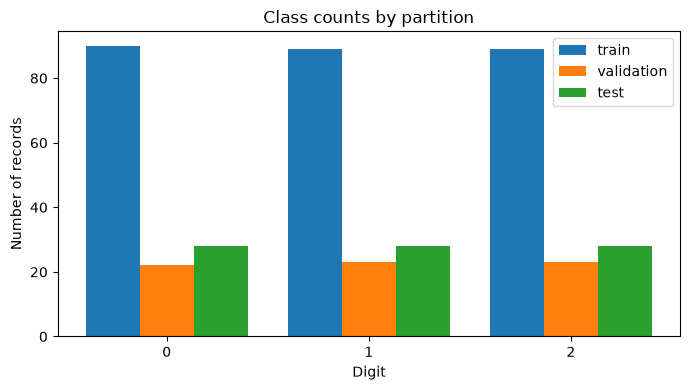

In [11]:
figure = plot_class_balance({name: getattr(selected_split, name).labels
                             for name in ("train", "validation", "test")})
figures["selected_fold_class_balance"] = figure
display(figure)
plt.close(figure)


### 4.4 Inspect clean training examples


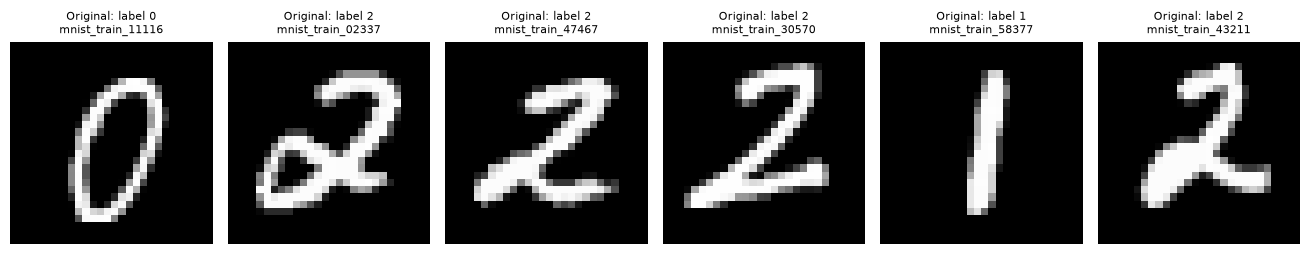

In [12]:
figure = plot_examples(selected_split.train, max_examples=6)
figures["clean_training_examples"] = figure
display(figure)
plt.close(figure)


### 4.5 Four PCA features

The classifier receives four angles, not all 784 pixel values. Every original
model fits its own PCA and scaler on its training inputs. Retained-data
retraining fits a new transformer after excluding exact forget records.
Unlearning keeps its parent's numeric features frozen.


In [13]:
from src.data.feature_randomization import UnitInputPreprocessor

if study is not None:
    features, pca_information, pca_view = workflow.cached_fold_features(study, ILLUSTRATION_FOLD)
else:
    preview_processor = UnitInputPreprocessor(SEED).fit(
        selected_split.train.images, selected_split.train.sample_ids,
    )
    features = {name: preview_processor.transform(getattr(selected_split, name).images)
                for name in ("train", "validation", "test")}
    pca_information = preview_processor.diagnostics()
    pca_view = preview_processor
display(pd.DataFrame([{ "partition": name, "shape": values.shape}
                      for name, values in features.items() if name in ("train", "validation", "test")]))


,partition,shape
0,train,"(268, 4)"
1,validation,"(68, 4)"
2,test,"(84, 4)"


### 4.6 How much variance do four components preserve?


,Saved or training-only PCA diagnostics
angle_range,"[0.0, 3.141593]"
clip,True
explained_variance_ratio,"[0.201136, 0.109493, 0.073744, 0.056095]"
input_policy,{'adaptation': 'Malik six-qubit angle circuit ...
n_fit_samples,268
total_explained_variance,0.440469


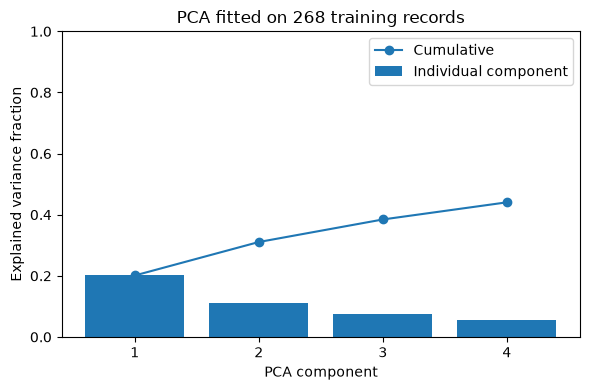

In [14]:
display(pd.Series(pca_information, name="Saved or training-only PCA diagnostics").to_frame())
figure = plot_pca_variance(pca_view)
figures["pca_variance"] = figure
display(figure)
plt.close(figure)


**Interpretation:** high explained variance does not guarantee that the features
preserve all class information. PCA is fitted without test labels. A discarded
pixel change may have little effect on model inputs; inspect the paired
corruption diagnostic in Section 9 before interpreting attack effectiveness.


## 5. Classical baselines on the same inputs

### 5.1 Purpose and recorded models

Majority, logistic regression, linear SVM, and RBF SVM provide context for the
four-feature representation. They are not prerequisites that the gold VQC must
outperform. Their preprocessing and split match the clean original VQC in each
fold. Classical models are saved with supervised fits, so review does not refit them.


In [15]:
gold_runs = workflow.clean_runs(study) if study is not None else {}
baseline_results = workflow.baseline_table(gold_runs)
if not baseline_results.empty:
    display(baseline_results.round(4))
else:
    print("Baselines will be available with the gold checkpoints in Section 7.")


,fold,model,run_id,accuracy,forget_confidence,forget_recall,forgotten_mass_on_retained,n_forget,n_retained,n_samples,retained_accuracy
0,0,linear_svm,none_p0_seed6304_fold0_3a9d03208c2974d8,0.9048,0.8222,0.8571,0.1077,28,56,84,0.9286
1,0,logistic,none_p0_seed6304_fold0_3a9d03208c2974d8,0.9048,0.8315,0.8929,0.0883,28,56,84,0.9107
2,0,majority,none_p0_seed6304_fold0_3a9d03208c2974d8,0.3333,0.0000,0.0000,0.0000,28,56,84,0.5000
3,0,gold_vqc,none_p0_seed6304_fold0_3a9d03208c2974d8,0.8690,0.4234,0.8571,0.2858,28,56,84,0.8750
4,0,rbf_svm,none_p0_seed6304_fold0_3a9d03208c2974d8,0.9524,0.8828,0.9286,0.0598,28,56,84,0.9643
5,1,linear_svm,none_p0_seed6304_fold1_ff54a9faf68b4fac,0.9524,0.7435,0.8571,0.0703,28,56,84,1.0000
6,1,logistic,none_p0_seed6304_fold1_ff54a9faf68b4fac,0.9405,0.8058,0.8571,0.0949,28,56,84,0.9821
7,1,majority,none_p0_seed6304_fold1_ff54a9faf68b4fac,0.3333,0.0000,0.0000,0.0000,28,56,84,0.5000
8,1,gold_vqc,none_p0_seed6304_fold1_ff54a9faf68b4fac,0.8452,0.4067,0.8214,0.2865,28,56,84,0.8571
9,1,rbf_svm,none_p0_seed6304_fold1_ff54a9faf68b4fac,0.9286,0.8197,0.8929,0.0672,28,56,84,0.9464


### 5.2 Compare folds without pooling reused clean models


In [16]:
if not baseline_results.empty:
    baseline_summary = baseline_results.groupby("model")[["accuracy", "retained_accuracy", "forget_recall"]].agg(
        ["mean", "std", "count"]
    )
    display(baseline_summary.round(4))


accuracy               retained_accuracy                \
               mean     std count              mean     std count   
model                                                               
gold_vqc     0.8619  0.0160     5            0.8714  0.0462     5   
linear_svm   0.9048  0.0386     5            0.9357  0.0889     5   
logistic     0.9000  0.0353     5            0.9179  0.0784     5   
majority     0.3333  0.0000     5            0.5000  0.0000     5   
rbf_svm      0.9333  0.0322     5            0.9429  0.0611     5   

           forget_recall                
                    mean     std count  
model                                   
gold_vqc          0.8429  0.0542     5  
linear_svm        0.8429  0.0822     5  
logistic          0.8643  0.0687     5  
majority          0.0000  0.0000     5  
rbf_svm           0.9143  0.0319     5

**Interpretation:** a gap between classical and quantum accuracy may reflect
the fixed architecture, optimizer, bounded logits, or representation. Fold
evaluation measures variation; it does not by itself explain the gap.


## 6. Quantum circuit and simulation budget

### 6.1 Draw the actual Malik-style circuit

Two feature-map reuploads each precede a three-repeat RY/RZ/CX ansatz. Six
qubits and 72 nominal angles are retained. Z expectations on qubits 3, 4, and 5
become three logits followed by softmax. This is an independent implementation
from the reported circuit and equations, not the authors' private repository.


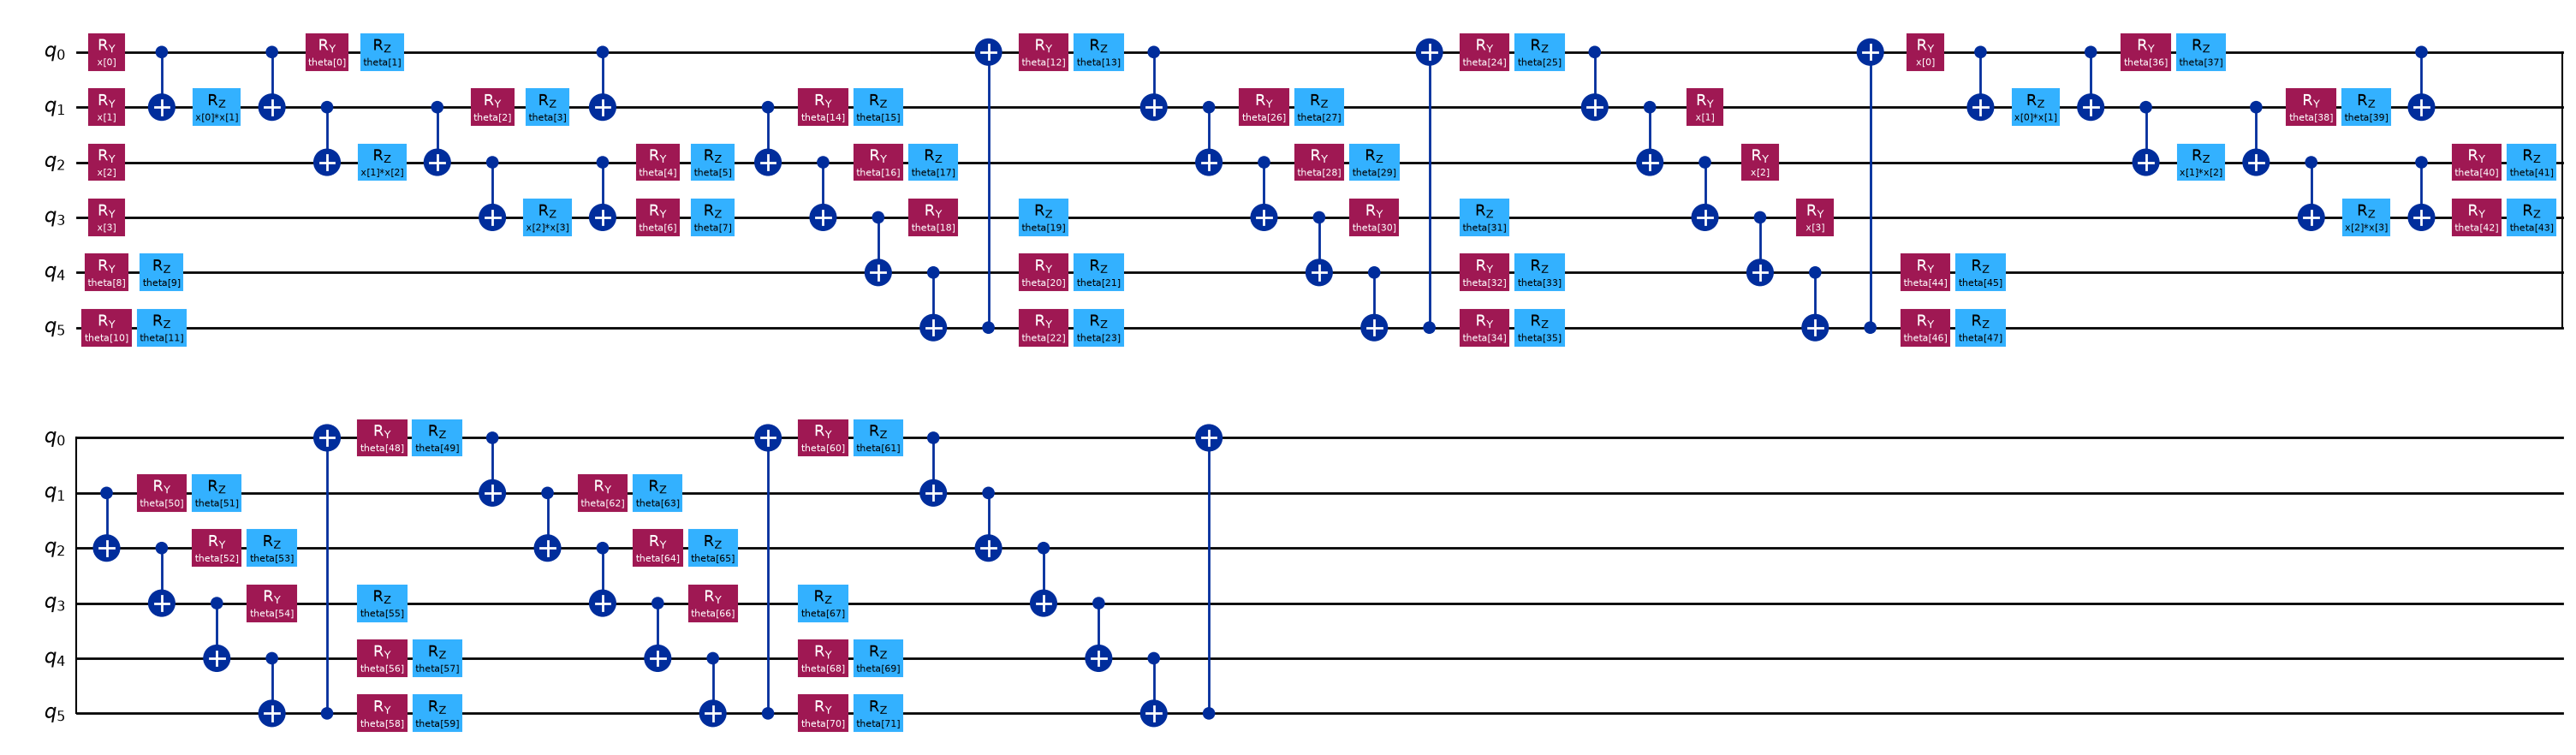

In [17]:
from src.models.circuits import build_malik_circuit, circuit_resources

circuit = build_malik_circuit(config.circuit)
figure = draw_circuit(circuit, fold=45)
figures["circuit"] = figure
display(figure)
plt.close(figure)


### 6.2 Count the resources


In [18]:
display(pd.Series(circuit_resources(circuit), name="Logical circuit").to_frame())
parameter_count = config.circuit.n_parameters
display(pd.Series({
    "nominal parameters": parameter_count,
    "expectation circuits per sample and full gradient": 1 + 2 * parameter_count,
    "batch size": config.training.batch_size,
    "supervised updates per fit": config.training.steps,
    "unlearning updates per fit": config.unlearning.training.steps,
}, name="Optimization work").to_frame())


,Logical circuit
qubits,6
depth,66
two_qubit_gates,48
operations,"{'cx': 48, 'ry': 44, 'rz': 42}"
parameters,76


,Optimization work
nominal parameters,72
expectation circuits per sample and full gradient,145
batch size,10
supervised updates per fit,300
unlearning updates per fit,100


### 6.3 Check the saved prediction format

Review reads existing three-class probabilities and checks their normalization.
It does not simulate a forward pass again. Training uses expectation-level
parameter shifts and the classical softmax/cross-entropy chain rule.


In [19]:
if gold_runs:
    saved_probabilities = gold_runs[ILLUSTRATION_FOLD]["predictions"]["model__test"]
    np.testing.assert_allclose(saved_probabilities.sum(axis=1), 1.0, atol=1e-10)
    display(pd.DataFrame(saved_probabilities[:5], columns=["p(0)", "p(1)", "p(2)"]))


,p(0),p(1),p(2)
0,0.220366,0.522017,0.257617
1,0.351516,0.276280,0.372204
2,0.359719,0.345222,0.295058
3,0.338630,0.345537,0.315833
4,0.260080,0.300246,0.439674


## 7. Clean gold reference model

### 7.1 Train or load the clean originals

The gold reference is the unpoisoned three-class classifier. In new execution,
fit clean originals across selected folds first. The main pipeline reuses these
same cache identities. Forced experiments defer this step to the full pipeline
so the gold models are fitted only once in the new attempt.


In [20]:
def show_progress(event):
    if "completed" in event:
        print(f"Completed {event['completed']}/{event['planned']}: {event.get('problem', '')}", flush=True)
    elif event.get("step") is not None:
        print(f"fold {event['fold']} {event['condition']} {event['role']}: "
              f"{event['step']}/{event['updates']}", flush=True)

if RUN_PRIMARY_STUDY and not FORCE_RETRAIN:
    gold_runs = workflow.train_gold_models(
        PROJECT_ROOT, splits, execution, config=config, label=STUDY_LABEL, progress=show_progress,
    )
gold = gold_runs.get(ILLUSTRATION_FOLD)


### 7.2 Learning curve and validation-selected checkpoint


,step,learning_rate,gradient_norm,elapsed_seconds,train_loss,validation_loss,model
26,260,0.00183,0.16385,278.65338,0.82327,0.84334,model
27,270,0.00147,0.13886,289.65449,0.82280,0.84367,model
28,280,0.00121,0.12941,300.56110,0.82242,0.84377,model
29,290,0.00105,0.13051,310.97219,0.82226,0.84381,model
30,300,0.00100,0.12861,321.53846,0.82211,0.84396,model


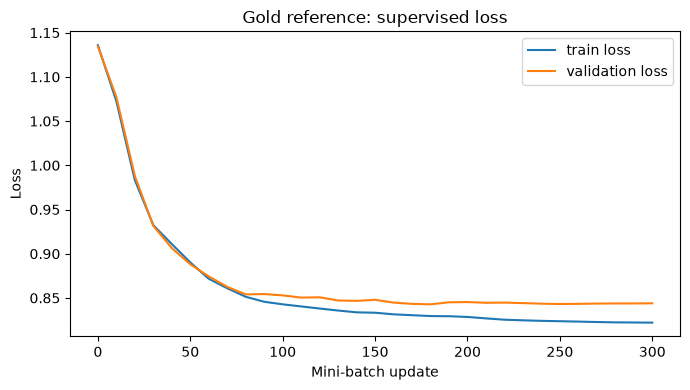

In [21]:
if gold is not None:
    display(gold["history"].tail().round(5))
    figure = plot_training_history(gold["history"], title="Gold reference: supervised loss")
    figures["gold_training_history"] = figure
    display(figure)
    plt.close(figure)


### 7.3 Gold versus classical baselines


In [22]:
baseline_results = workflow.baseline_table(gold_runs)
if not baseline_results.empty:
    display(baseline_results.round(4))
    display(baseline_results.groupby("model")[["accuracy", "retained_accuracy", "forget_recall"]].agg(
        ["mean", "std", "count"]
    ).round(4))


,fold,model,run_id,accuracy,forget_confidence,forget_recall,forgotten_mass_on_retained,n_forget,n_retained,n_samples,retained_accuracy
0,0,linear_svm,none_p0_seed6304_fold0_3a9d03208c2974d8,0.9048,0.8222,0.8571,0.1077,28,56,84,0.9286
1,0,logistic,none_p0_seed6304_fold0_3a9d03208c2974d8,0.9048,0.8315,0.8929,0.0883,28,56,84,0.9107
2,0,majority,none_p0_seed6304_fold0_3a9d03208c2974d8,0.3333,0.0000,0.0000,0.0000,28,56,84,0.5000
3,0,gold_vqc,none_p0_seed6304_fold0_3a9d03208c2974d8,0.8690,0.4234,0.8571,0.2858,28,56,84,0.8750
4,0,rbf_svm,none_p0_seed6304_fold0_3a9d03208c2974d8,0.9524,0.8828,0.9286,0.0598,28,56,84,0.9643
5,1,linear_svm,none_p0_seed6304_fold1_ff54a9faf68b4fac,0.9524,0.7435,0.8571,0.0703,28,56,84,1.0000
6,1,logistic,none_p0_seed6304_fold1_ff54a9faf68b4fac,0.9405,0.8058,0.8571,0.0949,28,56,84,0.9821
7,1,majority,none_p0_seed6304_fold1_ff54a9faf68b4fac,0.3333,0.0000,0.0000,0.0000,28,56,84,0.5000
8,1,gold_vqc,none_p0_seed6304_fold1_ff54a9faf68b4fac,0.8452,0.4067,0.8214,0.2865,28,56,84,0.8571
9,1,rbf_svm,none_p0_seed6304_fold1_ff54a9faf68b4fac,0.9286,0.8197,0.8929,0.0672,28,56,84,0.9464


accuracy               retained_accuracy                \
               mean     std count              mean     std count   
model                                                               
gold_vqc     0.8619  0.0160     5            0.8714  0.0462     5   
linear_svm   0.9048  0.0386     5            0.9357  0.0889     5   
logistic     0.9000  0.0353     5            0.9179  0.0784     5   
majority     0.3333  0.0000     5            0.5000  0.0000     5   
rbf_svm      0.9333  0.0322     5            0.9429  0.0611     5   

           forget_recall                
                    mean     std count  
model                                   
gold_vqc          0.8429  0.0542     5  
linear_svm        0.8429  0.0822     5  
logistic          0.8643  0.0687     5  
majority          0.0000  0.0000     5  
rbf_svm           0.9143  0.0319     5

### 7.4 Digit-wise errors


In [23]:
if gold is not None:
    gold_metrics = gold["metrics"]["models"]["model"]
    display(pd.Series(gold_metrics["recall_by_class"], name="Test recall by digit").to_frame())
    display(pd.Series({name: gold_metrics[name] for name in
                       ("accuracy", "retained_accuracy", "forget_recall", "forget_confidence")},
                      name="Gold reference").to_frame())


,Test recall by digit
0,0.892857
1,0.857143
2,0.857143


,Gold reference
accuracy,0.869048
retained_accuracy,0.875000
forget_recall,0.857143
forget_confidence,0.423447


### 7.5 Confusion matrix


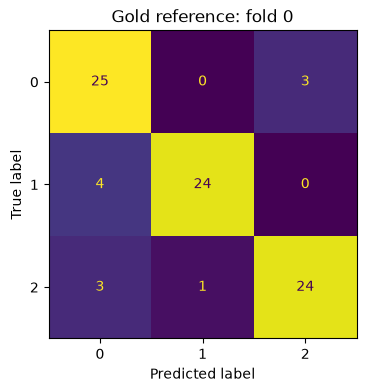

In [24]:
if gold is not None:
    from sklearn.metrics import ConfusionMatrixDisplay
    figure, axis = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay(np.asarray(gold_metrics["confusion_matrix"]), display_labels=[0, 1, 2]).plot(
        ax=axis, colorbar=False,
    )
    axis.set_title(f"Gold reference: fold {ILLUSTRATION_FOLD}")
    figures["gold_confusion"] = figure
    display(figure)
    plt.close(figure)


### 7.6 Recorded execution resources


In [25]:
if gold is not None:
    gold_resources = artifacts.load_json(gold["path"] / "resources.json")
    display(pd.Series(gold_resources, name="Recorded training resources").to_frame())
    display(pd.Series(artifacts.load_json(gold["path"] / "checkpoints/model.json"),
                      name="Selected checkpoint").to_frame())


,Recorded training resources
ablation_execution,"{'circuit_batch_size': 32768, 'device': 'GPU',..."
actual_device,GPU
actual_method,statevector
available_aer_devices,"[CPU, GPU]"
compiled_circuit,"{'depth': 66, 'operations': {'cx': 48, 'ry': 4..."
expectation_mode,exact
fallback_reason,None
ibm_job_ids,[]
logit_scale,1.0
nominal_trainable_parameters,72


,Selected checkpoint
best_score,0.842806
best_step,180
selection_metric,validation_loss


## 8. Baseline interpretation and output handling

The clean gold model establishes utility before poisoning and unlearning.
Its accuracy is not evidence of successful forgetting. No new research scores
are supplied by this notebook until saved artifacts are restored or a stage is
actually executed. Figures are kept in memory for the separate exports in Section 14.


In [26]:
display(pd.DataFrame([
    {"item": "Gold originals available", "count": len(gold_runs)},
    {"item": "Planned folds", "count": len(STUDY_FOLDS)},
    {"item": "Inline figures prepared", "count": len(figures)},
]))


,item,count
0,Gold originals available,5
1,Planned folds,5
2,Inline figures prepared,6


## 9. Poisoned-data preparation

### 9.1 Conditions and rate denominator

Use clean training, digit-2 feature randomization, and label flipping from 0 to 2.
Primary rates are 5%, 10%, 20%, 30%, 40%, and 50%. Additional 25% conditions
support the ablations. Rates refer to the eligible class, rounded down, so the
percentage of the entire training set is smaller. Validation and test stay clean.


In [27]:
from src.data.feature_randomization import feature_variant, experiment_config, INPUT_POLICY
from src.data.poisoning import forget_mask

configs = condition_configs(config, STUDY_FOLDS)
if study is not None:
    configs = {(c["config"]["data"]["fold"], name.split("_", 2)[2]): experiment_config(c["config"])
               for name, c in study.conditions.items()}
variants = {
    name: (workflow.restore_poison_variant(study, f"fold_{fold}_{name}", split=selected_split)
           if study is not None else feature_variant(selected_split.train, settings.poison))
    for (fold, name), settings in configs.items() if fold == ILLUSTRATION_FOLD
}
display(pd.DataFrame([{"condition": name, **variant.metadata()} for name, variant in variants.items()])[
    ["condition", "n_training", "eligible_count", "poisoned_count", "actual_fraction_eligible", "actual_fraction_all_training"]
])


,condition,n_training,eligible_count,poisoned_count,actual_fraction_eligible,actual_fraction_all_training
0,clean,268,89,0,0.000000,0.000000
1,feature_randomization_10pct,268,89,8,0.089888,0.029851
2,feature_randomization_20pct,268,89,17,0.191011,0.063433
3,feature_randomization_25pct,268,89,22,0.247191,0.082090
4,feature_randomization_30pct,268,89,26,0.292135,0.097015
5,feature_randomization_40pct,268,89,35,0.393258,0.130597
6,feature_randomization_50pct,268,89,44,0.494382,0.164179
7,feature_randomization_5pct,268,89,4,0.044944,0.014925
8,label_flip_10pct,268,90,9,0.100000,0.033582
9,label_flip_20pct,268,90,18,0.200000,0.067164


### 9.2 Preserve original identities

Every record keeps its sample ID, original label, observed label, poison flag,
and seed. A selected record is corrupted only in training. The saved annotated
dataset can therefore be matched to the exact fold and poisoning setting.


In [28]:
variant = variants["feature_randomization_50pct"]
display(variant.manifest().head(10))
assert set(variant.observed.sample_ids) == set(selected_split.train.sample_ids)
assert not set(variant.observed.sample_ids) & set(selected_split.test.sample_ids)


,sample_id,original_label,observed_label,is_poisoned,poison_type,poison_seed
0,mnist_train_11116,0,0,False,none,6304
1,mnist_train_02337,2,2,True,feature_randomization,6304
2,mnist_train_47467,2,2,False,none,6304
3,mnist_train_30570,2,2,True,feature_randomization,6304
4,mnist_train_58377,1,1,False,none,6304
5,mnist_train_43211,2,2,True,feature_randomization,6304
6,mnist_train_13875,1,1,False,none,6304
7,mnist_train_28904,0,0,False,none,6304
8,mnist_train_12746,1,1,False,none,6304
9,mnist_train_02957,1,1,False,none,6304


### 9.3 Feature randomization

For selected digit-2 records, replace the complete 784-dimensional input with
a real Gaussian vector, then normalize it to unit length. Labels remain 2.
Signed entries are intentional; this is a feature surrogate, not a natural
grayscale image. Do not clip its negative values before PCA. All inputs use
the same unit-normalization policy. The previous corner patch is superseded.


,Input policy
version,real_gaussian_unit_input_v1
replacement,"full 784-vector, real N(0, 0.1**2), then unit ..."
eligible_class,2
labels_preserved,True
normalization,all clean/corrupt inputs divided by 255 then p...
zero_input,leave a zero vector unchanged
pca,four components; fit on the model's training r...
angle_scaling,"training-fitted MinMaxScaler [0, pi], clip=True"
adaptation,Malik six-qubit angle circuit and class-level ...
source,https://github.com/yutuer21/quantum-machine-un...


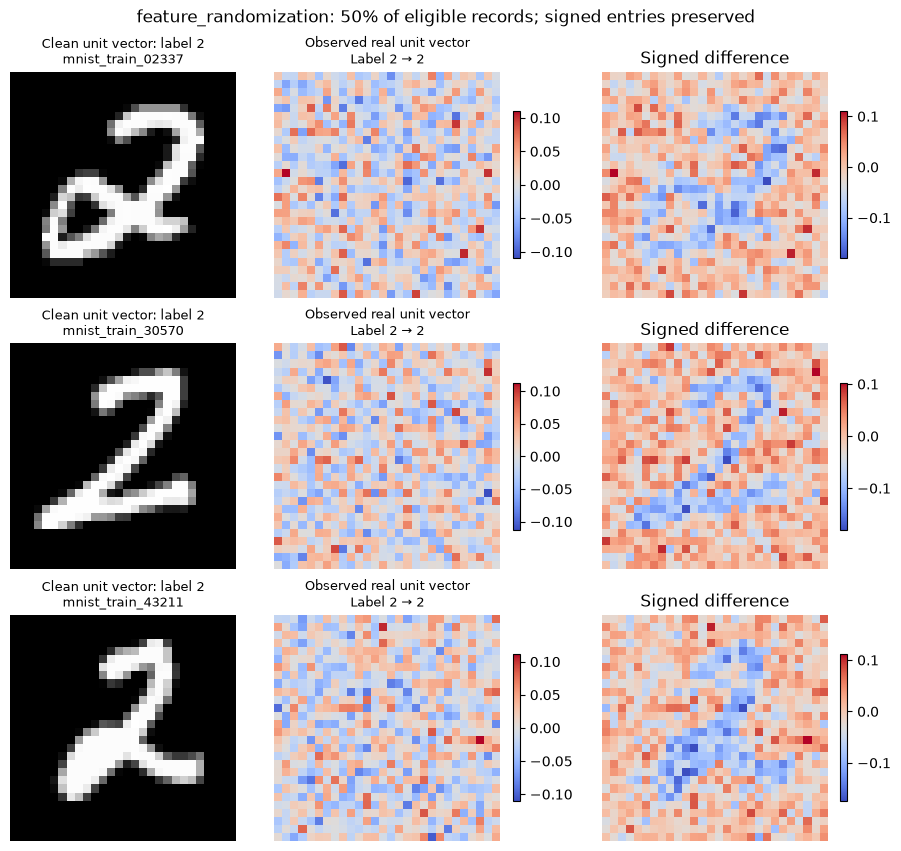

In [29]:
display(pd.Series(INPUT_POLICY, name="Input policy").to_frame())
figure = fresh_analysis.plot_feature_examples(variants["feature_randomization_50pct"])
figures["feature_randomization_examples"] = figure
display(figure)
plt.close(figure)


### 9.4 Label flipping

Selected digit-0 images keep their pixels and IDs, but their observed label
becomes 2. Pixel differences are therefore zero for this attack. It changes
the feature-label association rather than the input features.


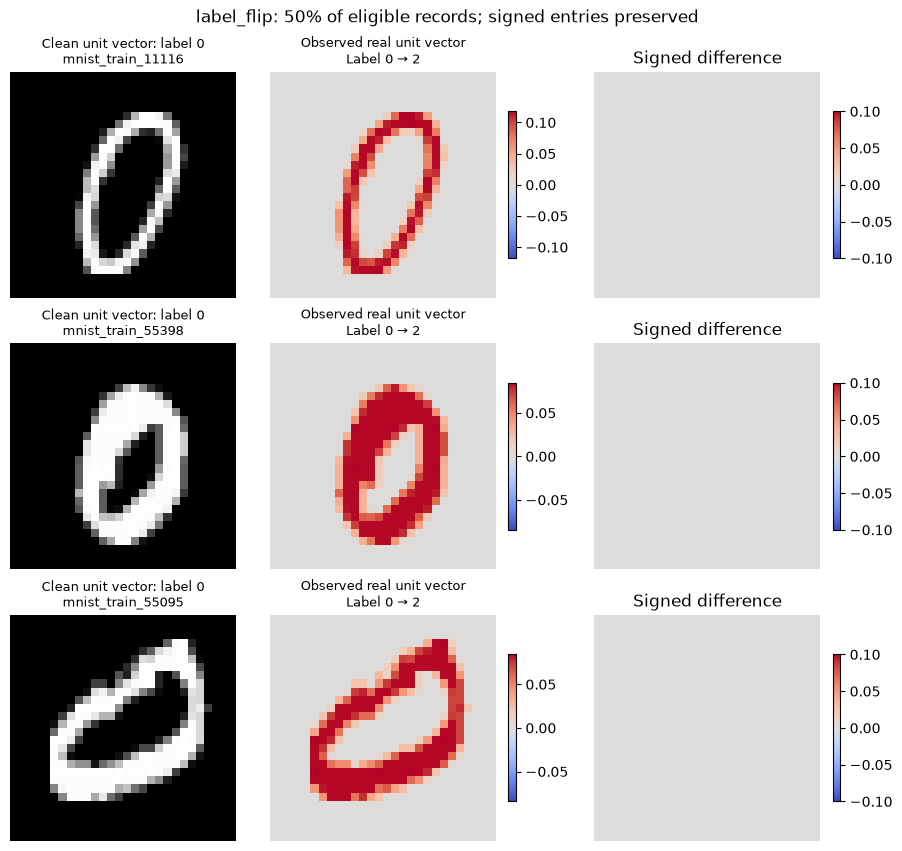

In [30]:
figure = fresh_analysis.plot_feature_examples(variants["label_flip_50pct"])
figures["label_flip_examples"] = figure
display(figure)
plt.close(figure)


### 9.5 Verify unchanged validation and test data


In [31]:
for name, variant in variants.items():
    np.testing.assert_array_equal(variant.original.sample_ids, variant.observed.sample_ids)
    if variant.config.kind == "label_flip":
        np.testing.assert_array_equal(variant.original.images, variant.observed.images)
    else:
        np.testing.assert_array_equal(variant.original.labels, variant.observed.labels)
print("Training-only variants aligned. Validation and test objects were not modified.")


Training-only variants aligned. Validation and test objects were not modified.


### 9.6 Inspect observed class balance


In [32]:
poison_balance = pd.DataFrame([
    {"condition": name, **{f"observed_digit_{digit}": int((variant.observed.labels == digit).sum())
                           for digit in (0, 1, 2)}}
    for name, variant in variants.items()
])
display(poison_balance)


,condition,observed_digit_0,observed_digit_1,observed_digit_2
0,clean,90,89,89
1,feature_randomization_10pct,90,89,89
2,feature_randomization_20pct,90,89,89
3,feature_randomization_25pct,90,89,89
4,feature_randomization_30pct,90,89,89
5,feature_randomization_40pct,90,89,89
6,feature_randomization_50pct,90,89,89
7,feature_randomization_5pct,90,89,89
8,label_flip_10pct,81,89,98
9,label_flip_20pct,72,89,107


### 9.7 Does the corruption reach four-angle model inputs?

This paired diagnostic transforms clean and corrupted records through frozen
clean PCA. Label flipping must have zero input change. Feature randomization
should change inputs, but a nonzero change does not establish harmful training.
Saved review loads the recorded diagnostic, and never refits a missing one.


In [33]:
if study is not None:
    input_effects = workflow.saved_input_diagnostics(study)
else:
    input_effects, _ = fresh_analysis.input_diagnostics(configs, splits)
if input_effects.empty:
    print("No saved input diagnostic is available. Review will not refit PCA to replace it.")
else:
    display(input_effects.round(5))


No saved input diagnostic is available. Review will not refit PCA to replace it.


### 9.7.1 Plot the paired feature changes


In [34]:
if not input_effects.empty:
    figure = fresh_analysis.diagnostic_figure(input_effects)
    figures["input_changes"] = figure
    display(figure)
    plt.close(figure)


### 9.8 Exact forget-set membership

Forgetting is class-level: all observed-label-2 training records are designated
for forgetting. Under label flipping, this includes the flipped zeros.
Matched retained-data retraining removes these exact records. This experiment
does not identify and erase only the poisoned samples.


In [35]:
forget_membership = pd.DataFrame([
    {"condition": name, "forget_records": int(forget_mask(variant).sum()),
     "retained_records": int((~forget_mask(variant)).sum()),
     "poisoned_forget_records": int((forget_mask(variant) & variant.is_poisoned).sum())}
    for name, variant in variants.items()
])
display(forget_membership)


,condition,forget_records,retained_records,poisoned_forget_records
0,clean,89,179,0
1,feature_randomization_10pct,89,179,8
2,feature_randomization_20pct,89,179,17
3,feature_randomization_25pct,89,179,22
4,feature_randomization_30pct,89,179,26
5,feature_randomization_40pct,89,179,35
6,feature_randomization_50pct,89,179,44
7,feature_randomization_5pct,89,179,4
8,label_flip_10pct,98,170,9
9,label_flip_20pct,107,161,18


### 9.9 Storage locations

The training runner creates `data/annotated/`, `data/splits/`, model run folders,
and condition manifests on demand. Review reconstructs previews in memory
and does not overwrite saved training data. Raw MNIST remains in `data/raw/`.


In [36]:
if study is not None:
    condition = study.conditions[f"fold_{ILLUSTRATION_FOLD}_label_flip_50pct"]
    display(pd.Series({name: condition[name] for name in ("split_manifest", "annotated_dataset")},
                      name="Saved data links").to_frame())


,Saved data links
split_manifest,data/splits/split_6111a0f461545381.json
annotated_dataset,data/annotated/label_flip_p50_6c715323497ca70d


### 9.10 Interpretation before model evaluation

Attack strength must be measured from the trained models, not inferred from
the appearance of corrupted inputs. A robust original classifier is a valid
finding. Keep all tested conditions rather than selecting only damaging ones.


## 10. Poisoned training and matched retained-data references

### 10.1 Planned fitting work

The primary pipeline also prepares 25% support conditions for ablations.
Identical clean retained-data problems are cached once per fold. All fits
start from reproducible initialization; guided and uniform methods later
restart from the same trained original.


In [37]:
primary_plan = study_plan(config, STUDY_FOLDS)
display(primary_plan.groupby(["stage", "updates"]).size().rename("planned_fits").to_frame())
print("Planned primary and support fits:", len(primary_plan))
print("Counts describe planned work, not completed experiments.")


,,planned_fits
stage,updates,
supervised,300,115
unlearning,100,150


Planned primary and support fits: 265
Counts describe planned work, not completed experiments.


### 10.2 Preprocessing of the retraining references

Each retained-data reference refits PCA and scaling on its own remaining
records. Feature randomization preserves labels, so its retained training
problem equals the clean retained problem and is reused. Label flips remove
some additional original zeros, so their retraining references can differ.
Unlearning uses the original model's features and fixed teachers throughout.


### 10.3 Complete or load the primary pipeline

This runner stages the remaining original/reference fits followed by default
guided and uniform unlearning (100 updates each). The complete sequence uses
one protocol and separate per-model checkpoints. Existing clean gold fits from
Section 7 are reused. With training disabled, this cell only selects the saved
study that was already verified in Section 3.

The guided objective is forget-target cross-entropy + alpha times soft-anchor
cross-entropy + lambda times squared distance to the original parameters.
Its global target and original anchor predictions stay fixed. Section 11
inspects those targets and the resulting tradeoffs.


In [38]:
if RUN_PRIMARY_STUDY:
    from src.fresh_study import run_fresh_study
    study, study_index = run_fresh_study(
        PROJECT_ROOT, splits, execution, base=config, label=STUDY_LABEL,
        force_retrain=FORCE_RETRAIN, progress=show_progress,
    )
primary_study = study.select_rates(PRIMARY_RATES)
gold_runs = workflow.clean_runs(study)
gold = gold_runs[ILLUSTRATION_FOLD]
print("Completed unique cached fits:", len(study.runs))
print("Study:", study.report_path.relative_to(PROJECT_ROOT))


Completed unique cached fits: 265
Study: results\fresh_studies\fa1604cdd38207d9\study.json


### 10.4 Build tables from saved numeric results


In [39]:
tables = fresh_analysis.study_tables(primary_study)
selected_metrics = tables["metrics"][tables["metrics"].fold == ILLUSTRATION_FOLD]
original_roles = ("clean", "poisoned", "retrained_clean", "retrained_poisoned")
display(selected_metrics[selected_metrics.model.isin(original_roles)][
    ["attack", "poison_rate", "model", "accuracy", "retained_accuracy", "forget_recall", "forget_confidence"]
].round(4))


,attack,poison_rate,model,accuracy,retained_accuracy,forget_recall,forget_confidence
3,none,0.00,clean,0.8690,0.8750,0.8571,0.4234
8,none,0.00,poisoned,0.8690,0.8750,0.8571,0.4234
10,none,0.00,retrained_clean,0.6786,1.0000,0.0357,0.2924
11,none,0.00,retrained_poisoned,0.6786,1.0000,0.0357,0.2924
19,feature_randomization,0.10,clean,0.8690,0.8750,0.8571,0.4234
24,feature_randomization,0.10,poisoned,0.8929,0.9286,0.8214,0.3995
26,feature_randomization,0.10,retrained_clean,0.6786,1.0000,0.0357,0.2924
27,feature_randomization,0.10,retrained_poisoned,0.6786,1.0000,0.0357,0.2924
35,feature_randomization,0.20,clean,0.8690,0.8750,0.8571,0.4234
40,feature_randomization,0.20,poisoned,0.9048,0.9464,0.8214,0.4297


### 10.5 Separate poisoning damage from unlearning changes


In [40]:
display(tables["effects"][tables["effects"].fold == ILLUSTRATION_FOLD][
    ["attack", "poison_rate", "method", "metric", "poisoning_damage_before",
     "clean_unlearning_change", "poisoned_unlearning_change", "additional_change_under_poisoning"]
].round(4))


,attack,poison_rate,method,metric,poisoning_damage_before,clean_unlearning_change,poisoned_unlearning_change,additional_change_under_poisoning
0,none,0.00,guided,retained_accuracy,0.000,-0.0714,-0.0714,0.0000
1,none,0.00,guided,forget_confidence,0.000,-0.1787,-0.1787,0.0000
2,none,0.00,guided,forget_recall,0.000,-0.8571,-0.8571,0.0000
3,none,0.00,uniform,retained_accuracy,0.000,-0.0714,-0.0714,0.0000
4,none,0.00,uniform,forget_confidence,0.000,-0.1763,-0.1763,0.0000
...,...,...,...,...,...,...,...,...
73,label_flip,0.05,guided,forget_confidence,-0.001,-0.1787,-0.1822,-0.0035
74,label_flip,0.05,guided,forget_recall,0.000,-0.8571,-0.8571,0.0000
75,label_flip,0.05,uniform,retained_accuracy,0.000,-0.0714,-0.1250,-0.0536
76,label_flip,0.05,uniform,forget_confidence,-0.001,-0.1763,-0.1802,-0.0039


**Interpretation:** a poisoned model can already have poor digit-2 recall
before unlearning. Attribute only the paired before-to-after change to the
unlearning step. A retained-data reference is an evaluation target, not the
unpoisoned three-class gold reference.


## 11. Guided and uniform unlearning

### 11.1 Fixed targets and retained anchors

For calibration records from the training forget set, average the original
probabilities, remove class 2, raise retained entries to beta, and normalize.
This gives one global target q. Cache the original soft predictions on a
training-only retained anchor subset. Defaults: alpha=1, lambda=0.01, beta=1,
anchor fraction=0.25. Uniform uses q=(0.5, 0.5, 0).


In [41]:
display(tables["targets"][tables["targets"].fold == ILLUSTRATION_FOLD].round(5))


,condition,attack,poison_rate,seed,fold,realized_training_fraction,realized_eligible_fraction,model,target_0,target_1,target_2,anchor_accuracy_observed_labels,anchor_accuracy_original_labels,n_anchors,n_calibration,n_forget
0,fold_0_clean,none,0.00,6304,0,0.00000,0.00000,clean_guided,0.52234,0.47766,0.0,0.86957,0.86957,46,32,89
1,fold_0_clean,none,0.00,6304,0,0.00000,0.00000,clean_uniform,0.50000,0.50000,0.0,0.86957,0.86957,46,32,89
2,fold_0_clean,none,0.00,6304,0,0.00000,0.00000,poisoned_guided,0.52234,0.47766,0.0,0.86957,0.86957,46,32,89
3,fold_0_clean,none,0.00,6304,0,0.00000,0.00000,poisoned_uniform,0.50000,0.50000,0.0,0.86957,0.86957,46,32,89
4,fold_0_feature_randomization_10pct,feature_randomization,0.10,6304,0,0.02985,0.08989,clean_guided,0.52234,0.47766,0.0,0.86957,0.86957,46,32,89
5,fold_0_feature_randomization_10pct,feature_randomization,0.10,6304,0,0.02985,0.08989,clean_uniform,0.50000,0.50000,0.0,0.86957,0.86957,46,32,89
6,fold_0_feature_randomization_10pct,feature_randomization,0.10,6304,0,0.02985,0.08989,poisoned_guided,0.50669,0.49331,0.0,0.95652,0.95652,46,32,89
7,fold_0_feature_randomization_10pct,feature_randomization,0.10,6304,0,0.02985,0.08989,poisoned_uniform,0.50000,0.50000,0.0,0.95652,0.95652,46,32,89
8,fold_0_feature_randomization_20pct,feature_randomization,0.20,6304,0,0.06343,0.19101,clean_guided,0.52234,0.47766,0.0,0.86957,0.86957,46,32,89
9,fold_0_feature_randomization_20pct,feature_randomization,0.20,6304,0,0.06343,0.19101,clean_uniform,0.50000,0.50000,0.0,0.86957,0.86957,46,32,89


### 11.2 Checkpoints and teacher quality

Guided and uniform start from identical original weights. Teachers are frozen
before optimization, not refreshed from the changing student. The anchor term
preserves the original behavior, including any errors it already contains.


In [42]:
display(tables["checkpoints"][tables["checkpoints"].fold == ILLUSTRATION_FOLD].head(16))
display(tables["targets"].groupby(["attack", "poison_rate", "model"])[
    ["target_0", "target_1", "target_2"]
].mean().round(5))


,condition,attack,poison_rate,seed,fold,realized_training_fraction,realized_eligible_fraction,model,run_id,best_score,best_step,selection_metric
0,fold_0_clean,none,0.0,6304,0,0.000000,0.000000,clean,none_p0_seed6304_fold0_3a9d03208c2974d8,0.842806,180,validation_loss
1,fold_0_clean,none,0.0,6304,0,0.000000,0.000000,poisoned,none_p0_seed6304_fold0_3a9d03208c2974d8,0.842806,180,validation_loss
2,fold_0_clean,none,0.0,6304,0,0.000000,0.000000,retrained_clean,none_p0_seed6304_fold0_a4438ecb8cfae905,0.768926,270,validation_loss
3,fold_0_clean,none,0.0,6304,0,0.000000,0.000000,retrained_poisoned,none_p0_seed6304_fold0_a4438ecb8cfae905,0.768926,270,validation_loss
4,fold_0_clean,none,0.0,6304,0,0.000000,0.000000,clean_guided,none_p0_seed6304_fold0_70cec1774dedfc31,2.088723,100,objective
5,fold_0_clean,none,0.0,6304,0,0.000000,0.000000,clean_uniform,none_p0_seed6304_fold0_a107614cc355fb3e,2.092350,100,objective
6,fold_0_clean,none,0.0,6304,0,0.000000,0.000000,poisoned_guided,none_p0_seed6304_fold0_70cec1774dedfc31,2.088723,100,objective
7,fold_0_clean,none,0.0,6304,0,0.000000,0.000000,poisoned_uniform,none_p0_seed6304_fold0_a107614cc355fb3e,2.092350,100,objective
8,fold_0_feature_randomization_10pct,feature_randomization,0.1,6304,0,0.029851,0.089888,clean,none_p0_seed6304_fold0_3a9d03208c2974d8,0.842806,180,validation_loss
9,fold_0_feature_randomization_10pct,feature_randomization,0.1,6304,0,0.029851,0.089888,poisoned,none_p0_seed6304_fold0_5a92c7b85c0ff3e1,0.814702,300,validation_loss


target_0  target_1  \
attack                poison_rate model                                  
feature_randomization 0.05        clean_guided       0.52657   0.47343   
                                  clean_uniform      0.50000   0.50000   
                                  poisoned_guided    0.48281   0.51719   
                                  poisoned_uniform   0.50000   0.50000   
                      0.10        clean_guided       0.52657   0.47343   
                                  clean_uniform      0.50000   0.50000   
                                  poisoned_guided    0.49292   0.50708   
                                  poisoned_uniform   0.50000   0.50000   
                      0.20        clean_guided       0.52657   0.47343   
                                  clean_uniform      0.50000   0.50000   
                                  poisoned_guided    0.51088   0.48912   
                                  poisoned_uniform   0.50000   0.50000   
                      0.30        clean_guided       0.52657   0.47343   
                                  clean_uniform      0.50000   0.50000   
                                  poisoned_guided    0.50996   0.49004   
                                  poisoned_uniform   0.50000   0.50000   
                      0.40        clean_guided       0.52657   0.47343   
                                  clean_uniform      0.50000   0.50000   
                                  poisoned_guided    0.50697   0.49303   
                                  poisoned_uniform   0.50000   0.50000   
                      0.50        clean_guided       0.52657   0.47343   
                                  clean_uniform      0.50000   0.50000   
                                  poisoned_guided    0.51194   0.48806   
                                  poisoned_uniform   0.50000   0.50000   
label_flip            0.05        clean_guided       0.52657   0.47343   
                                  clean_uniform      0.50000   0.50000   
                                  poisoned_guided    0.52710   0.47290   
                                  poisoned_uniform   0.50000   0.50000   
                      0.10        clean_guided       0.52657   0.47343   
                                  clean_uniform      0.50000   0.50000   
                                  poisoned_guided    0.51909   0.48091   
                                  poisoned_uniform   0.50000   0.50000   
                      0.20        clean_guided       0.52657   0.47343   
                                  clean_uniform      0.50000   0.50000   
                                  poisoned_guided    0.51723   0.48277   
                                  poisoned_uniform   0.50000   0.50000   
                      0.30        clean_guided       0.52657   0.47343   
                                  clean_uniform      0.50000   0.50000   
                                  poisoned_guided    0.53954   0.46046   
                                  poisoned_uniform   0.50000   0.50000   
                      0.40        clean_guided       0.52657   0.47343   
                                  clean_uniform      0.50000   0.50000   
                                  poisoned_guided    0.53407   0.46593   
                                  poisoned_uniform   0.50000   0.50000   
                      0.50        clean_guided       0.52657   0.47343   
                                  clean_uniform      0.50000   0.50000   
                                  poisoned_guided    0.53141   0.46859   
                                  poisoned_uniform   0.50000   0.50000   
none                  0.00        clean_guided       0.52657   0.47343   
                                  clean_uniform      0.50000   0.50000   
                                  poisoned_guided    0.52657   0.47343   
                                  poisoned_uniform   0.50000   0.50000   

                                                    tar

### 11.3 Retained utility, forgetting, and retraining agreement


In [43]:
unlearning_roles = ("poisoned_guided", "poisoned_uniform")
display(selected_metrics[selected_metrics.model.isin(unlearning_roles)][
    ["attack", "poison_rate", "model", "retained_accuracy", "forget_recall", "forget_confidence"]
].round(4))
display(tables["retraining"][tables["retraining"].fold == ILLUSTRATION_FOLD].round(5))


,attack,poison_rate,model,retained_accuracy,forget_recall,forget_confidence
14,none,0.00,poisoned_guided,0.8036,0.0000,0.2447
15,none,0.00,poisoned_uniform,0.8036,0.0000,0.2472
30,feature_randomization,0.10,poisoned_guided,0.7500,0.0714,0.2560
31,feature_randomization,0.10,poisoned_uniform,0.8036,0.0357,0.2502
46,feature_randomization,0.20,poisoned_guided,0.8929,0.0714,0.2279
47,feature_randomization,0.20,poisoned_uniform,0.8929,0.0714,0.2277
62,feature_randomization,0.30,poisoned_guided,0.7857,0.0357,0.2488
63,feature_randomization,0.30,poisoned_uniform,0.8214,0.0714,0.2490
78,feature_randomization,0.40,poisoned_guided,0.8929,0.0357,0.2749
79,feature_randomization,0.40,poisoned_uniform,0.8929,0.0357,0.2749


,condition,attack,poison_rate,seed,fold,realized_training_fraction,realized_eligible_fraction,model,kl_direction,evaluation_subset,full_kl_mean,conditional_kl_mean,conditional_kl_median,conditional_kl_max,reference_forgotten_mass,candidate_forgotten_mass
0,fold_0_clean,none,0.00,6304,0,0.00000,0.00000,clean,reference || candidate,clean retained test,0.01820,0.01664,0.00659,0.13209,0.26509,0.28583
1,fold_0_clean,none,0.00,6304,0,0.00000,0.00000,poisoned,reference || candidate,clean retained test,0.01820,0.01664,0.00659,0.13209,0.26509,0.28583
2,fold_0_clean,none,0.00,6304,0,0.00000,0.00000,clean_guided,reference || candidate,clean retained test,0.02235,0.02474,0.00891,0.13868,0.26509,0.28574
3,fold_0_clean,none,0.00,6304,0,0.00000,0.00000,clean_uniform,reference || candidate,clean retained test,0.02269,0.02460,0.00940,0.13829,0.26509,0.28864
4,fold_0_clean,none,0.00,6304,0,0.00000,0.00000,poisoned_guided,reference || candidate,clean retained test,0.02235,0.02474,0.00891,0.13868,0.26509,0.28574
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,fold_0_label_flip_5pct,label_flip,0.05,6304,0,0.01493,0.04444,poisoned,reference || candidate,clean retained test,0.01387,0.01404,0.00441,0.10942,0.27091,0.28682
74,fold_0_label_flip_5pct,label_flip,0.05,6304,0,0.01493,0.04444,clean_guided,reference || candidate,clean retained test,0.02235,0.02474,0.00891,0.13868,0.26509,0.28574
75,fold_0_label_flip_5pct,label_flip,0.05,6304,0,0.01493,0.04444,clean_uniform,reference || candidate,clean retained test,0.02269,0.02460,0.00940,0.13829,0.26509,0.28864
76,fold_0_label_flip_5pct,label_flip,0.05,6304,0,0.01493,0.04444,poisoned_guided,reference || candidate,clean retained test,0.02353,0.02490,0.01542,0.14270,0.27091,0.27773


### 11.4 Trajectories and confusion matrices

Inspect clean, 50% label-flip, and 50% feature-randomization conditions in the
illustration fold. The left loss axis is supervised validation loss; the right
axis is the unlearning objective. Their scales have different meanings.


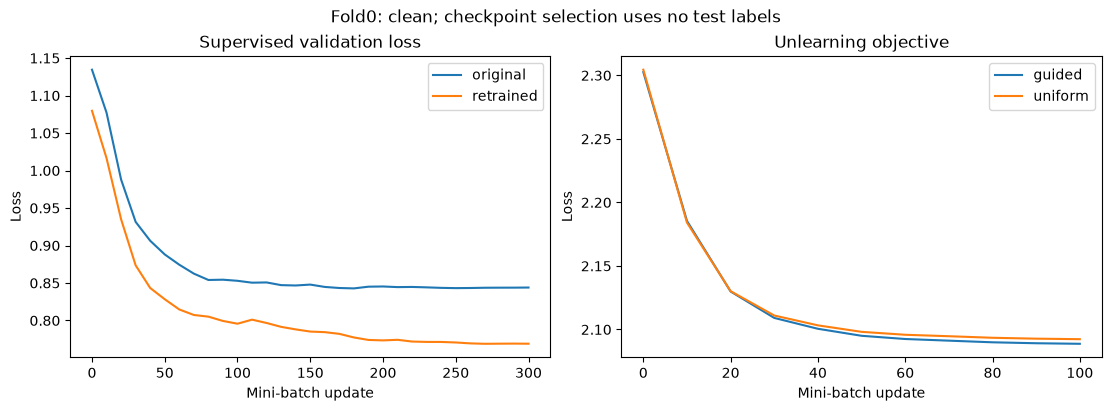

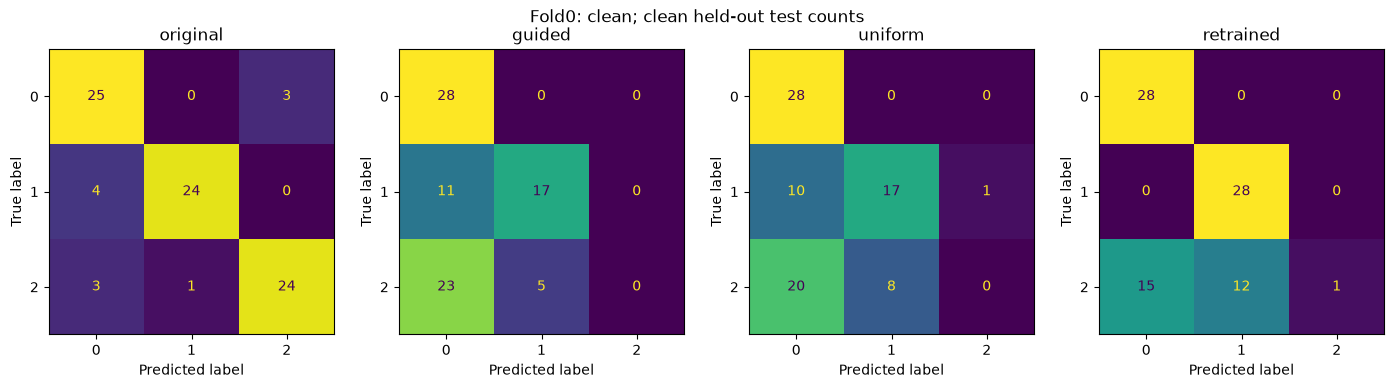

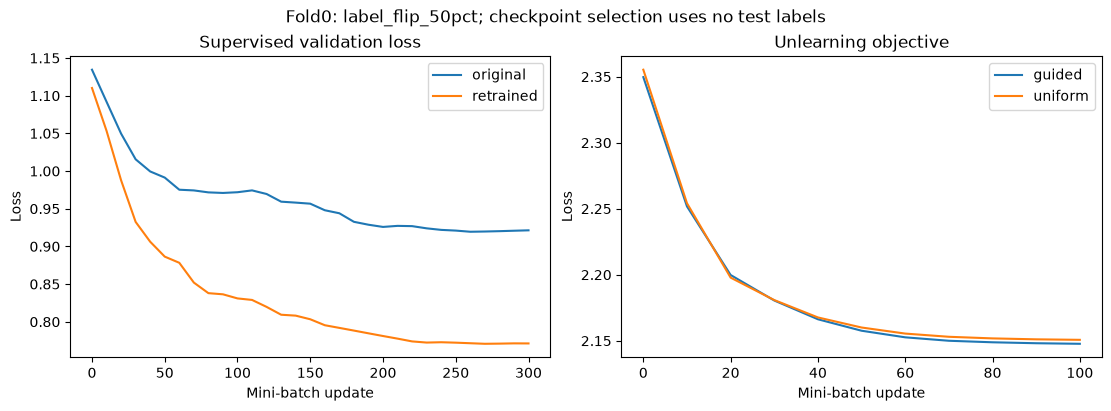

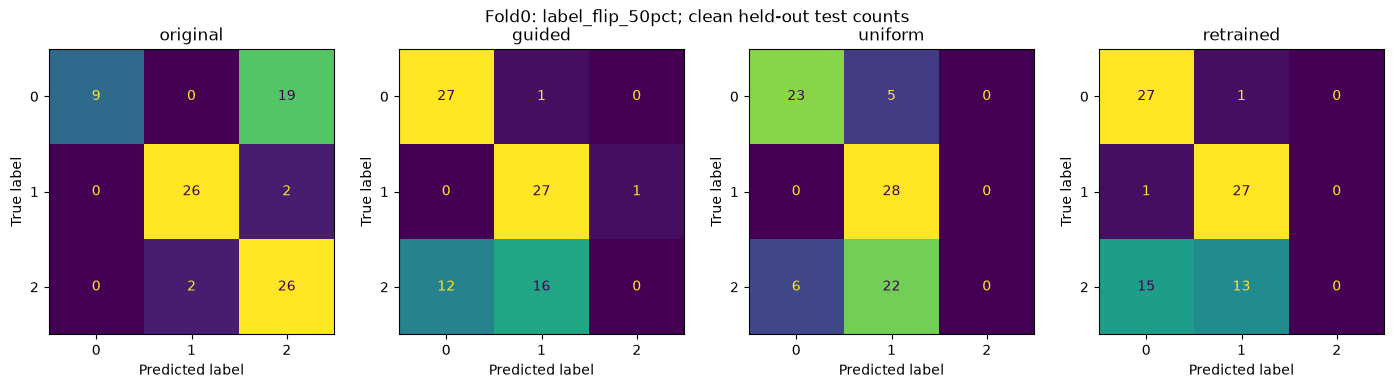

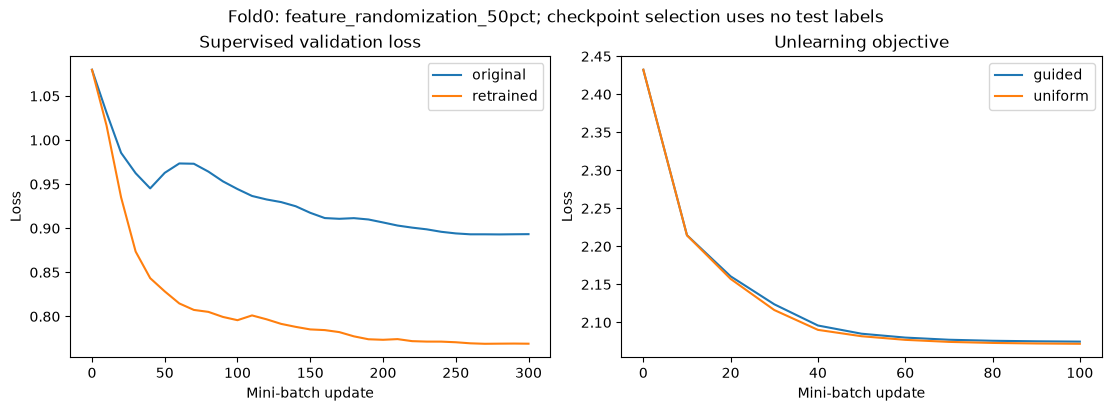

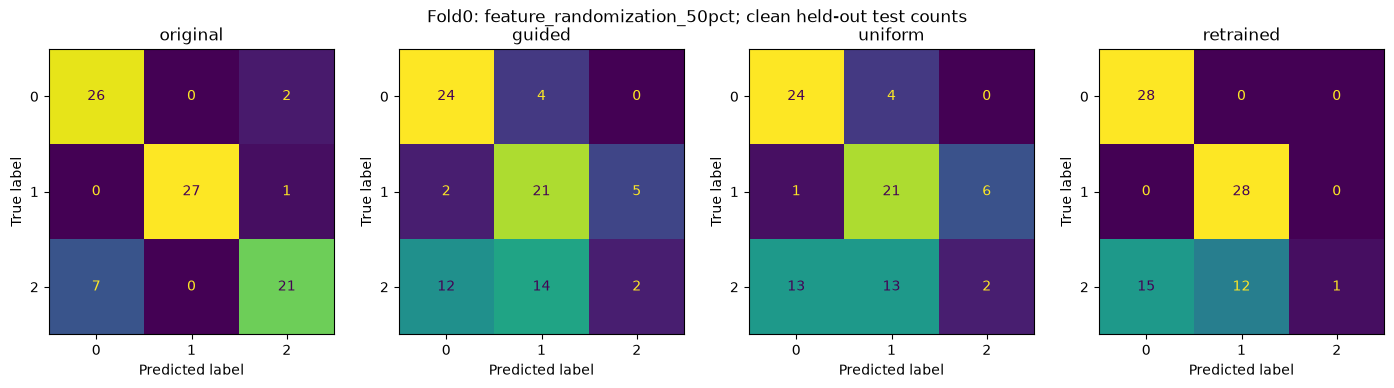

In [44]:
for name, figure in fresh_analysis.detailed_figures(primary_study, ILLUSTRATION_FOLD).items():
    figures[name] = figure
    display(figure)
    plt.close(figure)


### 11.5 Forgotten-class confidence on clean test examples


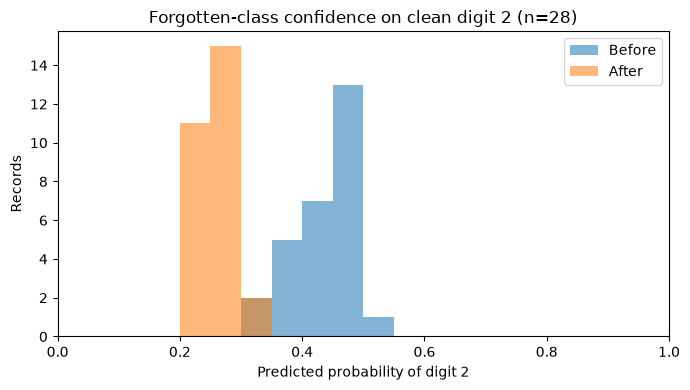

In [45]:
condition = primary_study.conditions[f"fold_{ILLUSTRATION_FOLD}_label_flip_50pct"]
before = condition["models"]["poisoned"]["predictions"]
after = condition["unlearned"]["poisoned_guided"]["predictions"]
figure = plot_forget_confidence(before["test_labels"], before["model__test"], after["model__test"])
figures["label_flip_guided_forget_confidence"] = figure
display(figure)
plt.close(figure)


### 11.6 Interpret the tradeoff

Lower forget recall and confidence, preserved digits 0/1, and better agreement
with matched retraining jointly support useful class-level forgetting. Softmax
of three logits bounded in [-1,1] cannot give exactly zero class probability.
Low conditional retained-class KL can also hide excess class-2 mass, so report
full KL and forgotten mass on retained records where available.


## 12. All-fold evidence and parameter/noise studies

### 12.1 Aggregate the five folds

Show mean, descriptive fold SD, valid fold count, and planned coverage. Shared
clean references are not extra observations. The 25% support conditions remain
separate from the six-rate primary curves.


In [46]:
fold_summary = tables["fold_summary"]
fold_effects = tables["fold_effects"]
quantum_roles = ("poisoned", "poisoned_guided", "poisoned_uniform", "retrained_poisoned")
display(fold_summary[fold_summary.model.isin(quantum_roles)].round(4))
display(fold_effects.round(4))
print("Incomplete metric rows:", int((~fold_summary.complete_folds).sum()))


,seed,attack,poison_rate,model,metric,mean,fold_sd,n_folds,expected_folds,complete_folds
28,6304,feature_randomization,0.05,poisoned,accuracy,0.8905,0.0528,5,5,True
29,6304,feature_randomization,0.05,poisoned,retained_accuracy,0.9036,0.0600,5,5,True
30,6304,feature_randomization,0.05,poisoned,forget_recall,0.8643,0.1023,5,5,True
31,6304,feature_randomization,0.05,poisoned,forget_confidence,0.4262,0.0174,5,5,True
32,6304,feature_randomization,0.05,poisoned_guided,accuracy,0.5643,0.0458,5,5,True
...,...,...,...,...,...,...,...,...,...,...
1595,6304,label_flip,0.50,retrained_poisoned,recall_digit_2,0.0929,0.1705,5,5,True
1603,6304,none,0.00,poisoned,recall_digit_2,0.8429,0.0542,5,5,True
1604,6304,none,0.00,poisoned_guided,recall_digit_2,0.0071,0.0160,5,5,True
1609,6304,none,0.00,poisoned_uniform,recall_digit_2,0.0071,0.0160,5,5,True


,seed,attack,poison_rate,method,outcome,metric,mean,fold_sd,n_folds,expected_folds,complete_folds
0,6304,feature_randomization,0.05,guided,forget_confidence,poisoning_damage_before,0.0127,0.0137,5,5,True
1,6304,feature_randomization,0.05,guided,forget_confidence,clean_unlearning_change,-0.1710,0.0144,5,5,True
2,6304,feature_randomization,0.05,guided,forget_confidence,poisoned_unlearning_change,-0.1833,0.0221,5,5,True
3,6304,feature_randomization,0.05,guided,forget_confidence,additional_change_under_poisoning,-0.0122,0.0164,5,5,True
4,6304,feature_randomization,0.05,guided,forget_recall,poisoning_damage_before,0.0214,0.1201,5,5,True
...,...,...,...,...,...,...,...,...,...,...,...
307,6304,none,0.00,uniform,forget_recall,additional_change_under_poisoning,0.0000,0.0000,5,5,True
308,6304,none,0.00,uniform,retained_accuracy,poisoning_damage_before,0.0000,0.0000,5,5,True
309,6304,none,0.00,uniform,retained_accuracy,clean_unlearning_change,-0.0357,0.0379,5,5,True
310,6304,none,0.00,uniform,retained_accuracy,poisoned_unlearning_change,-0.0357,0.0379,5,5,True


Incomplete metric rows: 0


### 12.1.1 Digit-wise recall and paired poisoning effects


In [47]:
display(fold_summary[fold_summary.model.isin(quantum_roles) &
                     fold_summary.metric.str.startswith("recall_digit_")].round(4))
display(tables["effects"].groupby(["attack", "poison_rate", "method", "metric"])[
    "additional_change_under_poisoning"
].agg(["mean", "std", "count"]).round(4))


,seed,attack,poison_rate,model,metric,mean,fold_sd,n_folds,expected_folds,complete_folds
995,6304,feature_randomization,0.05,poisoned,recall_digit_0,0.9000,0.0924,5,5,True
996,6304,feature_randomization,0.05,poisoned_guided,recall_digit_0,0.9286,0.0838,5,5,True
1001,6304,feature_randomization,0.05,poisoned_uniform,recall_digit_0,0.9429,0.0741,5,5,True
1003,6304,feature_randomization,0.05,retrained_poisoned,recall_digit_0,1.0000,0.0000,5,5,True
1011,6304,feature_randomization,0.10,poisoned,recall_digit_0,0.9214,0.0774,5,5,True
...,...,...,...,...,...,...,...,...,...,...
1595,6304,label_flip,0.50,retrained_poisoned,recall_digit_2,0.0929,0.1705,5,5,True
1603,6304,none,0.00,poisoned,recall_digit_2,0.8429,0.0542,5,5,True
1604,6304,none,0.00,poisoned_guided,recall_digit_2,0.0071,0.0160,5,5,True
1609,6304,none,0.00,poisoned_uniform,recall_digit_2,0.0071,0.0160,5,5,True


mean     std  \
attack                poison_rate method  metric                              
feature_randomization 0.05        guided  forget_confidence -0.0122  0.0164   
                                          forget_recall     -0.0143  0.1302   
                                          retained_accuracy -0.0393  0.0527   
                                  uniform forget_confidence -0.0135  0.0183   
                                          forget_recall     -0.0143  0.1302   
...                                                             ...     ...   
none                  0.00        guided  forget_recall      0.0000  0.0000   
                                          retained_accuracy  0.0000  0.0000   
                                  uniform forget_confidence  0.0000  0.0000   
                                          forget_recall      0.0000  0.0000   
                                          retained_accuracy  0.0000  0.0000   

                                                             count  
attack                poison_rate method  metric                    
feature_randomization 0.05        guided  forget_confidence      5  
                                          forget_recall          5  
                                          retained_accuracy      5  
                                  uniform forget_confidence      5  
                                          forget_recall          5  
...                                                            ...  
none                  0.00        guided  forget_recall          5  
                                          retained_accuracy      5  
                                  uniform forget_confidence      5  
                                          forget_recall          5  
                                          retained_accuracy      5  

[78 rows x 3 columns]

### 12.1.2 Plot the primary poisoning curves


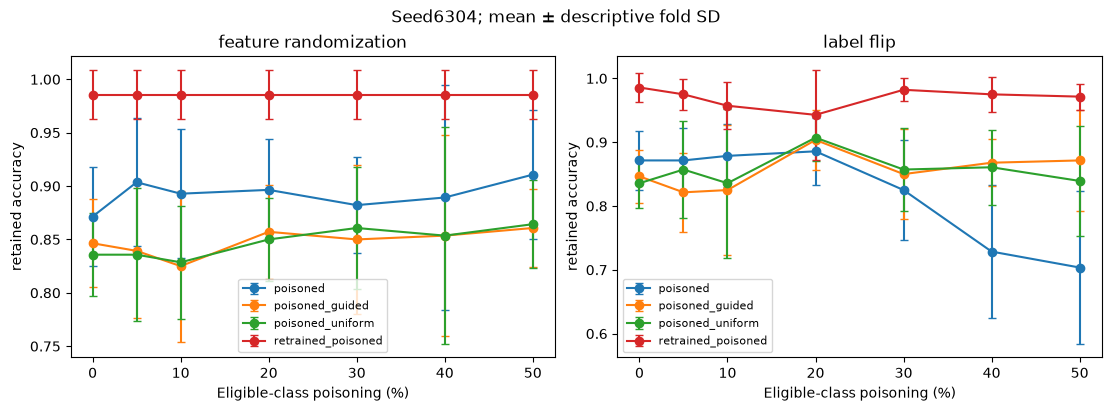

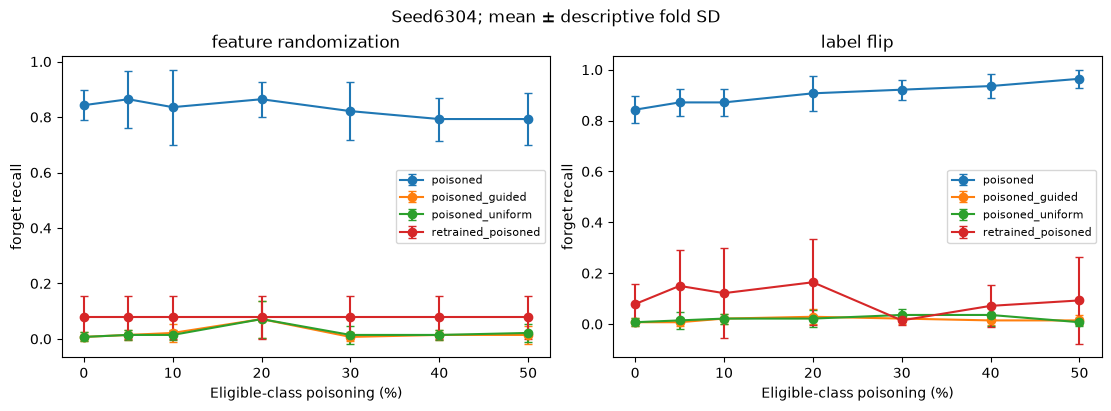

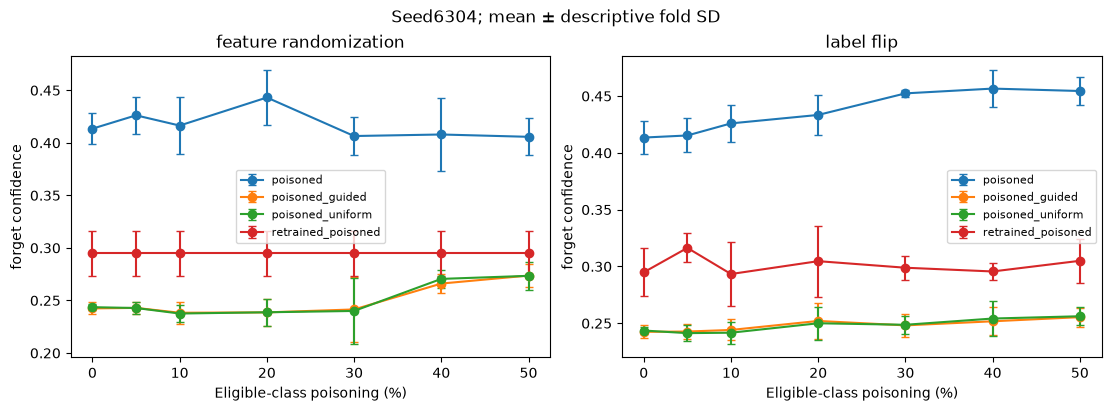

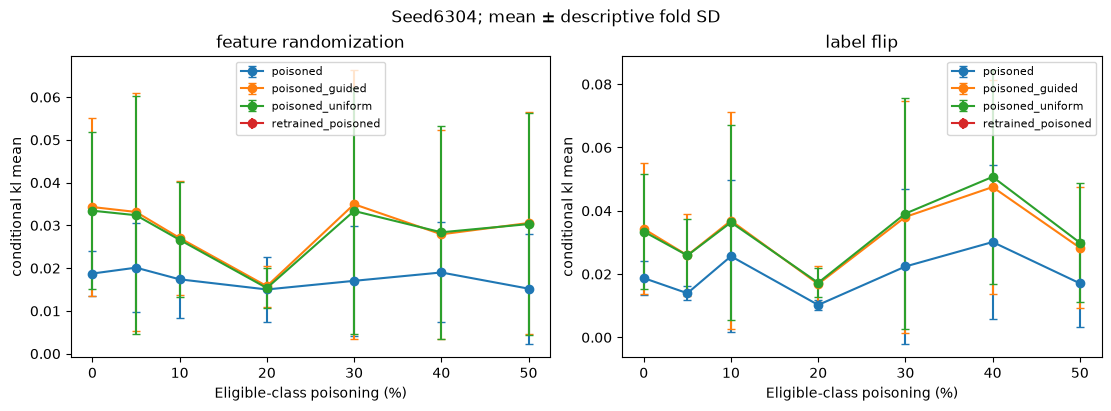

In [48]:
for name, figure in fresh_analysis.comparison_figures(tables).items():
    figures[f"primary_{name}"] = figure
    display(figure)
    plt.close(figure)


### 12.1.3 Locate saved extension studies


In [49]:
extension_paths, extension_status = workflow.extension_inventory(study, {
    "ablations": ABLATION_INDEX, "noise_studies": NOISE_INDEX,
    "noisy_training": NOISY_TRAINING_INDEX,
})
display(extension_status)
ablation_index = extension_paths["ablations"]
noise_index = extension_paths["noise_studies"]
noisy_index = extension_paths["noisy_training"]


,stage,index,complete,status,saved_fits,planned_fits
0,ablations,results/ablations/e4a96e40f818e487/study.json,True,complete,NaN,NaN
1,noise_studies,results/noise_studies/11aa94ebc456b91d/study.json,True,complete,NaN,NaN
2,noisy_training,results/noisy_training/9b54f30ef300facf/study....,True,complete,230.0,230.0


### 12.2 One-factor-at-a-time ablations

Vary guided unlearning only, keeping the parents, splits, PCA, seed, anchors,
and 100-update budget fixed. Conditions: clean, both attacks at 25%, and both
attacks at 50%, across all five folds. The default guided checkpoint and the
uniform comparison are reused rather than retrained for each parameter.

Alpha: 0, 0.5, 1, 2, 4. Lambda: 0, 0.001, 0.01, 0.1.
Beta: 0.25, 0.5, 0.75, 1, 2, 4. The extended values are our stress tests;
Malik's reported values are documented in the research context.


In [50]:
from src.ablations import SWEEPS, DEFAULTS, plan_table, ablation_execution, run_study
from src.evaluation import ablation_analysis

ablation_problems = study.ablation_problems(STUDY_FOLDS)
ablation_plan = plan_table(ablation_problems)
display(ablation_plan.groupby(["parameter", "value"]).size().rename("planned_fits").to_frame())
print("Nondefault ablation fits:", len(ablation_plan))


planned_fits
parameter      value              
alpha          0.000            25
               0.500            25
               2.000            25
               4.000            25
beta           0.250            25
               0.500            25
               0.750            25
               2.000            25
               4.000            25
regularization 0.000            25
               0.001            25
               0.100            25

Nondefault ablation fits: 300


### 12.2.1 Execute only when explicitly enabled

Alpha=0 removes retained-anchor loss; lambda=0 removes parameter preservation.
No Cartesian grid is used. Optional first-fold compatibility checks are kept
separate from the 300 nondefault parameter fits.


In [51]:
if RUN_ABLATIONS:
    with ablation_execution(PROJECT_ROOT):
        ablation_index = run_study(
            study, ablation_problems, execution, force_retrain=FORCE_ABLATIONS,
            baseline_checks=RUN_BASELINE_COMPATIBILITY,
            progress=lambda event: print(f"Ablations {event['completed']}/{event['planned']}: "
                f"{event['problem']} {event['parameter']}={event['value']}", flush=True),
        )


### 12.2.2 Parameter summary, target distributions, and paired changes


In [52]:
if SHOW_ABLATION_ANALYSIS and ablation_index is not None:
    print("Reading saved ablation metrics...", flush=True)
    _, ablation_results = ablation_analysis.study_tables(ablation_index, PROJECT_ROOT)
    extension_tables["ablations"] = ablation_results
    display(ablation_results["fold_summary"].round(4))
    display(ablation_results["paired_fold_summary"].round(4))
    display(ablation_results["summary"][["condition", "fold", "parameter", "value", "target_0", "target_1", "target_2"]].round(5))
    display(ablation_results["coverage"].groupby("completed").size().rename("fits").to_frame())
else:
    print("Saved ablation analysis is disabled or its completed index is not available.")


Reading saved ablation metrics...


,condition,parameter,value,metric,mean,fold_sd,n_folds,expected_folds,complete_folds
0,clean,alpha,0.0,retained_accuracy,0.7036,0.1076,5,5,True
1,clean,alpha,0.0,forget_recall,0.0071,0.0160,5,5,True
2,clean,alpha,0.0,forget_confidence,0.2328,0.0063,5,5,True
3,clean,alpha,0.0,full_kl_mean,0.0515,0.0292,5,5,True
4,clean,alpha,0.0,conditional_kl_mean,0.0480,0.0235,5,5,True
...,...,...,...,...,...,...,...,...,...
555,label_flip_50pct,uniform,NaN,full_kl_mean,0.0304,0.0162,5,5,True
556,label_flip_50pct,uniform,NaN,conditional_kl_mean,0.0299,0.0187,5,5,True
557,label_flip_50pct,uniform,NaN,recall_digit_0,0.8786,0.1029,5,5,True
558,label_flip_50pct,uniform,NaN,recall_digit_1,0.8000,0.1609,5,5,True


,condition,parameter,value,metric,mean_delta,fold_sd,n_folds,expected_folds
0,clean,alpha,0.0,retained_accuracy,-0.1429,0.1244,5,5
1,clean,alpha,0.0,forget_recall,0.0000,0.0000,5,5
2,clean,alpha,0.0,forget_confidence,-0.0096,0.0032,5,5
3,clean,alpha,0.0,full_kl_mean,0.0142,0.0052,5,5
4,clean,alpha,0.0,conditional_kl_mean,0.0137,0.0050,5,5
...,...,...,...,...,...,...,...,...
475,label_flip_50pct,regularization,0.1,full_kl_mean,-0.0017,0.0086,5,5
476,label_flip_50pct,regularization,0.1,conditional_kl_mean,-0.0115,0.0083,5,5
477,label_flip_50pct,regularization,0.1,recall_digit_0,-0.2143,0.3154,5,5
478,label_flip_50pct,regularization,0.1,recall_digit_1,0.0643,0.1346,5,5


,condition,fold,parameter,value,target_0,target_1,target_2
0,clean,0,baseline,NaN,0.52234,0.47766,0.0
1,clean,0,uniform,NaN,0.50000,0.50000,0.0
2,feature_randomization_25pct,0,baseline,NaN,0.49330,0.50670,0.0
3,feature_randomization_25pct,0,uniform,NaN,0.50000,0.50000,0.0
4,feature_randomization_50pct,0,baseline,NaN,0.49529,0.50471,0.0
...,...,...,...,...,...,...,...
345,label_flip_50pct,0,beta,4.0,0.62523,0.37477,0.0
346,label_flip_50pct,1,beta,4.0,0.54371,0.45629,0.0
347,label_flip_50pct,2,beta,4.0,0.61448,0.38552,0.0
348,label_flip_50pct,3,beta,4.0,0.72899,0.27101,0.0


,fits
completed,
True,300


### 12.2.3 Plot each parameter's effect


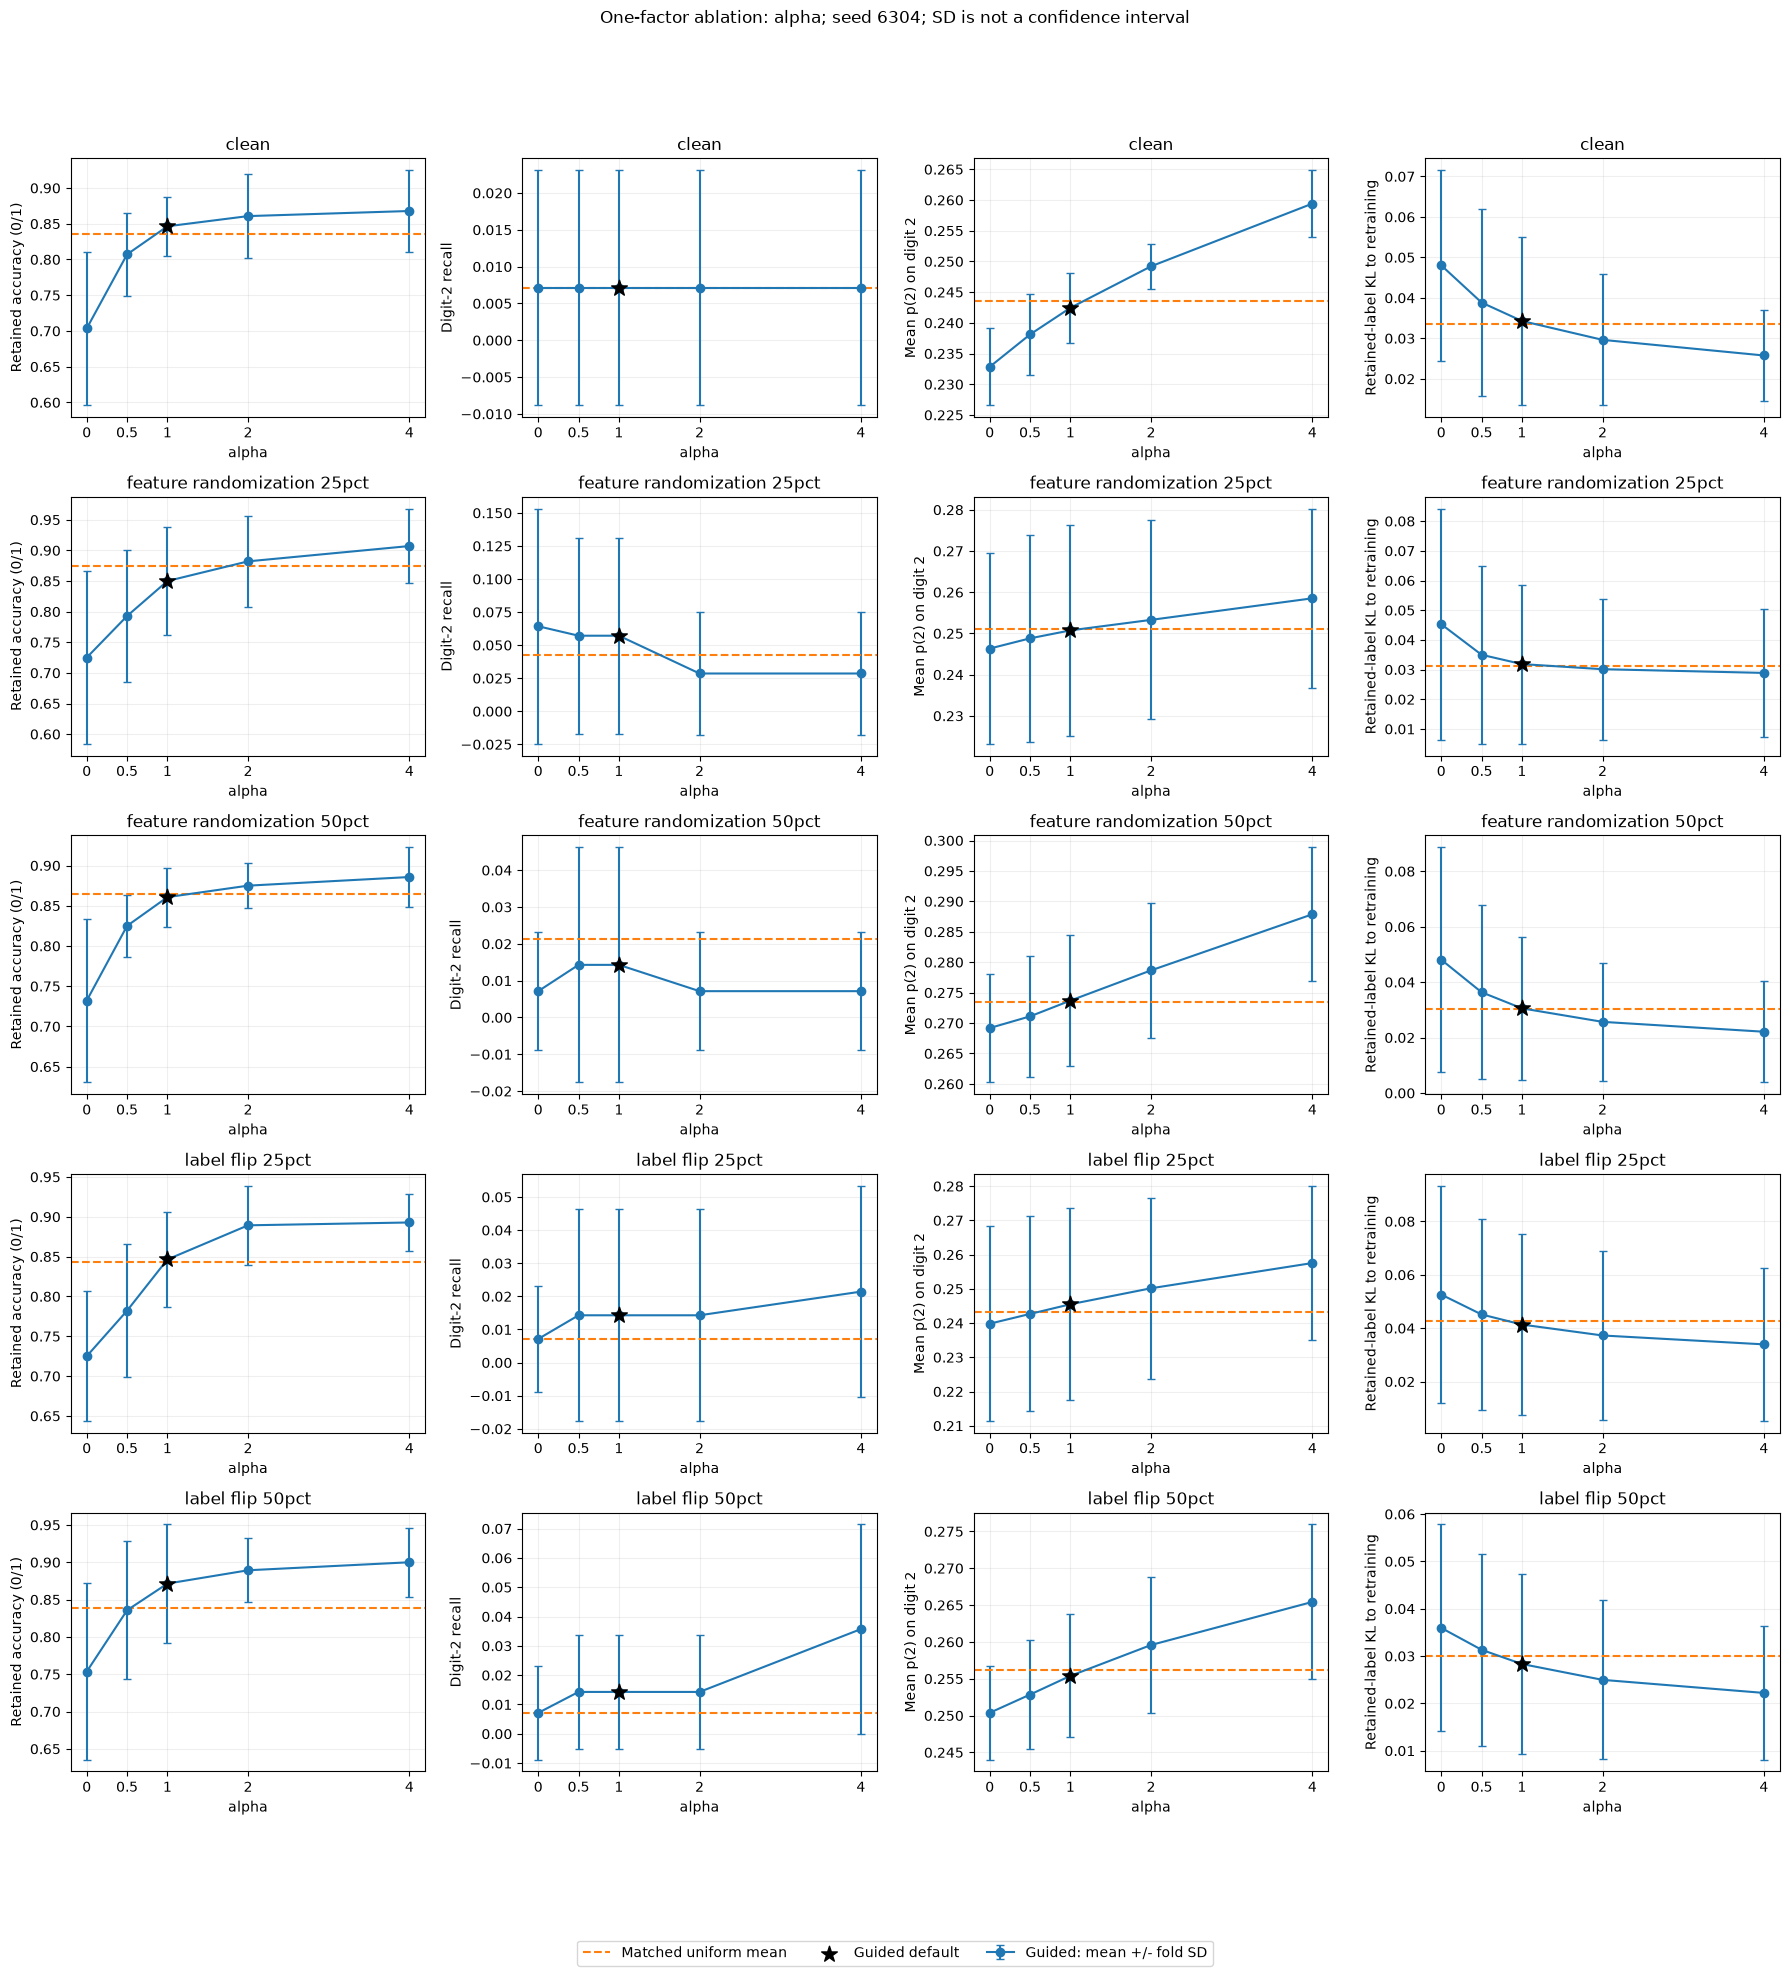

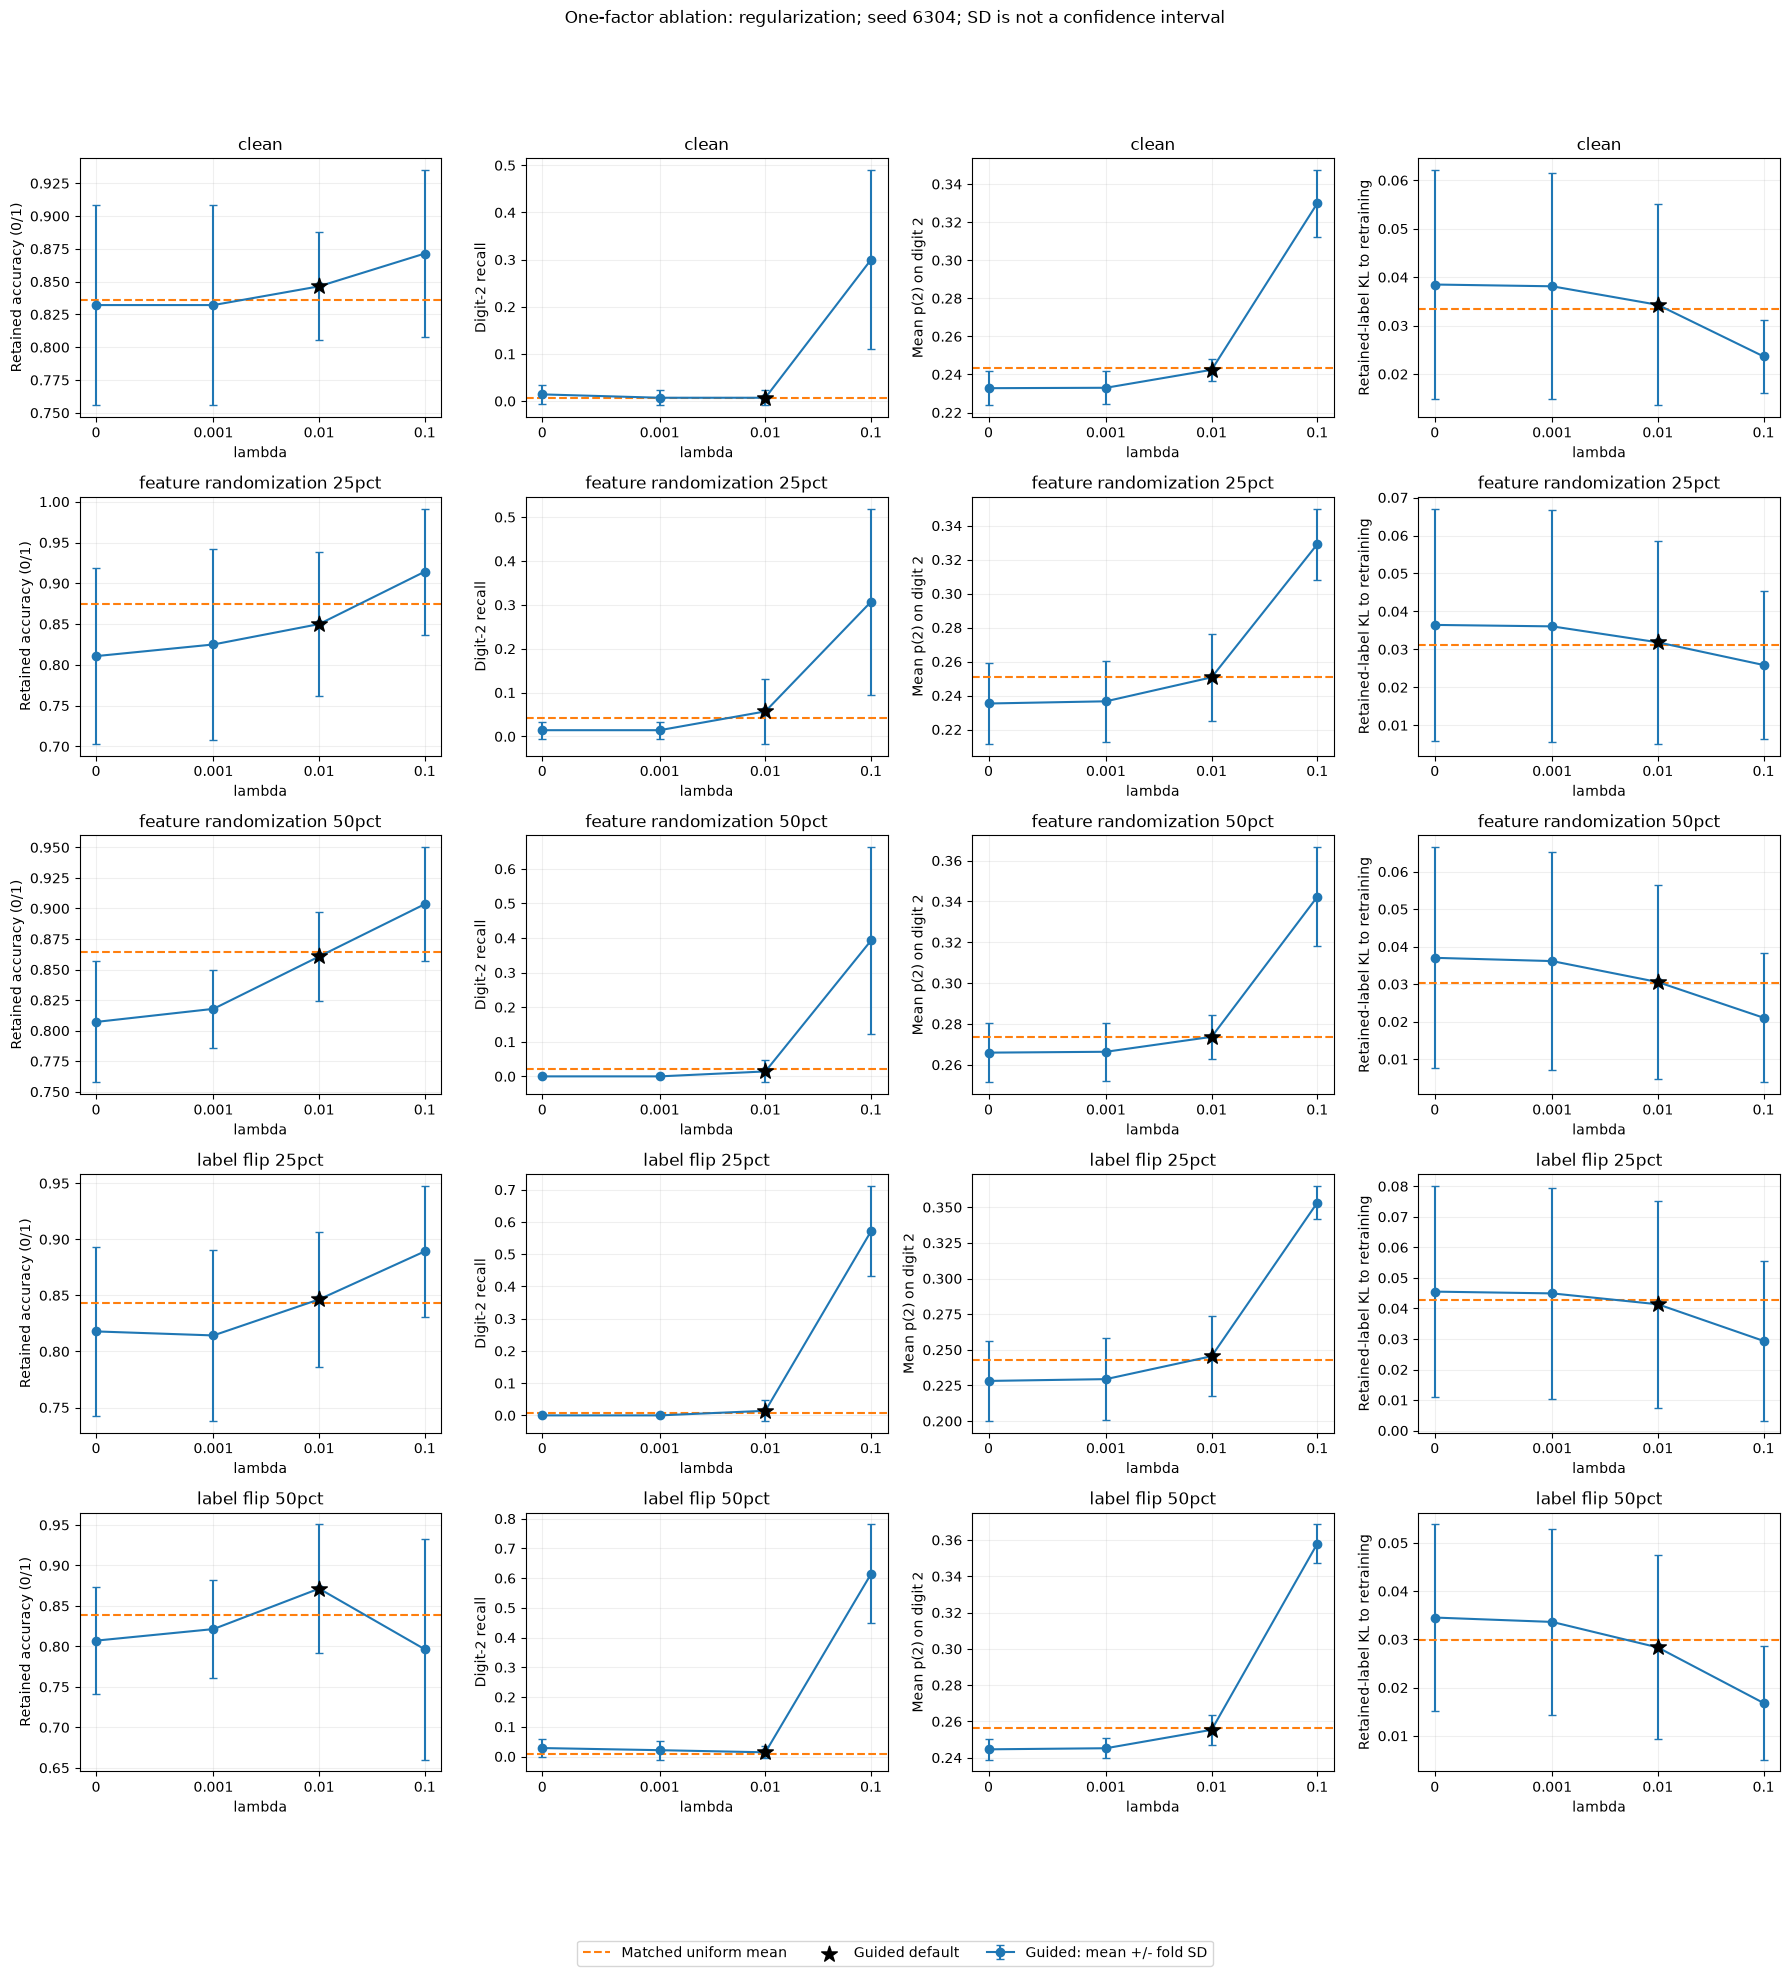

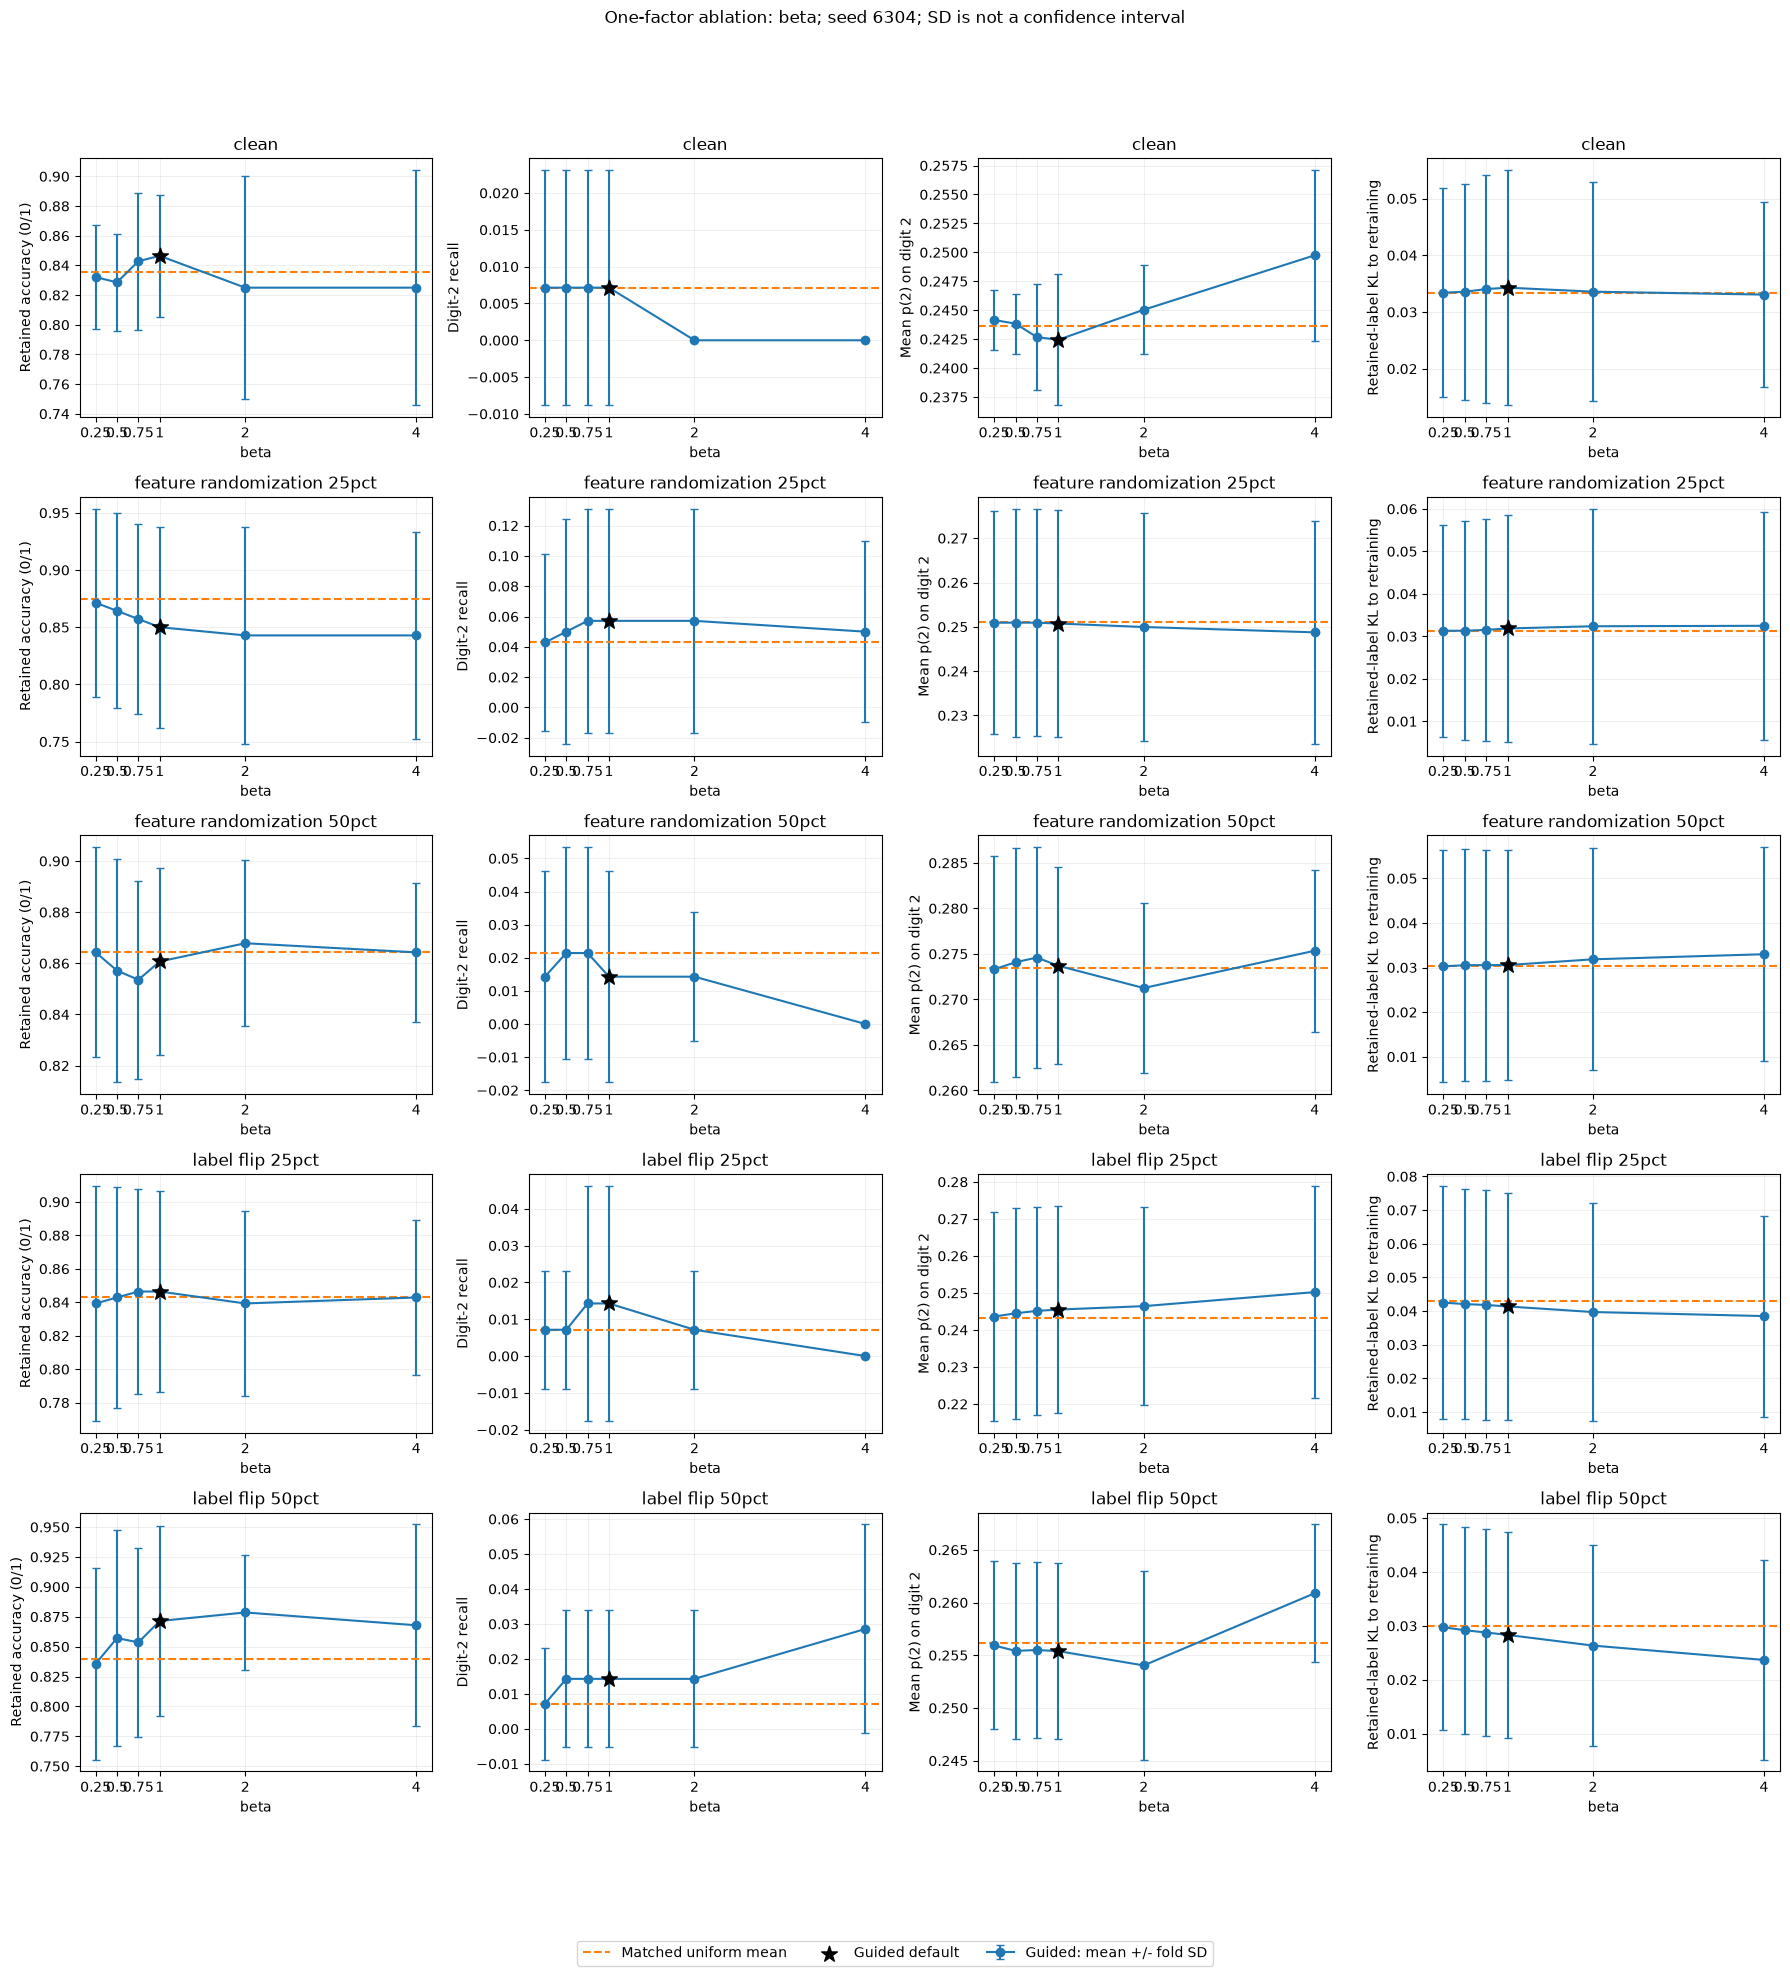

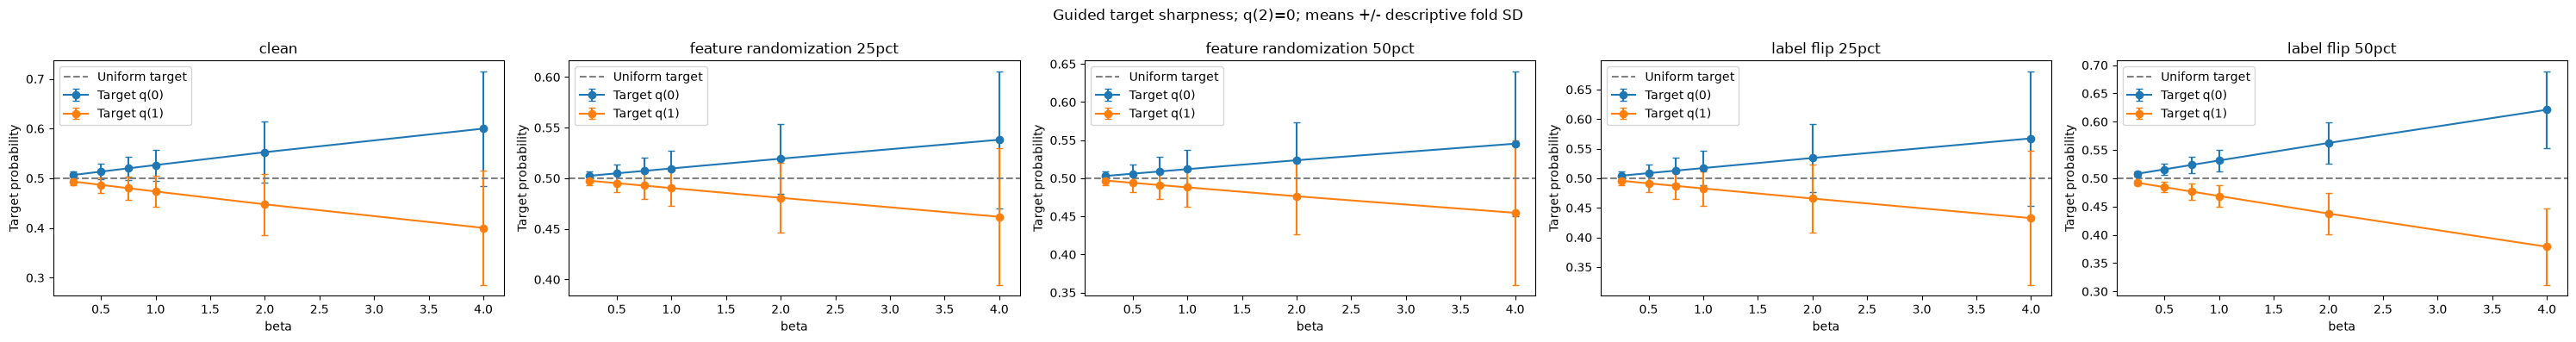

In [53]:
if "ablations" in extension_tables:
    extension_figures["ablations"] = ablation_analysis.comparison_figures(extension_tables["ablations"])
    for figure in extension_figures["ablations"].values():
        display(figure)
        plt.close(figure)


**Interpretation:** compare each setting with its own fold-matched default.
Report retention/forgetting tradeoffs, not only the smallest digit-2 recall.
Beta changes the target distribution; a nearly uniform teacher can make beta
changes small. Test-set plots are evaluation, not a tuning rule.


### 12.3 Scope of additional controls

Shuffled-label fits, multiple training seeds, new circuits, and a new unlearning
method are outside this run. Classical baselines, the uniform target, alpha=0,
lambda=0, matched retraining, and zero-noise checks provide the current controls.


### 12.4 Fixed-weight synthetic noise evaluation

Keep trained weights fixed and evaluate all primary poisoning conditions
across five folds. Use zero noise and depolarizing, bit-flip, phase-flip,
readout, and combined profiles at p=0.001, 0.005, 0.01, 0.02. Gate strength is
p on one-qubit gates and 2p on CX; combined adds symmetric readout flips at p.
These are declared synthetic channels, not calibrated hardware noise.


In [54]:
from src.noise_study import load_noise_inputs, noise_plan, run_noise_study
from src.models.noise import NoiseExecution
from src.evaluation import noise_analysis

if RUN_FIXED_WEIGHT_NOISE:
    noise_inputs, noise_bindings = load_noise_inputs(primary_study, STUDY_FOLDS, "all")
    display(noise_plan(noise_inputs, noise_bindings))
    noise_execution = NoiseExecution(device=execution.device,
        circuit_batch_size=512, threads=execution.threads, memory_mb=execution.memory_mb)


### 12.4.1 Generate new noise predictions only when enabled


In [55]:
if RUN_FIXED_WEIGHT_NOISE:
    noise_index = run_noise_study(
        primary_study, noise_inputs, noise_bindings, noise_execution,
        allow_execution=True, force_evaluate=FORCE_NOISE_EVALUATION,
        progress=lambda event: print(f"Noise evaluation {event['completed']}/{event['planned']}", flush=True),
    )


### 12.4.2 Read saved noise metrics

This can read thousands of prediction files. It does not train models. The
export step will reuse these loaded tables instead of reading them again.
Noise comparisons use the retraining reference under the matched noise profile.


In [56]:
if SHOW_NOISE_ANALYSIS and noise_index is not None:
    print("Reading and checking saved noise predictions; no model execution...", flush=True)
    _, noise_results = noise_analysis.noise_tables(noise_index, PROJECT_ROOT)
    extension_tables["noise_studies"] = noise_results
    display(noise_results["fold_summary"].round(4))
    display(noise_results["coverage"].groupby("completed").size().rename("rows").to_frame())
else:
    print("Saved fixed-weight noise analysis is disabled or not available.")


Reading and checking saved noise predictions; no model execution...


,condition,attack,poison_rate,role,family,level,mode,metric,mean,fold_sd,n_folds,planned_folds,complete_folds
0,clean,none,0.00,guided,bit_flip,0.001,exact,retained_accuracy,0.8464,0.0411,5,5,True
1,clean,none,0.00,guided,bit_flip,0.001,exact,forget_recall,0.0071,0.0160,5,5,True
2,clean,none,0.00,guided,bit_flip,0.001,exact,forget_confidence,0.2620,0.0045,5,5,True
3,clean,none,0.00,guided,bit_flip,0.001,exact,forgotten_mass_on_retained,0.2949,0.0103,5,5,True
4,clean,none,0.00,guided,bit_flip,0.001,exact,recall_digit_0,0.9500,0.0598,5,5,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
24019,label_flip_5pct,label_flip,0.05,uniform,readout,0.020,shots_2048,recall_digit_2,0.0143,0.0319,5,5,True
24020,label_flip_5pct,label_flip,0.05,uniform,readout,0.020,shots_2048,conditional_kl_mean,0.0238,0.0103,5,5,True
24021,label_flip_5pct,label_flip,0.05,uniform,readout,0.020,shots_2048,full_kl_mean,0.0275,0.0162,5,5,True
24022,label_flip_5pct,label_flip,0.05,uniform,readout,0.020,shots_2048,mean_prediction_margin,0.0862,0.0230,5,5,True


,rows
completed,
True,10920


### 12.4.3 Compare retention and forgetting under noise


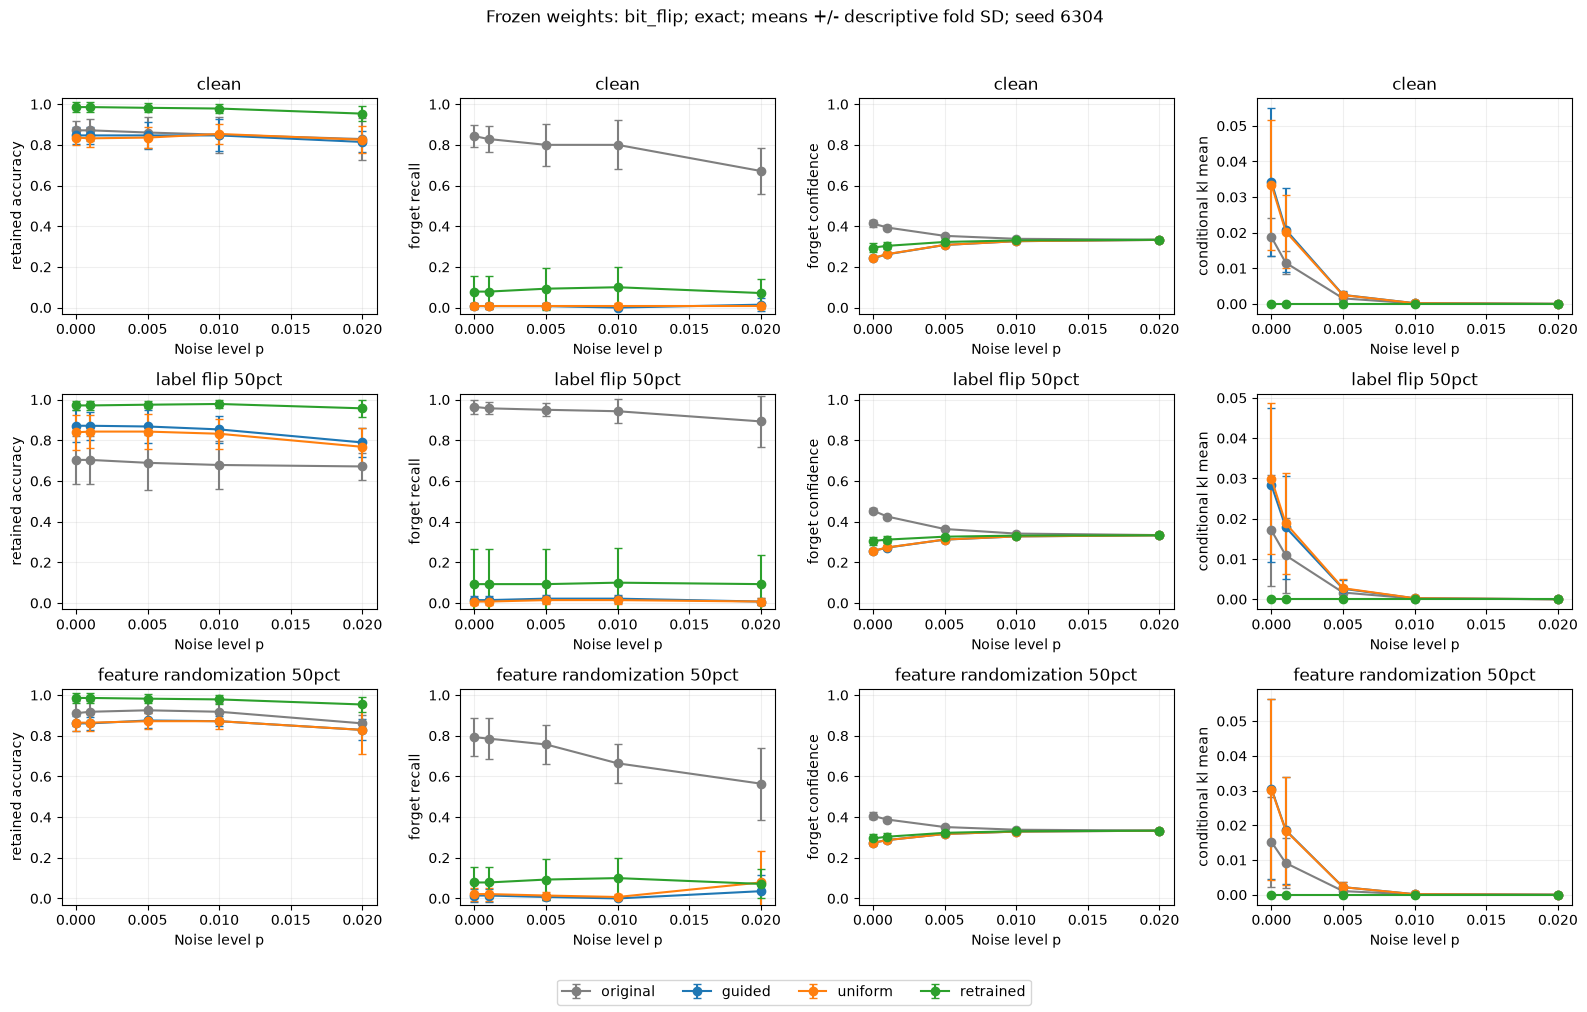

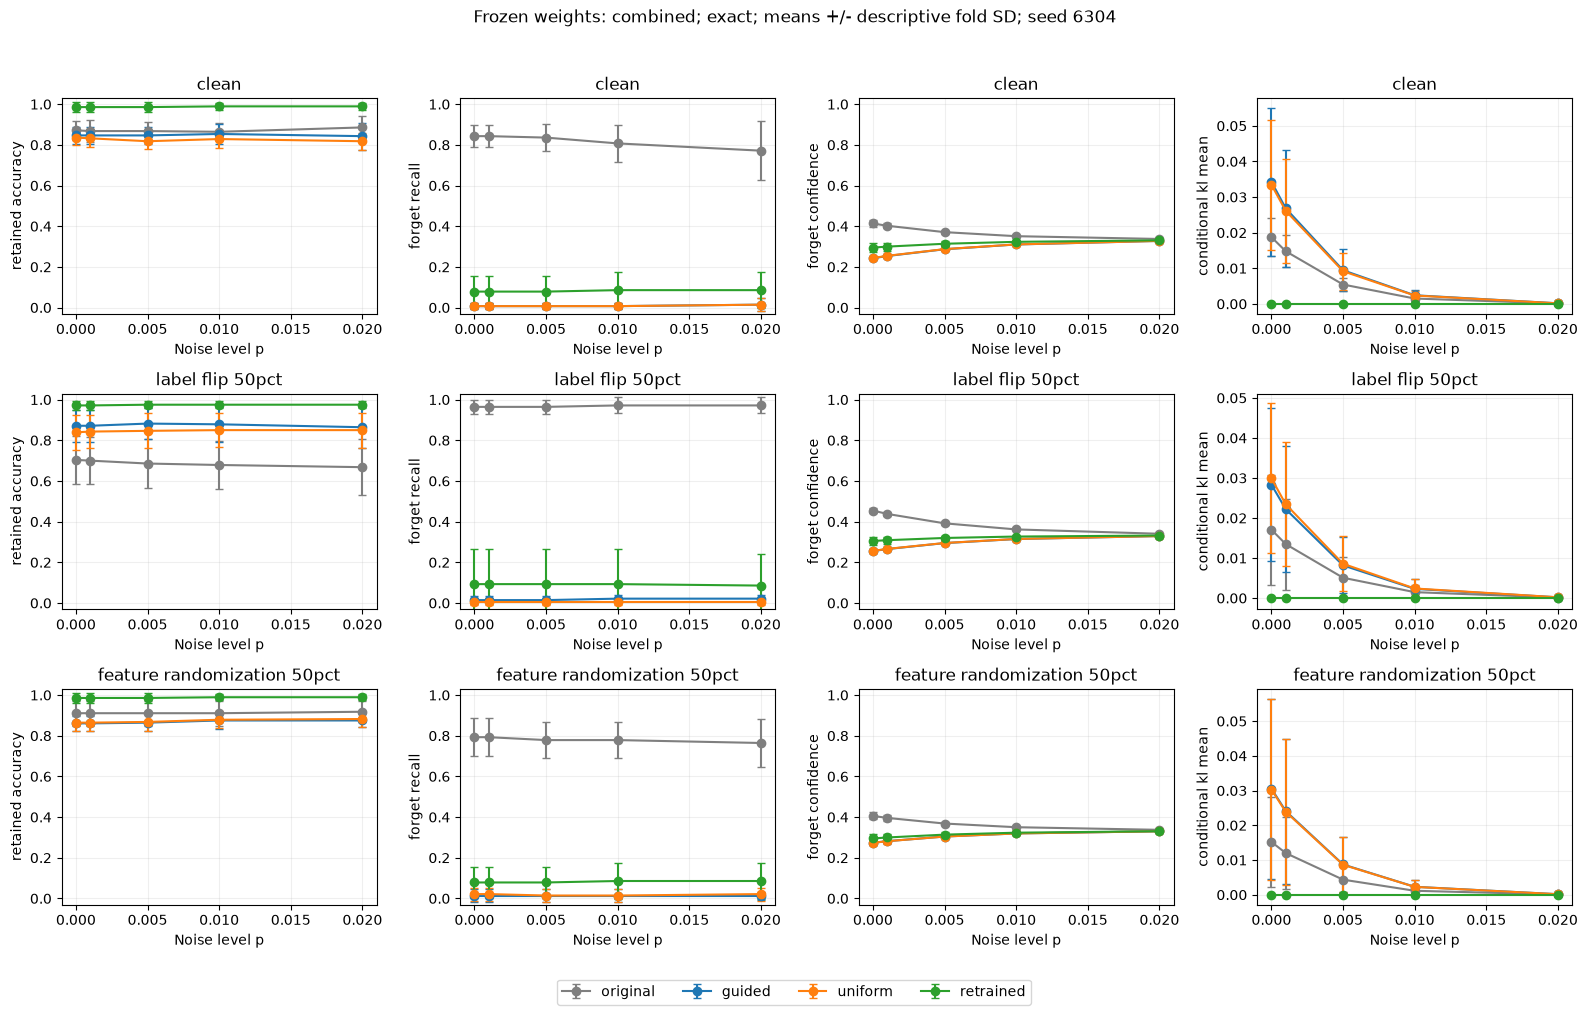

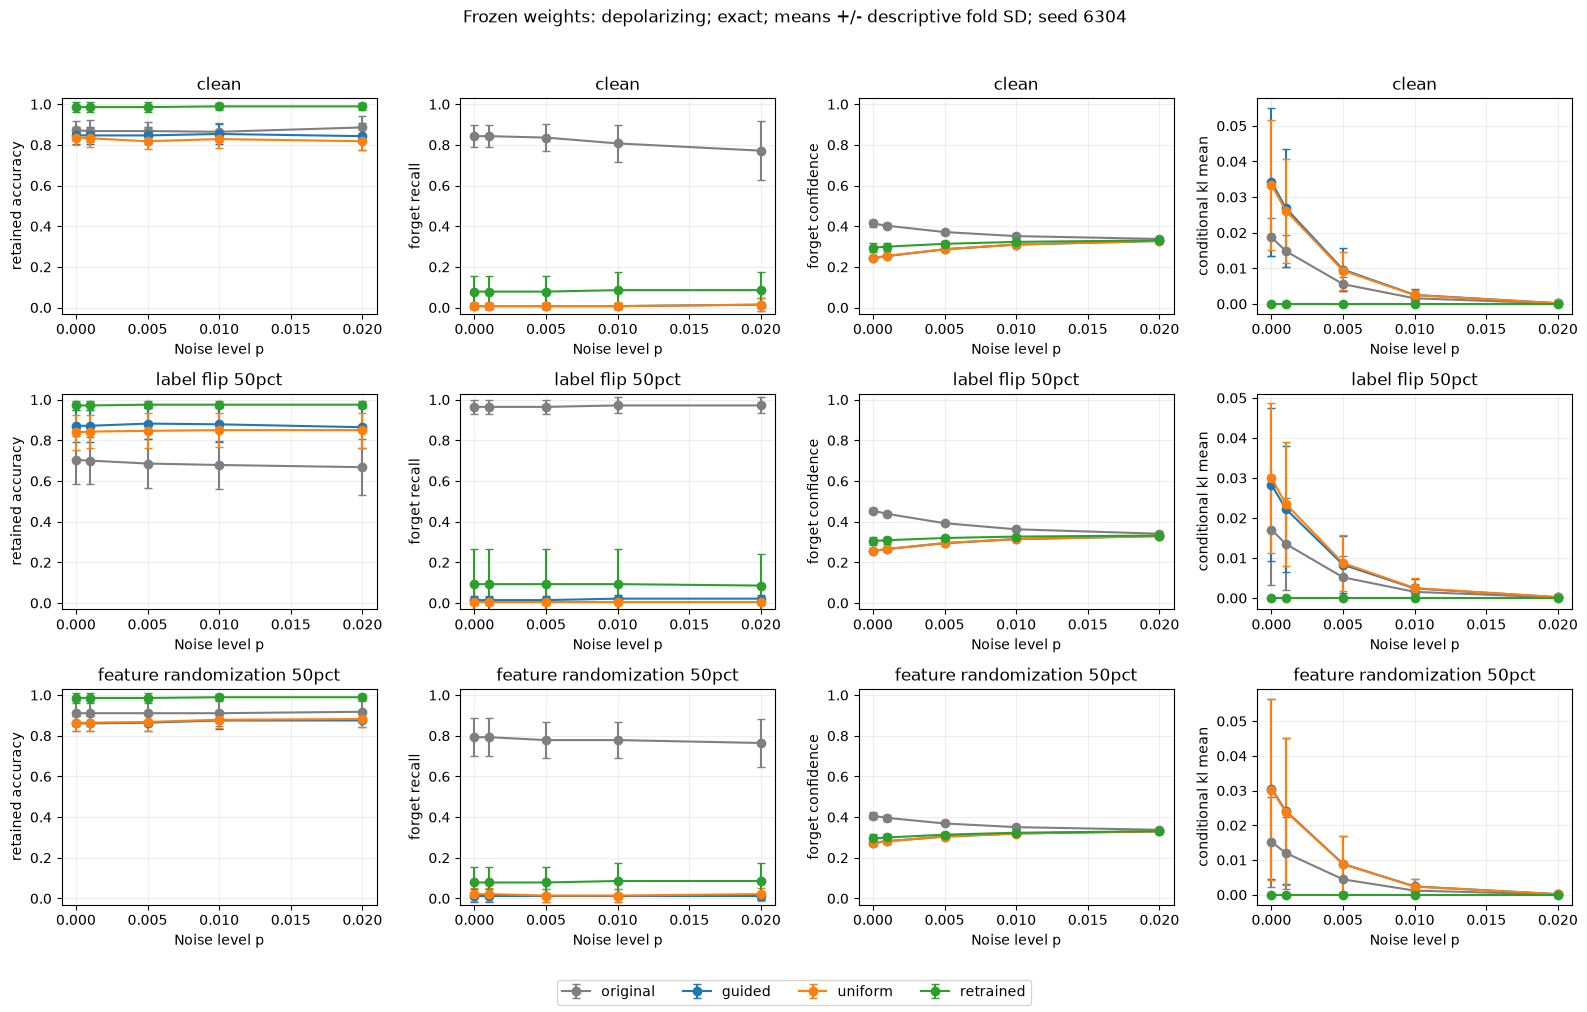

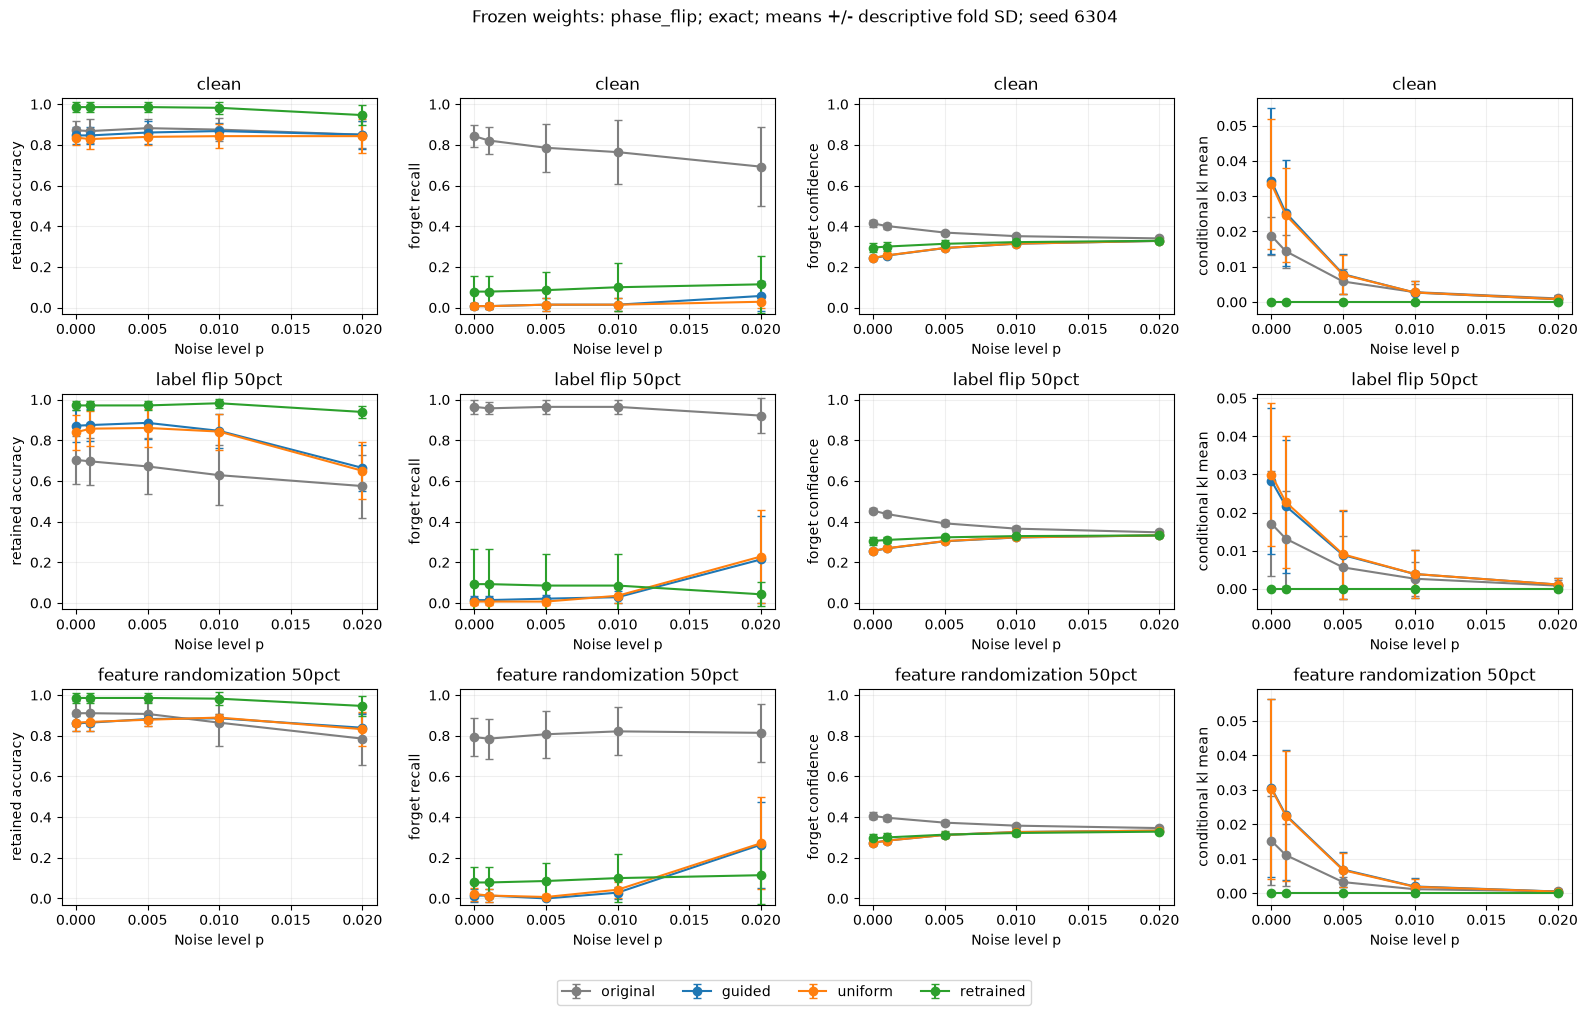

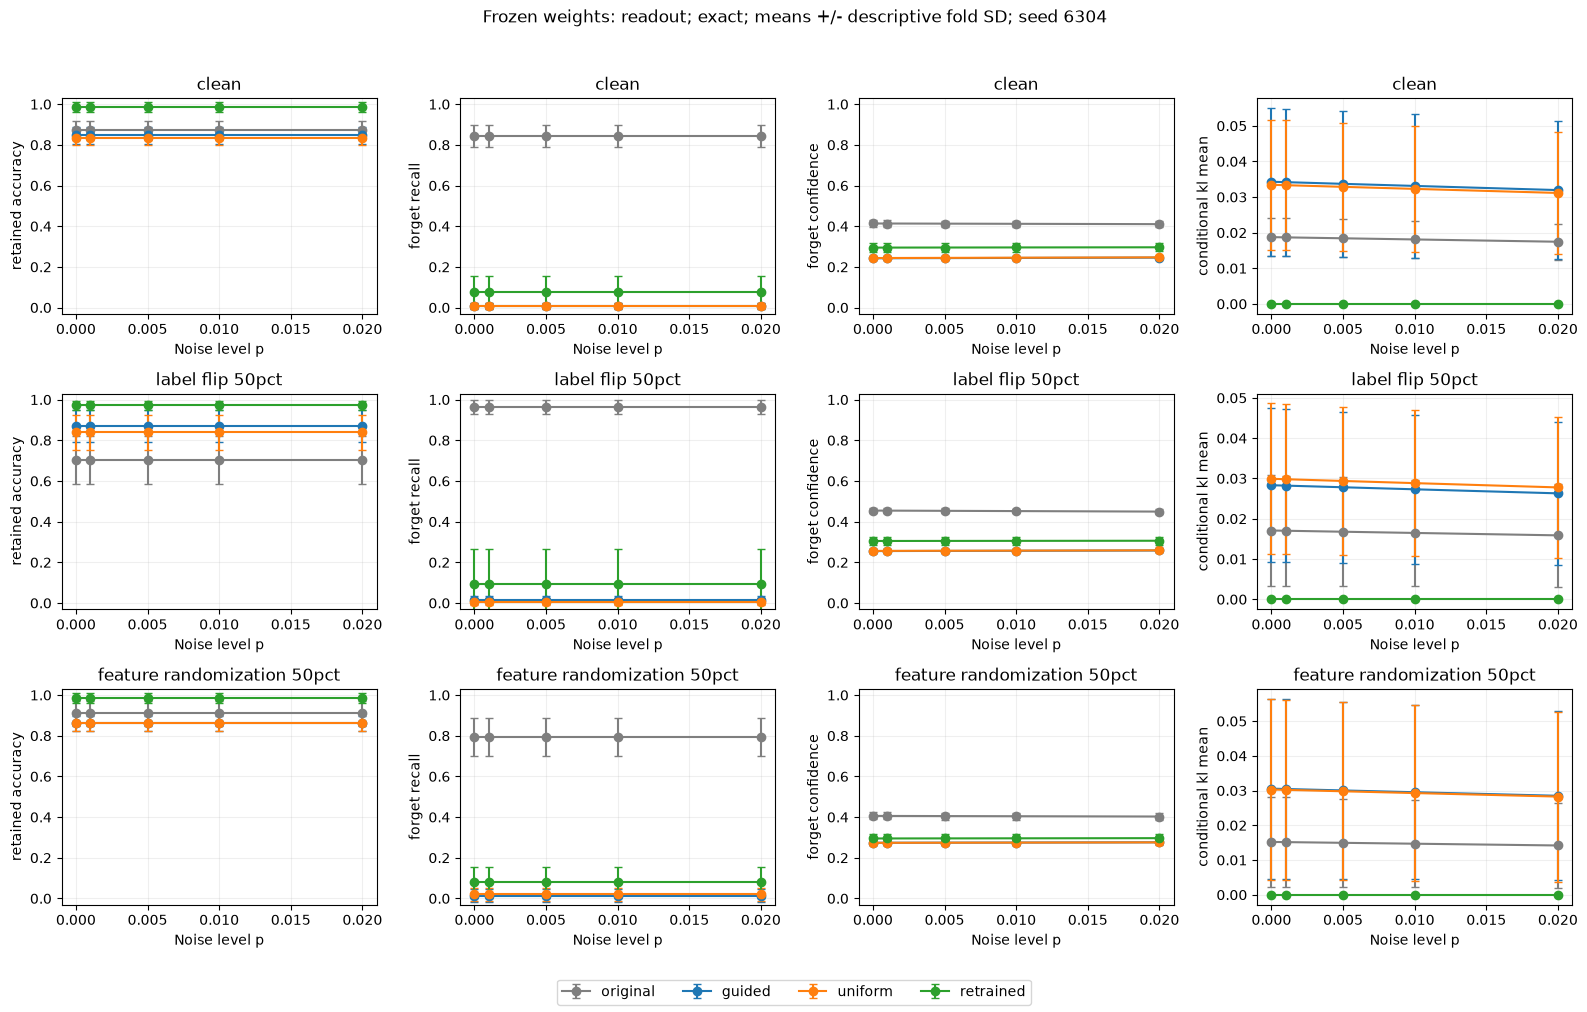

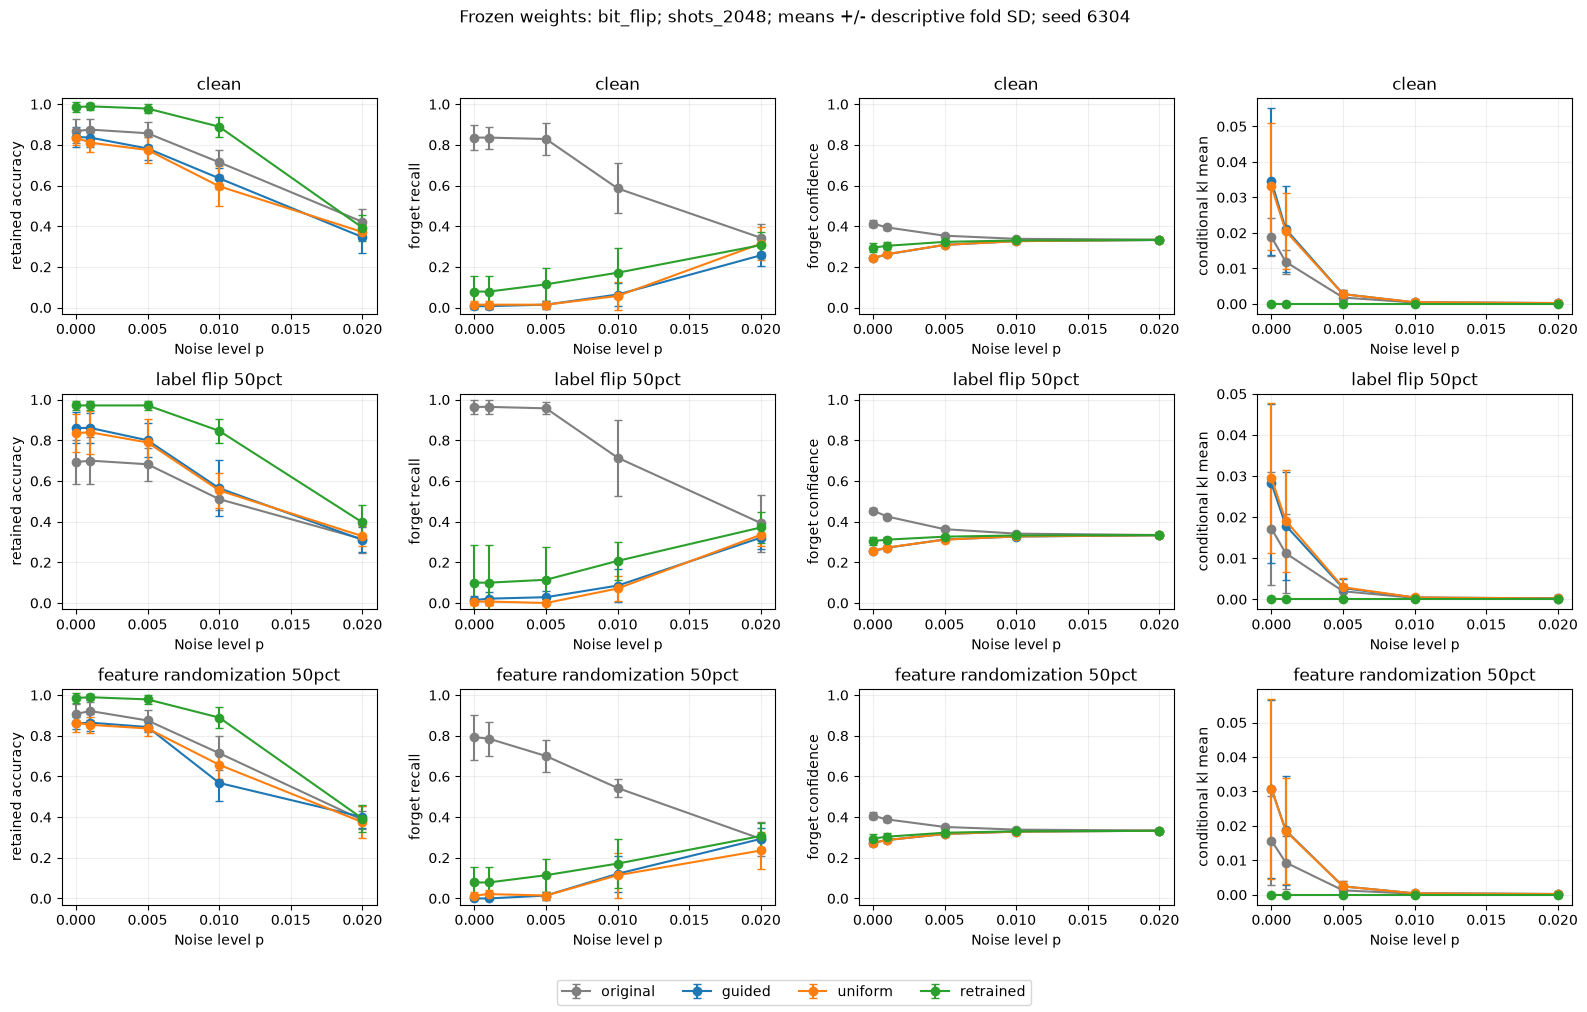

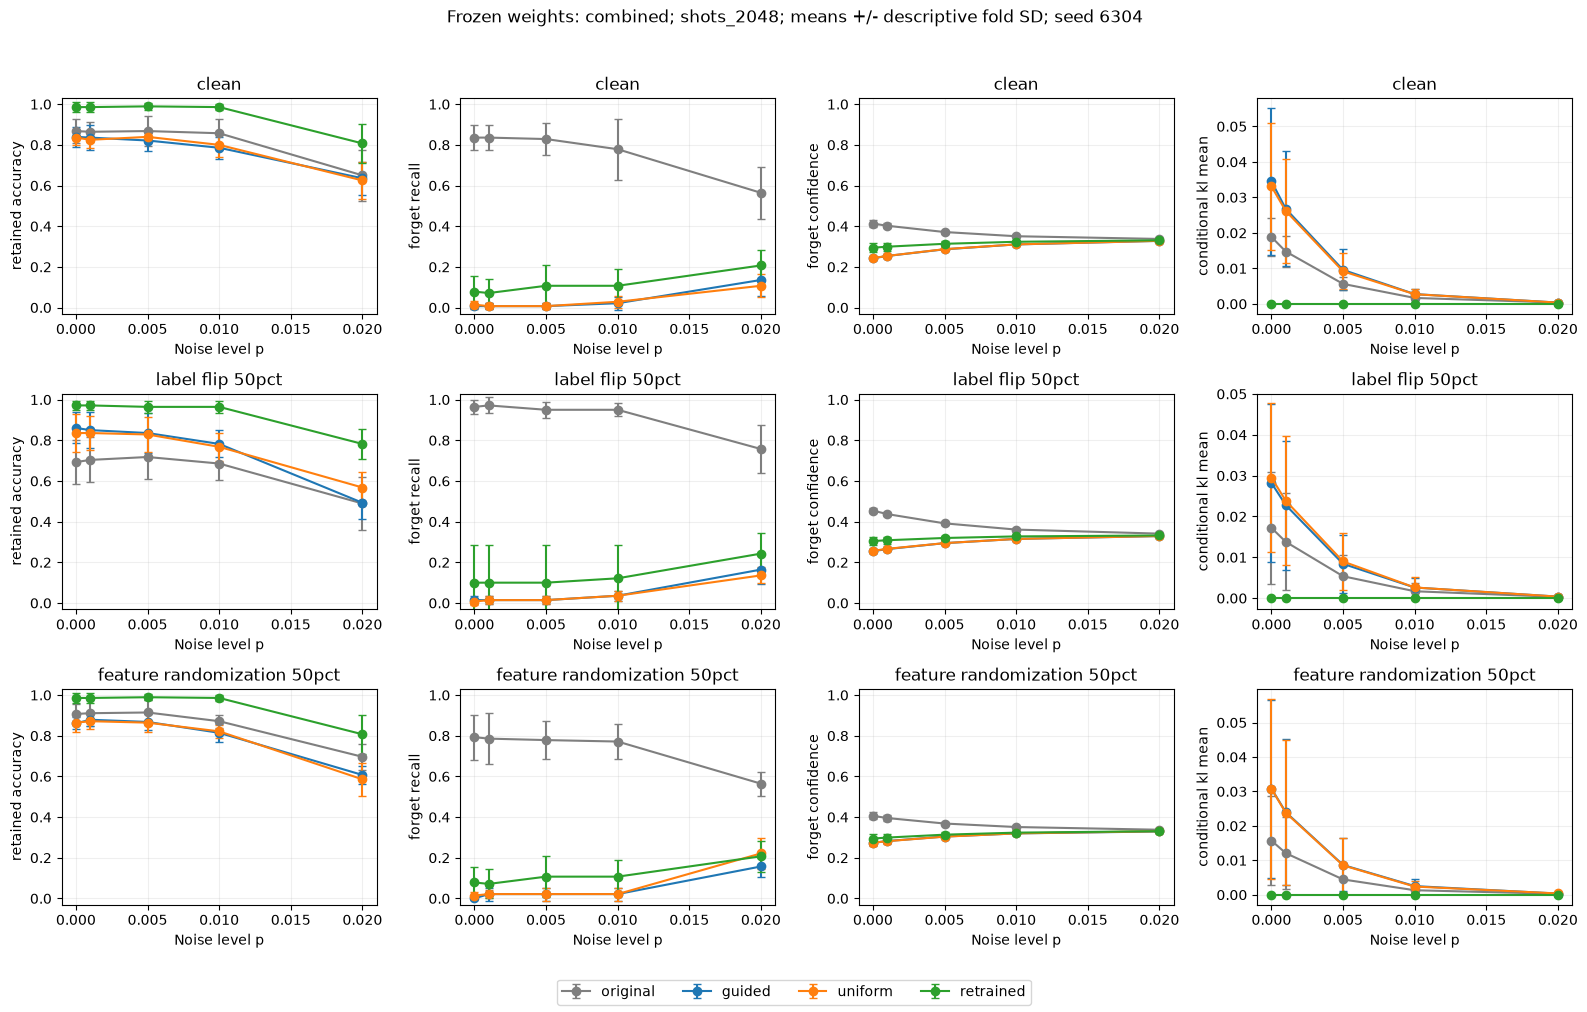

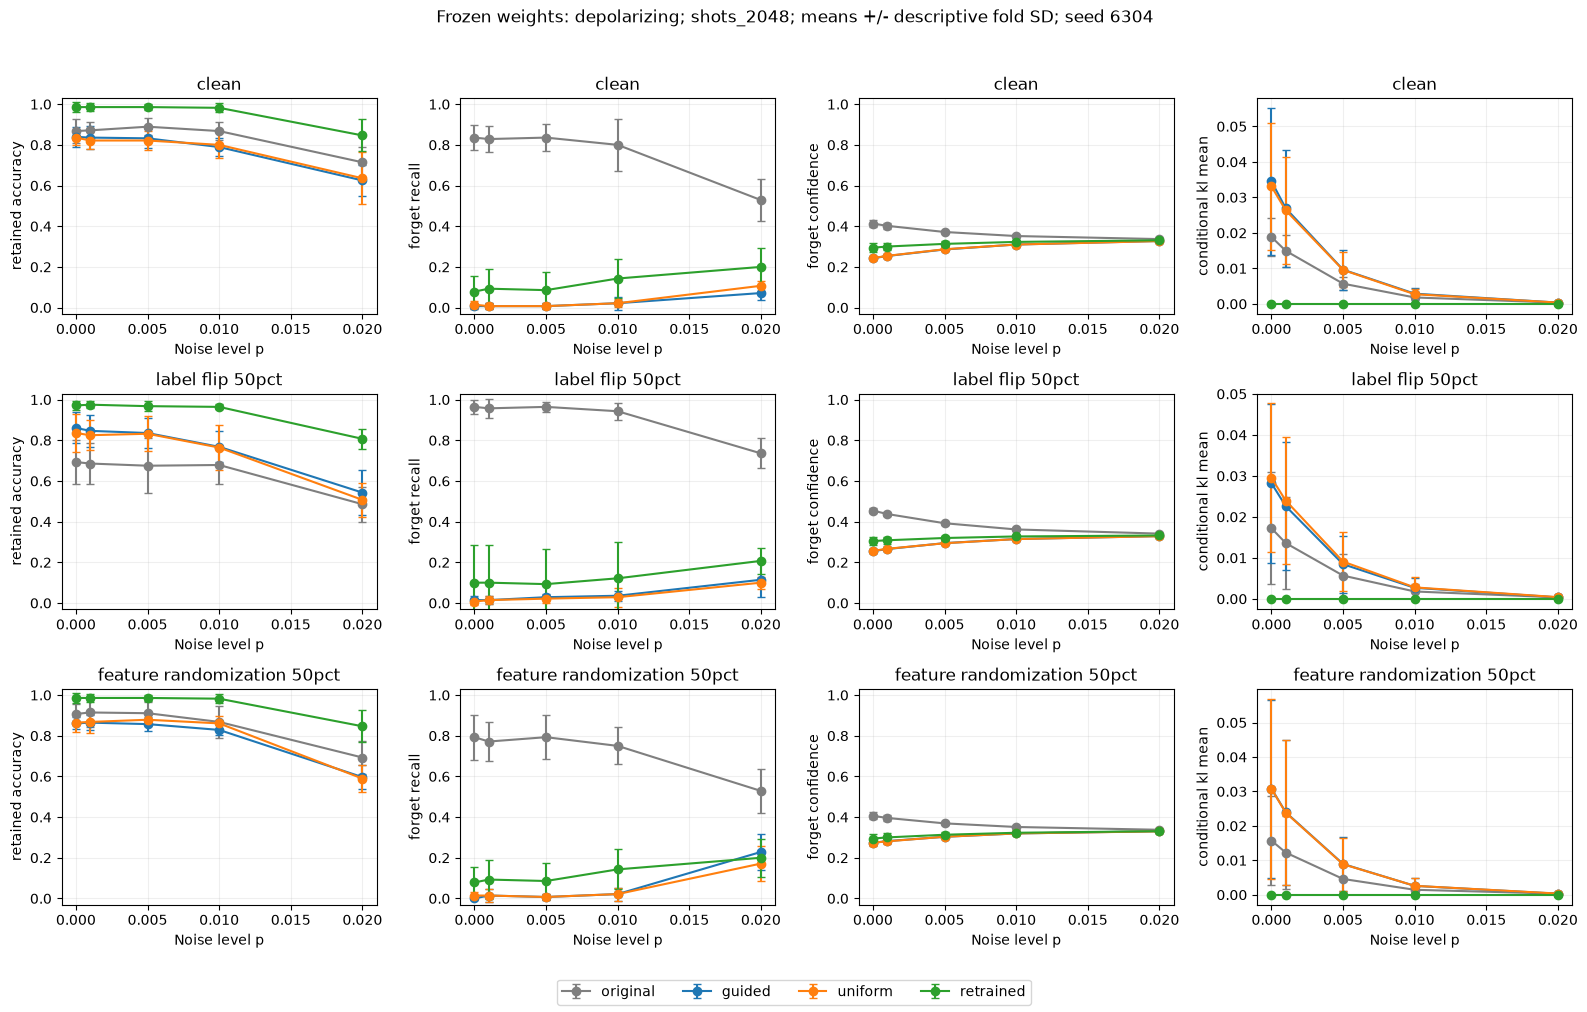

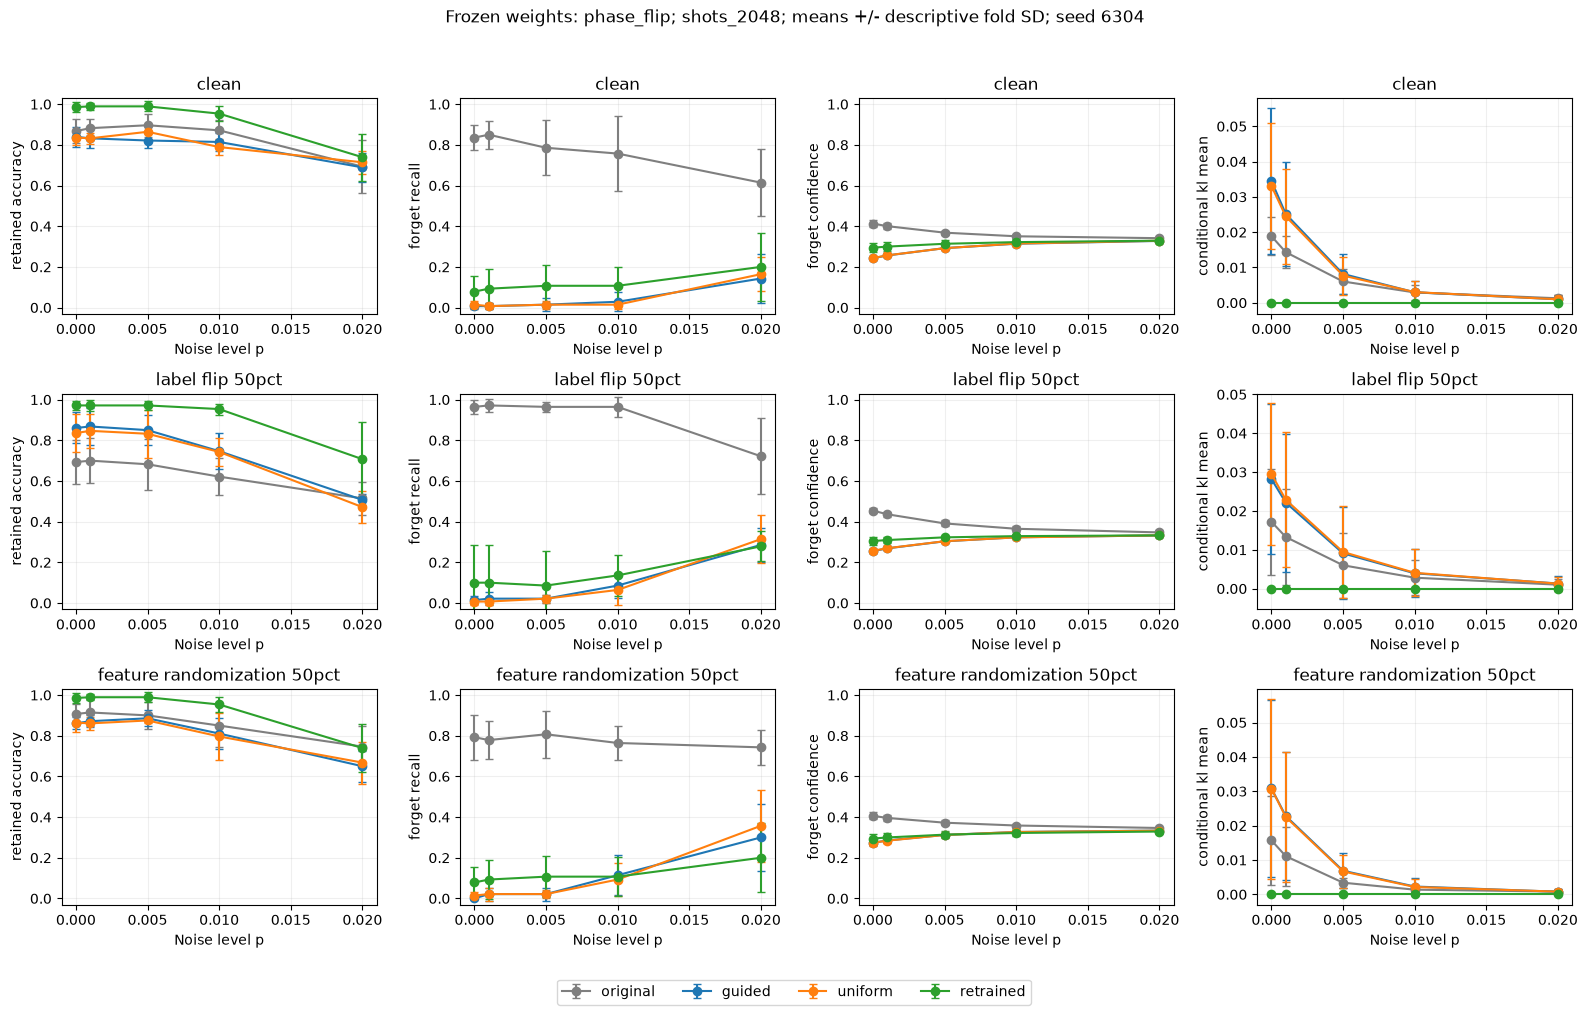

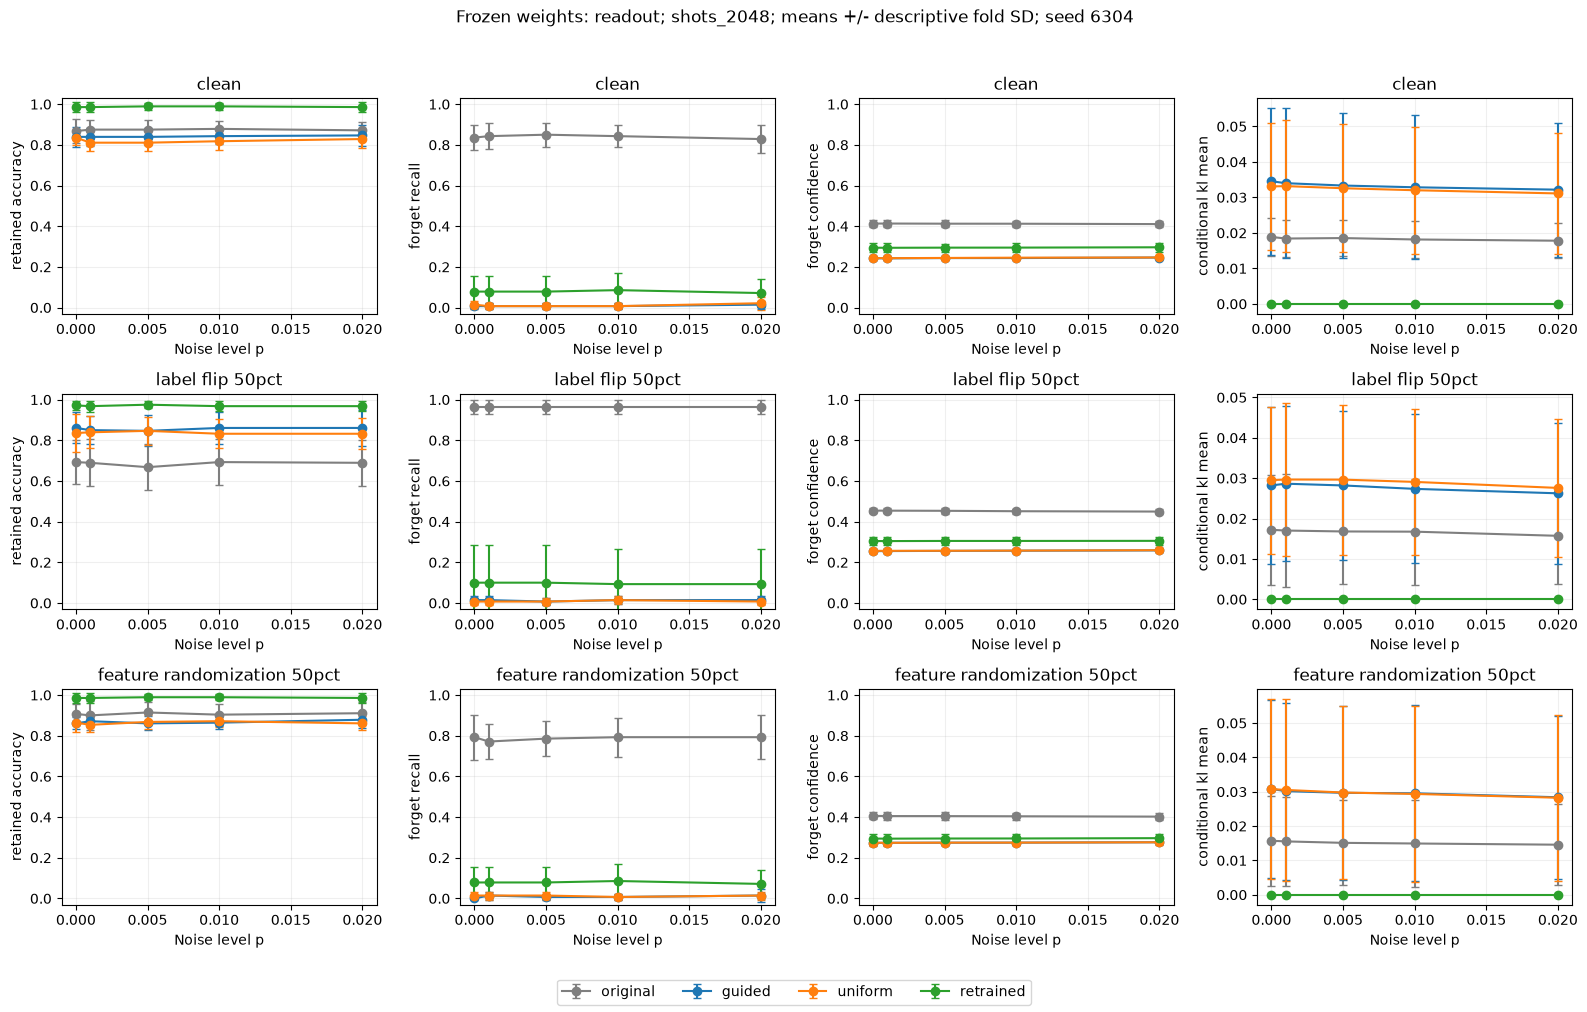

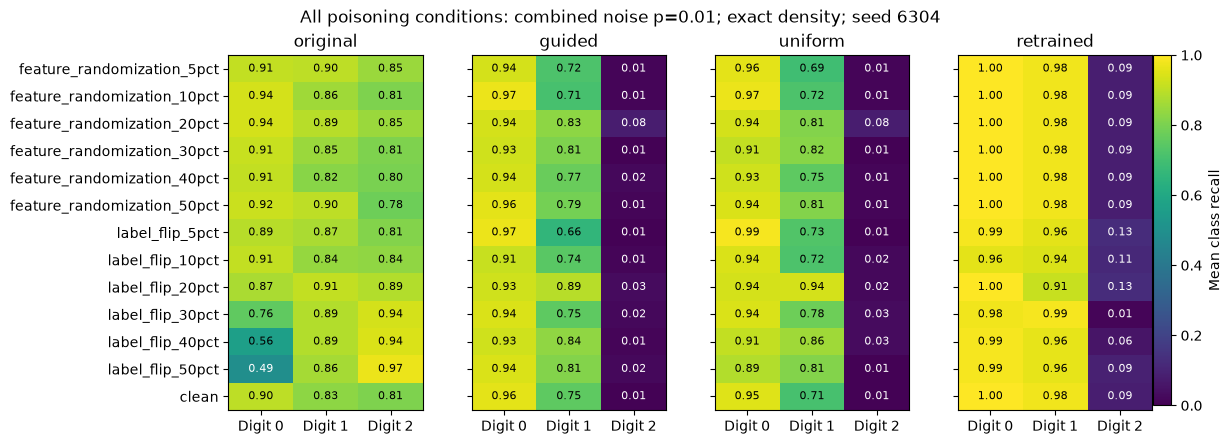

In [57]:
if "noise_studies" in extension_tables:
    extension_figures["noise_studies"] = noise_analysis.noise_figures(extension_tables["noise_studies"])
    for figure in extension_figures["noise_studies"].values():
        display(figure)
        plt.close(figure)


### 12.5 Exact density probabilities and finite readout shots

Gate noise is integrated with density-matrix evolution. Exact readout
probabilities and a separate 2048-shot draw are both evaluated. Shot draws
are not new training seeds. Noise can reduce digit-2 confidence without
performing useful unlearning; always inspect retained utility and matched KL.


In [58]:
if "noise_studies" in extension_tables:
    noise_summary = extension_tables["noise_studies"]["summary"]
    display(noise_summary.head(12).round(4))


,attack,condition,condition_manifest,fold,original_id,poison_rate,realized_eligible_fraction,realized_training_fraction,reference_id,role,...,mean_prediction_margin,mean_abs_expectation,kl_direction,evaluation_subset,full_kl_mean,conditional_kl_mean,conditional_kl_median,conditional_kl_max,reference_forgotten_mass,candidate_forgotten_mass
0,feature_randomization,feature_randomization_5pct,results/fresh_studies/fa1604cdd38207d9/conditi...,0,none_p0_seed6304_fold0_64c53afdcd4d2b28,0.05,0.0449,0.0149,none_p0_seed6304_fold0_a4438ecb8cfae905,guided,...,0.1061,0.2057,reference || candidate,clean retained test,0.0171,0.0166,0.0048,0.1211,0.2651,0.2805
1,feature_randomization,feature_randomization_5pct,results/fresh_studies/fa1604cdd38207d9/conditi...,0,none_p0_seed6304_fold0_64c53afdcd4d2b28,0.05,0.0449,0.0149,none_p0_seed6304_fold0_a4438ecb8cfae905,guided,...,0.1066,0.2072,reference || candidate,clean retained test,0.0174,0.0169,0.0054,0.1259,0.2657,0.2791
2,feature_randomization,feature_randomization_5pct,results/fresh_studies/fa1604cdd38207d9/conditi...,0,none_p0_seed6304_fold0_64c53afdcd4d2b28,0.05,0.0449,0.0149,none_p0_seed6304_fold0_a4438ecb8cfae905,guided,...,0.0925,0.1796,reference || candidate,clean retained test,0.0130,0.0129,0.0038,0.0939,0.2744,0.2873
3,feature_randomization,feature_randomization_5pct,results/fresh_studies/fa1604cdd38207d9/conditi...,0,none_p0_seed6304_fold0_64c53afdcd4d2b28,0.05,0.0449,0.0149,none_p0_seed6304_fold0_a4438ecb8cfae905,guided,...,0.0916,0.1780,reference || candidate,clean retained test,0.0130,0.0129,0.0049,0.0844,0.2747,0.2875
4,feature_randomization,feature_randomization_5pct,results/fresh_studies/fa1604cdd38207d9/conditi...,0,none_p0_seed6304_fold0_64c53afdcd4d2b28,0.05,0.0449,0.0149,none_p0_seed6304_fold0_a4438ecb8cfae905,guided,...,0.0537,0.1044,reference || candidate,clean retained test,0.0044,0.0046,0.0016,0.0324,0.3007,0.3071
5,feature_randomization,feature_randomization_5pct,results/fresh_studies/fa1604cdd38207d9/conditi...,0,none_p0_seed6304_fold0_64c53afdcd4d2b28,0.05,0.0449,0.0149,none_p0_seed6304_fold0_a4438ecb8cfae905,guided,...,0.0561,0.1059,reference || candidate,clean retained test,0.0046,0.0047,0.0016,0.0337,0.3016,0.3067
6,feature_randomization,feature_randomization_5pct,results/fresh_studies/fa1604cdd38207d9/conditi...,0,none_p0_seed6304_fold0_64c53afdcd4d2b28,0.05,0.0449,0.0149,none_p0_seed6304_fold0_a4438ecb8cfae905,guided,...,0.0278,0.0532,reference || candidate,clean retained test,0.0011,0.0012,0.0006,0.0082,0.3177,0.3203
7,feature_randomization,feature_randomization_5pct,results/fresh_studies/fa1604cdd38207d9/conditi...,0,none_p0_seed6304_fold0_64c53afdcd4d2b28,0.05,0.0449,0.0149,none_p0_seed6304_fold0_a4438ecb8cfae905,guided,...,0.0283,0.0552,reference || candidate,clean retained test,0.0015,0.0017,0.0006,0.0117,0.3187,0.3201
8,feature_randomization,feature_randomization_5pct,results/fresh_studies/fa1604cdd38207d9/conditi...,0,none_p0_seed6304_fold0_64c53afdcd4d2b28,0.05,0.0449,0.0149,none_p0_seed6304_fold0_a4438ecb8cfae905,guided,...,0.0077,0.0141,reference || candidate,clean retained test,0.0001,0.0001,0.0001,0.0005,0.3297,0.3301
9,feature_randomization,feature_randomization_5pct,results/fresh_studies/fa1604cdd38207d9/conditi...,0,none_p0_seed6304_fold0_64c53afdcd4d2b28,0.05,0.0449,0.0149,none_p0_seed6304_fold0_a4438ecb8cfae905,guided,...,0.0110,0.0221,reference || candidate,clean retained test,0.0005,0.0004,0.0001,0.0033,0.3294,0.3288


### 12.6 Training and unlearning with noise inside optimization

The completed noisy study covers clean and both attacks at all primary
rates across five folds: 100 supervised and 130 unlearning fits. Each
noisy original supplies a frozen teacher for guided/uniform unlearning.
The extra 25% support conditions remain part of the parameter ablations.

The archived fits used PyTorch exact density-matrix evolution and automatic
differentiation, validated against Aer. Their actual source and environment
remain attached to the saved results. Reviewing them requires no PyTorch
import or installation. The execution cells below train new fits with
Qiskit Aer and parameter-shift gradients.


In [59]:
from src.models.noise import NoiseSetting
from src.noisy_training import load_training_problems, training_plan, noisy_training_execution, run_noisy_training
from src.evaluation import noisy_training_analysis

training_noise = NoiseSetting("combined", 0.01)
display(pd.Series(training_noise.describe(), name="Training noise").to_frame())
display(study_plan(config, STUDY_FOLDS, PRIMARY_RATES).groupby(["stage", "updates"]).size().rename("planned_fits").to_frame())


,Training noise
family,combined
level,0.01
gate_channel,depolarizing
one_qubit_strength,0.01
two_qubit_strength,0.02
readout_flip_probability,0.01
two_qubit_rule,joint two-qubit depolarizing channel


,,planned_fits
stage,updates,
supervised,300,100
unlearning,100,130


### 12.6.1 Prepare an Aer attempt only when fitting is requested

The default loads the completed saved study. To deliberately train new
noisy models with Aer, restart the kernel, set SAVED_RESULTS_ONLY=False,
RUN_NOISY_TRAINING=True and FORCE_NOISY_TRAINING=True. This creates a
separate attempt and keeps the imported models intact.

A partial optimizer can resume only with its matching backend, source,
data, environment and execution. To resume a later Aer attempt, select
its printed index and keep the force flags False.


In [60]:
force_noisy = FORCE_NOISY_TRAINING or FORCE_RETRAIN
fit_noisy = workflow.noisy_fit_required(
    noisy_index, run=RUN_NOISY_TRAINING, force=force_noisy
)
if fit_noisy:
    print("Loading exact saved inputs for a new or resumed Aer fit...", flush=True)
    noisy_problems, noisy_inputs, noisy_bindings = load_training_problems(primary_study, STUDY_FOLDS, "all")
    display(training_plan(noisy_problems).groupby(["stage", "updates"]).size().rename("fits").to_frame())


### 12.6.2 Train future fits with Aer and visible checkpoint progress

The local noisy service uses Aer's exact density-matrix expectations.
Independent optimizers share circuit batching while keeping their own
weights, Adam moments and random streams. Starts, steps and heartbeats
report actual work. A completed saved study is loaded without fitting.
Forced experiments create new run folders; they never overwrite the
original training provenance or convert an imported optimizer to Aer.


In [61]:
if fit_noisy:
    from tools.noisy_training_runtime import noisy_training_monitor
    noisy_execution, noisy_benchmark, noisy_performance = workflow.prepare_aer_noisy_execution(
        primary_study, noisy_problems, noisy_inputs, noisy_bindings, training_noise, execution,
        selected_index=noisy_index, force=force_noisy,
    )
    display(noisy_benchmark)
    with noisy_training_execution(PROJECT_ROOT):
        with noisy_training_monitor(PROJECT_ROOT, heartbeat_seconds=30):
            noisy_index = run_noisy_training(
                primary_study, noisy_problems, noisy_inputs, noisy_bindings, noisy_execution,
                setting=training_noise, allow_training=True, force_retrain=force_noisy,
                performance_directory=noisy_performance,
                progress=lambda event: print(f"Noisy fits {event['completed']}/{event['planned']}", flush=True),
            )
    print("Aer attempt index:", noisy_index.relative_to(PROJECT_ROOT))
elif RUN_NOISY_TRAINING:
    print("The selected noisy study is complete; using its saved results.")


### 12.6.3 Review saved completion and matched deployment coverage

Read each saved prediction once. Coverage reports all conditions, folds,
roles, training regimes and ideal/noisy deployments. Metrics use clean
held-out test records and matched retained-data references. The table
records the actual saved training engine separately from future Aer code.


In [62]:
if SHOW_NOISY_TRAINING_ANALYSIS and noisy_index is not None:
    print("Reading verified noisy fits and saved deployment predictions...", flush=True)
    _, noisy_results = noisy_training_analysis.noisy_training_tables(noisy_index, PROJECT_ROOT)
    extension_tables["noisy_training"] = noisy_results
    display(workflow.noisy_provenance(noisy_index))
    display(noisy_results["coverage"].groupby(["training_regime", "deployment"])
            .completed.agg(["sum", "count"]).rename(columns={"sum": "available", "count": "planned"}))
else:
    print("Saved noisy-training analysis is disabled or not available.")


Reading verified noisy fits and saved deployment predictions...


,study,complete,supervised_fits,unlearning_fits,training_engine,training_device,training_source,future_training_backend
0,9b54f30ef300facf,True,100,130,torch_exact_density_autograd_v1,Tesla T4,f0f2e41486c52bf955cc9a6cb753267361b806d60fc355...,Qiskit Aer


available  planned
training_regime deployment                    
historical      ideal             260      260
                noisy             260      260
noisy_trained   ideal             260      260
                noisy             260      260

### 12.6.3.1 Retention, forgotten-class behavior and retraining agreement

Compare the same model roles under the same noisy deployment. This
compact table averages the five folds for clean and 50% conditions.
The full exported tables retain every rate, fold and deployment.


In [63]:
if "noisy_training" in extension_tables:
    noisy_summary = noisy_results["summary"]
    noisy_conditions = ("clean", "label_flip_50pct", "feature_randomization_50pct")
    noisy_metrics = ["retained_accuracy", "recall_digit_0", "recall_digit_1",
                     "forget_recall", "forget_confidence", "full_kl_mean", "conditional_kl_mean"]
    selected_noisy = noisy_summary[
        noisy_summary.condition.isin(noisy_conditions) & (noisy_summary.deployment == "noisy")
    ]
    display(selected_noisy.groupby(["condition", "training_regime", "role"])[noisy_metrics].mean().round(4))


retained_accuracy  \
condition                   training_regime role                           
clean                       historical      guided                0.8536   
                                            original              0.8643   
                                            retrained             0.9893   
                                            uniform               0.8286   
                            noisy_trained   guided                0.8357   
                                            original              0.8750   
                                            retrained             0.9607   
                                            uniform               0.8357   
feature_randomization_50pct historical      guided                0.8750   
                                            original              0.9107   
                                            retrained             0.9893   
                                            uniform               0.8786   
                            noisy_trained   guided                0.9071   
                                            original              0.8393   
                                            retrained             0.9607   
                                            uniform               0.9036   
label_flip_50pct            historical      guided                0.8786   
                                            original              0.6786   
                                            retrained             0.9750   
                                            uniform               0.8500   
                            noisy_trained   guided                0.8107   
                                            original              0.4536   
                                            retrained             0.9679   
                                            uniform               0.7929   

                                                       recall_digit_0  \
condition                   training_regime role                        
clean                       historical      guided             0.9571   
                                            original           0.9000   
                                            retrained          1.0000   
                                            uniform            0.9500   
                            noisy_trained   guided             0.9571   
                                            original           0.9500   
                                            retrained          0.9929   
                                            uniform            0.9571   
feature_randomization_50pct historical      guided             0.9571   
                                            original           0.9214   
                                            retrained          1.0000   
                                            uniform            0.9429   
                            noisy_trained   guided             0.9786   
                                            original           0.8643   
                                            retrained          0.9929   
                                            uniform            0.9786   
label_flip_50pct            historical      guided             0.9429   
                                            original           0.4929   
                                            retrained          0.9857   
                                            uniform            0.8857   
                            noisy_trained   guided             0.7786   
                                            original           0.2071   
                                            retrained          0.9786   
                                            uniform            0.7500   

                                                       recall_digit_1  \
condition                   training_regime role                        
clean                       histo

### 12.6.3.2 Check frozen targets and paired training changes

The illustrated targets come from the selected fold's saved teacher.
Paired changes subtract the noiseless-trained model's score from
its noisy-trained counterpart within each fold before averaging.
Inspect retained accuracy and forgetting together; smaller KL alone
does not establish recovery because noise can flatten predictions.


In [64]:
if "noisy_training" in extension_tables:
    targets = noisy_results["targets"]
    display(targets[(targets.training_regime == "noisy_trained") &
                    targets.condition.isin(noisy_conditions) & (targets.fold == ILLUSTRATION_FOLD)]
            [["condition", "fold", "role", "target_0", "target_1", "target_2"]].round(4))
    paired = noisy_results["training_changes"]
    paired = paired[paired.condition.isin(noisy_conditions) & (paired.deployment == "noisy")]
    display(paired.groupby(["condition", "role"])[["gain_" + m for m in noisy_metrics]].mean().round(4))


,condition,fold,role,target_0,target_1,target_2
21,feature_randomization_50pct,0,guided,0.4953,0.5047,0.0
23,feature_randomization_50pct,0,uniform,0.5000,0.5000,0.0
45,label_flip_50pct,0,guided,0.5144,0.4856,0.0
47,label_flip_50pct,0,uniform,0.5000,0.5000,0.0
49,clean,0,guided,0.5047,0.4953,0.0
51,clean,0,uniform,0.5000,0.5000,0.0


gain_retained_accuracy  \
condition                   role                                
clean                       guided                    -0.0179   
                            original                   0.0107   
                            retrained                 -0.0286   
                            uniform                    0.0071   
feature_randomization_50pct guided                     0.0321   
                            original                  -0.0714   
                            retrained                 -0.0286   
                            uniform                    0.0250   
label_flip_50pct            guided                    -0.0679   
                            original                  -0.2250   
                            retrained                 -0.0071   
                            uniform                   -0.0571   

                                       gain_recall_digit_0  \
condition                   role                             
clean                       guided                  0.0000   
                            original                0.0500   
                            retrained              -0.0071   
                            uniform                 0.0071   
feature_randomization_50pct guided                  0.0214   
                            original               -0.0571   
                            retrained              -0.0071   
                            uniform                 0.0357   
label_flip_50pct            guided                 -0.1643   
                            original               -0.2857   
                            retrained              -0.0071   
                            uniform                -0.1357   

                                       gain_recall_digit_1  \
condition                   role                             
clean                       guided                 -0.0357   
                            original               -0.0286   
                            retrained              -0.0500   
                            uniform                 0.0071   
feature_randomization_50pct guided                  0.0429   
                            original               -0.0857   
                            retrained              -0.0500   
                            uniform                 0.0143   
label_flip_50pct            guided                  0.0286   
                            original               -0.1643   
                            retrained              -0.0071   
                            uniform                 0.0214   

                                       gain_forget_recall  \
condition                   role                            
clean                       guided                 0.0429   
                            original              -0.1857   
                            retrained             -0.0429   
                            uniform                0.0500   
feature_randomization_50pct guided                -0.0071   
                            original              -0.0286   
                            retrained             -0.0429   
                            uniform               -0.0071   
label_flip_50pct            guided                 0.1214   
                            original              -0.0000   
                            retrained             -0.0714   
                            uniform                0.1286   

                                       gain_forget_confidence  \
condition                   role                                
clean                       guided                     0.0027   
                            original                  -0.0035   
                            retrained                 -0.0177   
                            uniform                    0.0024   
feature_randomization_50pct guided                    -0.0037   
                            original                   0.0057   
               

### 12.6.4 Plot matched deployment comparisons


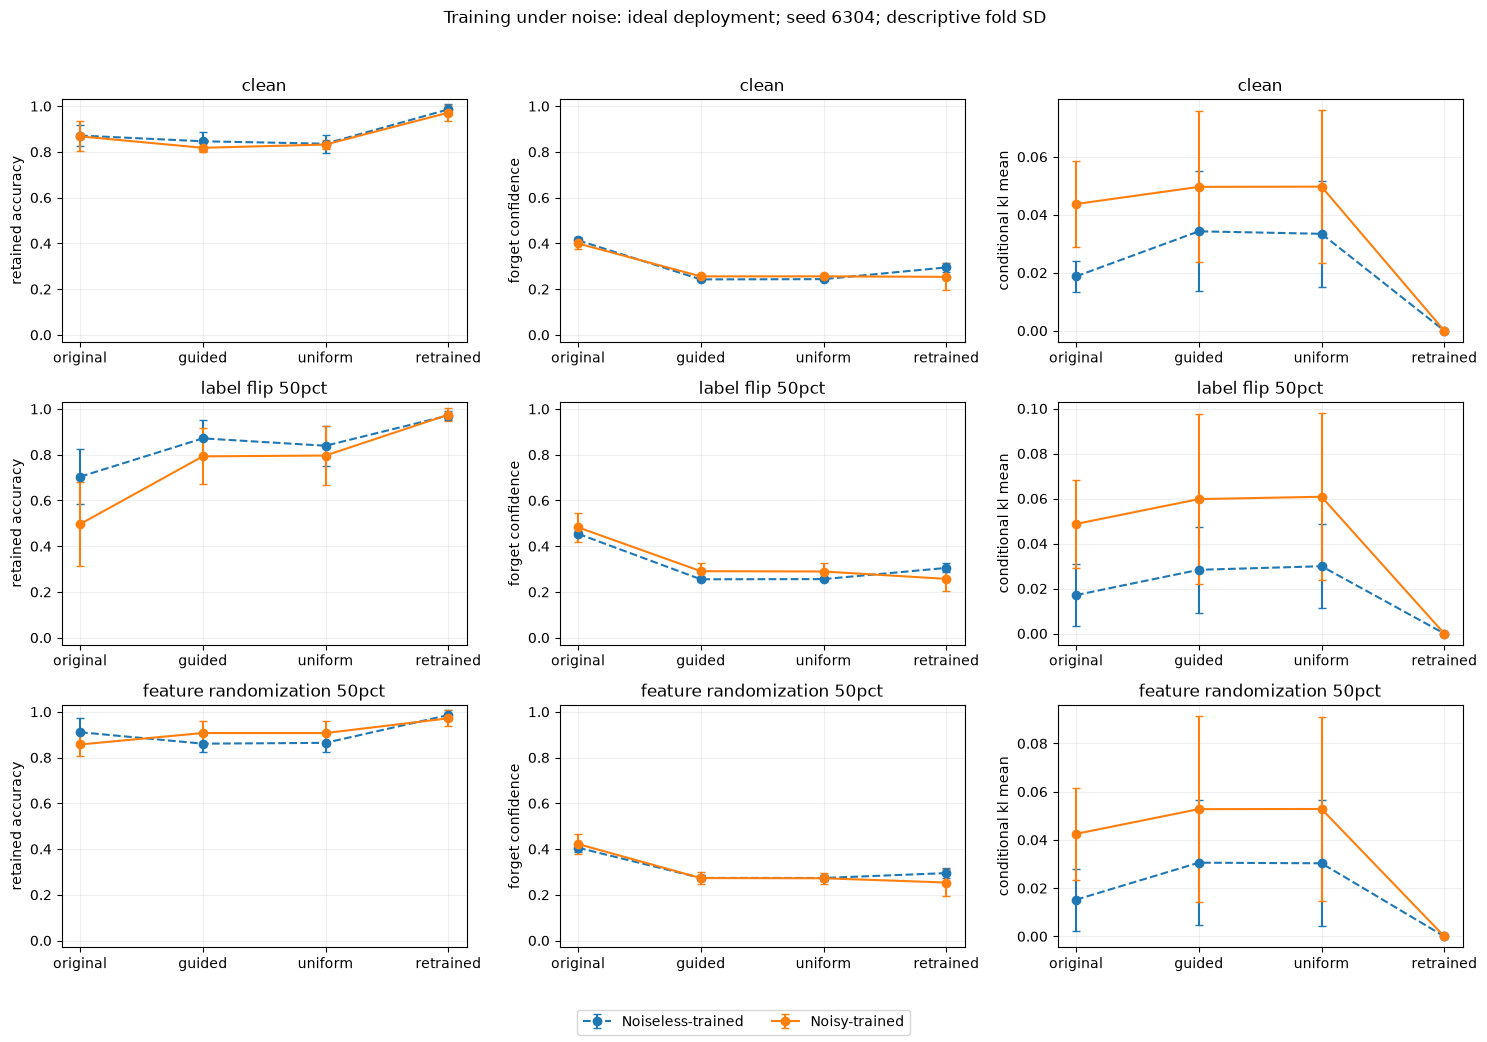

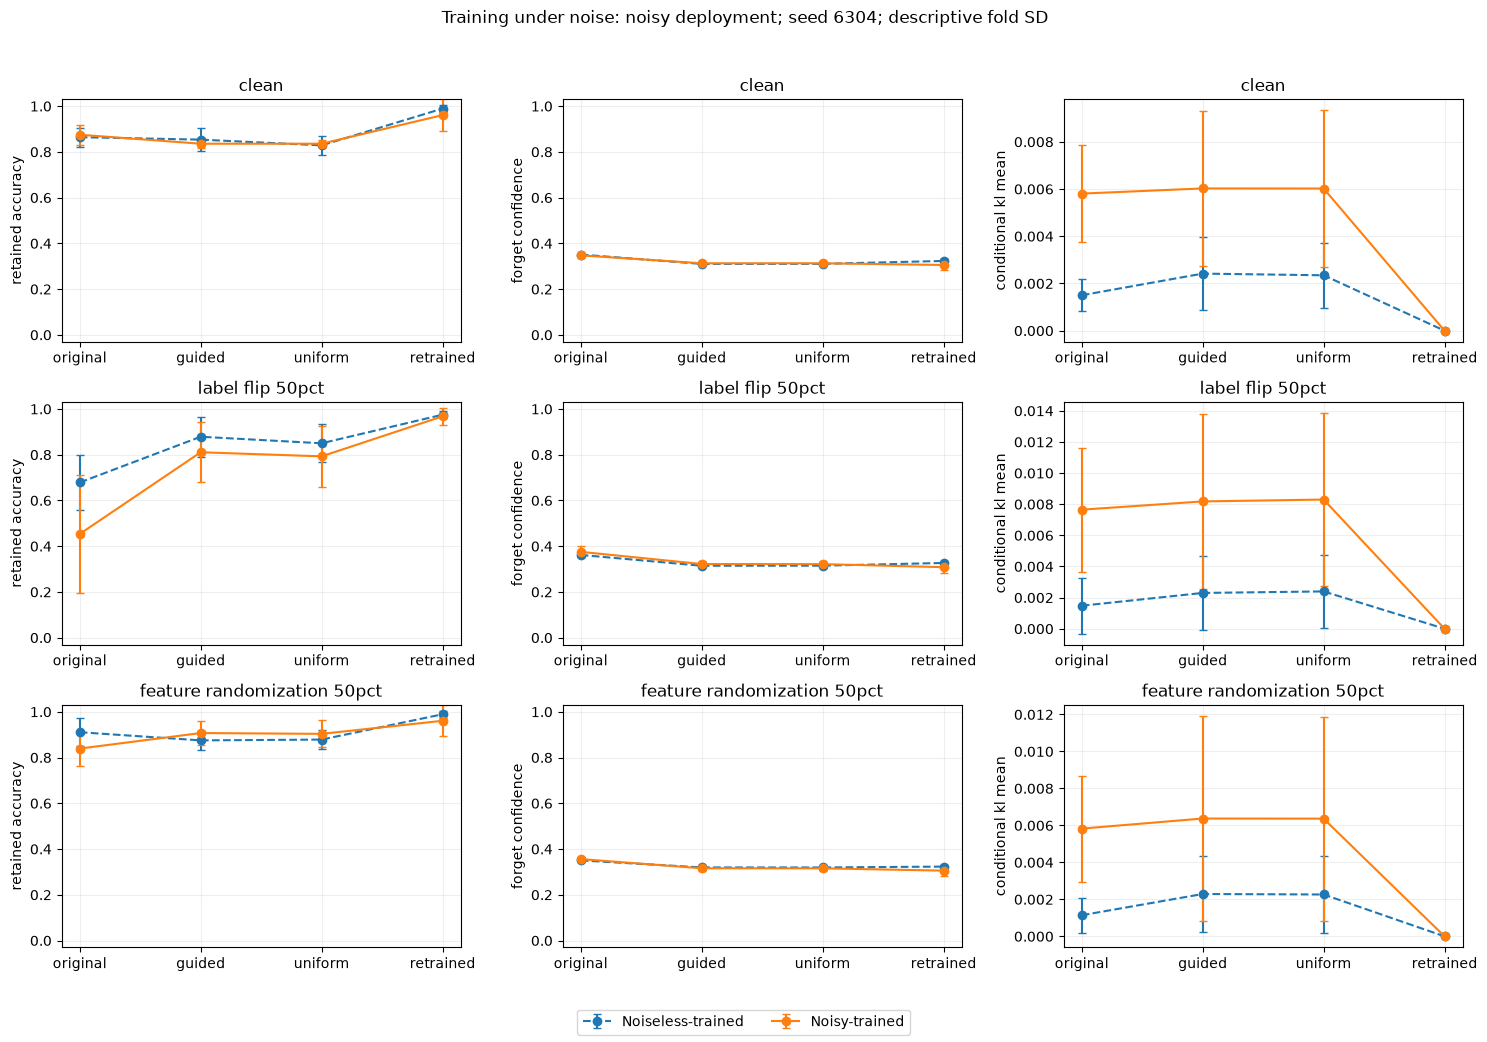

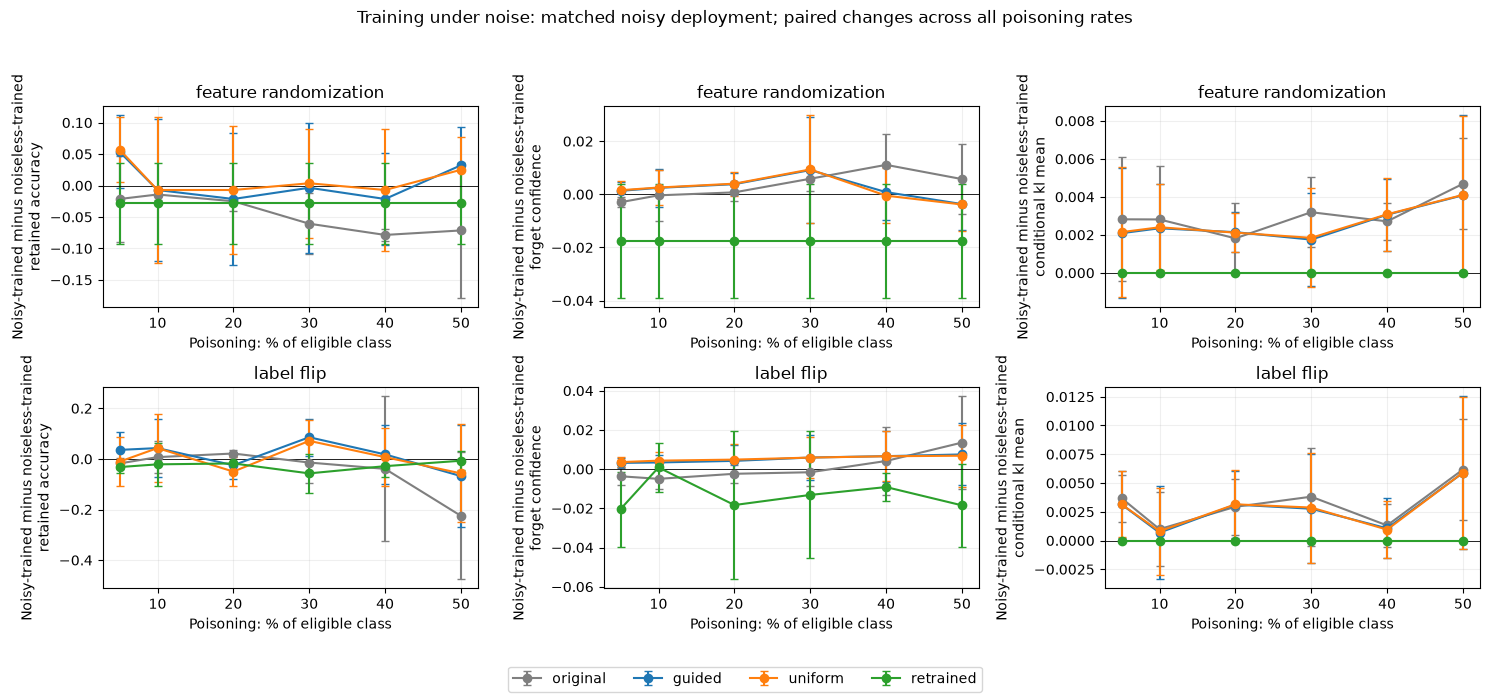

In [65]:
if "noisy_training" in extension_tables and not extension_tables["noisy_training"]["summary"].empty:
    extension_figures["noisy_training"] = noisy_training_analysis.noisy_training_figures(extension_tables["noisy_training"])
    for figure in extension_figures["noisy_training"].values():
        display(figure)
        plt.close(figure)


## 13. Optional IBM execution

Local Aer is sufficient for this protocol. IBM execution is disabled and no
account access is required. Hardware jobs need a separately declared backend,
finite shots, and explicit authorization; no hardware results are implied here.


In [66]:
if USE_IBM_HARDWARE:
    raise RuntimeError("Declare a separate hardware protocol before enabling IBM execution.")
print("Primary protocol: local Aer simulation or saved-results review.")


Primary protocol: local Aer simulation or saved-results review.


## 14. Exports, provenance, and interpretation

### 14.1 Coverage and checkpoint roles

The gold reference is clean three-class training. Retained-data retraining
references remove the exact forget set. Original, guided, uniform, and
retraining roles link to immutable completed model artifacts. Missing extension
studies remain visibly missing and do not invalidate an independently complete
primary study.


In [67]:
display(tables["resources"].round(3))
display(fold_summary.groupby("complete_folds").size().rename("metric_rows").to_frame())
study_paths = {"primary": study.report_path, "ablations": ablation_index,
               "fixed_weight_noise": noise_index, "noisy_training": noisy_index}
display(pd.DataFrame([{"study": name, "index": path.relative_to(PROJECT_ROOT).as_posix() if path else None}
                      for name, path in study_paths.items()]))


,run_id,first_role,actual_device,training_seconds,compiled_depth,two_qubit_gates,imported_from,circuit_evaluations,jobs,shots
0,none_p0_seed6304_fold0_3a9d03208c2974d8,clean,GPU,321.538,66,48,None,445500,363,0
1,none_p0_seed6304_fold0_a4438ecb8cfae905,retrained_clean,GPU,301.898,66,48,None,442028,363,0
2,none_p0_seed6304_fold0_70cec1774dedfc31,clean_guided,GPU,220.781,66,48,None,291647,225,0
3,none_p0_seed6304_fold0_a107614cc355fb3e,clean_uniform,GPU,201.809,66,48,None,291647,225,0
4,none_p0_seed6304_fold0_5a92c7b85c0ff3e1,poisoned,GPU,282.199,66,48,None,445500,363,0
...,...,...,...,...,...,...,...,...,...,...
225,none_p0_seed6304_fold4_f12ae165fbf97365,poisoned_uniform,GPU,195.284,66,48,None,292010,225,0
226,none_p0_seed6304_fold4_e27c14d94cf3ef7e,poisoned,GPU,322.865,66,48,None,445500,363,0
227,none_p0_seed6304_fold4_2e5b550a23c24d17,retrained_poisoned,GPU,173.848,66,48,None,441904,363,0
228,none_p0_seed6304_fold4_6406558f412a7860,poisoned_guided,GPU,179.642,66,48,None,291679,225,0


,metric_rows
complete_folds,
True,1612


,study,index
0,primary,results/fresh_studies/fa1604cdd38207d9/study.json
1,ablations,results/ablations/e4a96e40f818e487/study.json
2,fixed_weight_noise,results/noise_studies/11aa94ebc456b91d/study.json
3,noisy_training,results/noisy_training/9b54f30ef300facf/study....


### 14.2 Preserve original training provenance

The machine displaying results may differ from the machine that trained them.
Recorded source hashes, device, execution, environment, and original paths stay
unchanged. The current review has its own source fingerprint and output folder.


In [68]:
display(workflow.provenance_table(study, environment))
analysis_directory = workflow.review_directory(study)
print("Review exports:", analysis_directory.relative_to(PROJECT_ROOT))


,role,source,environment,execution
0,original training,9ee43bb2d743ea089d853663cca11b0377911e525a2568...,"{'aer_devices': ['CPU', 'GPU'], 'aer_runtime_v...","{'circuit_batch_size': 32768, 'device': 'GPU',..."
1,current review,22b973f1b3bcc1c11adb6b3099aa2c9ae9f911c15ad2de...,"{'python': '3.12.14', 'platform': 'Windows-11-...",saved arrays only; no predictions


Review exports: results\reviews\91030566c9f59d45


### 14.3 Save tables and all displayed figures


In [69]:
if EXPORT_ANALYSIS:
    fresh_analysis.export_study(primary_study, tables, figures, input_effects,
                                destination=analysis_directory / "primary")
    if "ablations" in extension_tables:
        ablation_analysis.export_study(ablation_index, PROJECT_ROOT,
            extension_figures.get("ablations"), tables=extension_tables["ablations"],
            destination=analysis_directory / "ablations")
    if "noise_studies" in extension_tables:
        noise_analysis.export_noise_study(noise_index, PROJECT_ROOT,
            extension_figures.get("noise_studies"), tables=extension_tables["noise_studies"],
            destination=analysis_directory / "fixed_weight_noise")
    if "noisy_training" in extension_tables:
        noisy_training_analysis.export_noisy_training(noisy_index, PROJECT_ROOT,
            extension_figures.get("noisy_training"), tables=extension_tables["noisy_training"],
            destination=analysis_directory / "noisy_training")
    print("Analysis exports saved.")


Analysis exports saved.


### 14.4 Link indexes and record this review


In [70]:
if EXPORT_ANALYSIS:
    artifacts.save_json(analysis_directory / "review.json", {
        "studies": {name: path.relative_to(PROJECT_ROOT).as_posix() if path else None
                    for name, path in study_paths.items()},
        "original_training_protocol": study.index["protocol"],
        "current_source_fingerprint": artifacts.source_fingerprint(),
        "current_environment": environment,
        "saved_results_only": SAVED_RESULTS_ONLY,
        "planned_folds": STUDY_FOLDS, "seed": SEED,
    })


### 14.5 What can we conclude?

First establish the original poisoning effect. Then compare guided and uniform
unlearning using within-fold changes in retained accuracy, digit-2 recall and
confidence, and both retraining KL definitions. Check whether the pattern is
consistent across folds and parameter values. Noise robustness and noisy
optimization answer different questions and must be reported separately.

Record the observed direction, effect size, fold coverage, and limitations
after inspecting actual restored results. No conclusion is prefilled. This
single-seed study does not certify deletion or universal quantum superiority.


## 15. Phase 2: deferred

New targets, constraints, selective poisoned-record forgetting, and new
algorithms are outside the current evaluation. This cell is intentionally empty.
